# PHÂN TÍCH CHẤT LƯỢNG KHÔNG KHÍ (AQI) TẠI HÀ NỘI GIAI ĐOẠN 2022–2025

## Phần 1 — Giới thiệu đồ án

Đồ án sử dụng bốn file CSV trong `dataset/`, ghi nhận theo giờ từ 2022 đến hết tháng 6/2025. Mục tiêu là kiểm tra và tiền xử lý dữ liệu, trả lời bốn câu hỏi nghiên cứu bằng số liệu và biểu đồ, rồi sử dụng dữ liệu đã xử lý để xây dựng hệ thống dự đoán AQI trung bình ngày tiếp theo trong notebook riêng. Năm 2025 chỉ có sáu tháng đầu; không xem đó là một năm đầy đủ. Đơn vị của các chỉ số chất ô nhiễm và nguồn trạm đo chưa được xác minh.

**Bốn câu hỏi nghiên cứu đã được xác nhận:**

1. Chỉ số AQI tại Hà Nội thay đổi như thế nào giữa các năm trong nửa đầu và nửa cuối năm?
2. AQI tại Hà Nội có xuất hiện mẫu hình theo tháng và mùa nhất quán qua các năm hay không?
3. PM2.5, PM10, CO, NO2, O3 và SO2 có mối liên hệ như thế nào với AQI?
4. Nhiệt độ, độ ẩm, lượng mưa và tốc độ gió có mối liên hệ như thế nào với AQI?

Notebook này chỉ bắt đầu bằng **Giai đoạn 1: Data Understanding**. Các phần làm sạch, EDA và trả lời câu hỏi sẽ được bổ sung sau khi giai đoạn tương ứng được xác nhận. Dữ liệu gốc và notebook mẫu luôn được giữ nguyên.


### Bước 1.1 — Import thư viện

**Mục tiêu:** Chuẩn bị các thư viện phân tích.

**Lý do:** Cần xác nhận công cụ và phiên bản trước khi xử lý.

**Phương pháp:** Import pandas, NumPy, Matplotlib, Seaborn; in phiên bản.

**Kết quả cần quan sát:** Các import thành công và phiên bản được hiển thị.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
print('Python:', sys.version.split()[0])
for name, module in [('pandas', pd), ('NumPy', np), ('Matplotlib', matplotlib), ('Seaborn', sns)]:
    print(f'{name}: {module.__version__}')

Python: 3.14.7
pandas: 3.1.1
NumPy: 2.5.5
Matplotlib: 3.11.2
Seaborn: 0.13.2


### Kết luận bước 1.1

Các thư viện đã import thành công trong Python 3.14.7: pandas 3.1.1, NumPy 2.5.5, Matplotlib 3.11.2 và Seaborn 0.13.2. Chưa phát hiện lỗi import; tiếp tục kiểm tra đường dẫn dữ liệu.

### Bước 1.2 — Kiểm tra đường dẫn

**Mục tiêu:** Xác định bốn file dữ liệu.

**Lý do:** Tránh đọc nhầm hoặc thiếu file.

**Phương pháp:** Dùng pathlib kiểm tra đường dẫn tương đối, tồn tại và kích thước.

**Kết quả cần quan sát:** Cả bốn file tồn tại và khác rỗng.

In [2]:
project_root = Path.cwd().resolve()
if not (project_root / 'dataset').is_dir():
    project_root = project_root.parent
data_dir = project_root / 'dataset'
file_paths = {year: data_dir / f'{year}.csv' for year in (2022, 2023, 2024, 2025)}
for year, path in file_paths.items():
    print(year, path.relative_to(project_root), 'exists=', path.is_file(), 'bytes=', path.stat().st_size if path.is_file() else None)
assert all(path.is_file() and path.stat().st_size > 0 for path in file_paths.values())

2022 dataset\2022.csv exists= True bytes= 1112039
2023 dataset\2023.csv exists= True bytes= 1132940
2024 dataset\2024.csv exists= True bytes= 1138974
2025 dataset\2025.csv exists= True bytes= 564112


### Kết luận bước 1.2

Cả bốn file dataset/2022.csv đến dataset/2025.csv đều tồn tại và có dung lượng lần lượt 1.112.039, 1.132.940, 1.138.974 và 564.112 byte. Đường dẫn tương đối hoạt động từ project; tiếp tục đọc CSV ở chế độ chỉ đọc.

### Bước 1.3 — Đọc bốn CSV

**Mục tiêu:** Đọc bốn CSV vào bộ nhớ.

**Lý do:** Cần DataFrame để khảo sát mà không sửa CSV gốc.

**Phương pháp:** Dùng pandas.read_csv cho từng năm.

**Kết quả cần quan sát:** Bốn DataFrame và số dòng đọc được.

In [3]:
raw_dfs = {year: pd.read_csv(path) for year, path in file_paths.items()}
for year, df in raw_dfs.items():
    print(year, 'DataFrame=', isinstance(df, pd.DataFrame), 'rows=', len(df))

2022 DataFrame= True rows= 8472
2023 DataFrame= True rows= 8736
2024 DataFrame= True rows= 8788
2025 DataFrame= True rows= 4345


### Kết luận bước 1.3

pandas.read_csv đọc thành công cả bốn file thành DataFrame: 2022 có 8.472 dòng, 2023 có 8.736, 2024 có 8.788 và 2025 có 4.345. Chưa biến đổi hay ghi lại dữ liệu gốc; tiếp tục kiểm tra số cột và tổng quy mô.

### Bước 1.4 — Kiểm tra kích thước

**Mục tiêu:** Đếm dòng và cột của mỗi file.

**Lý do:** Quy mô và độ bao phủ có thể khác nhau.

**Phương pháp:** Dùng DataFrame.shape và tính tổng dòng.

**Kết quả cần quan sát:** Bảng kích thước và tổng dòng.

In [4]:
shape_table = pd.DataFrame([{'year': year, 'rows': df.shape[0], 'columns': df.shape[1]} for year, df in raw_dfs.items()])
print(shape_table.to_string(index=False))
print('Total rows:', shape_table['rows'].sum())

 year  rows  columns
 2022  8472       19
 2023  8736       19
 2024  8788       19
 2025  4345       19
Total rows: 30341


### Kết luận bước 1.4

Mỗi file có 19 cột; tổng cộng 30.341 dòng trước xử lý. Số dòng khác nhau giữa các năm cần được đối chiếu với phạm vi thời gian, đặc biệt 2025 chưa đủ năm. Tiếp tục kiểm tra tên cột.

### Bước 1.5 — Kiểm tra tên cột

**Mục tiêu:** So sánh tên cột giữa bốn năm.

**Lý do:** Tên cột lệch sẽ gây lỗi khi ghép.

**Phương pháp:** So danh sách cột của từng năm với 2022.

**Kết quả cần quan sát:** Các tên cột khác biệt được liệt kê.

In [5]:
base = list(raw_dfs[2022].columns)
for year, df in raw_dfs.items():
    print(year, 'same ordered schema=', list(df.columns) == base)
    print('  ', list(df.columns))
    print('  only vs 2022=', sorted(set(df.columns) - set(base)))

2022 same ordered schema= True
   ['Local Time', 'UTC Time', 'City', 'Country Code', 'Timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
  only vs 2022= []
2023 same ordered schema= False
   ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
  only vs 2022= ['Country code', 'timezone']
2024 same ordered schema= False
   ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
  only vs 2022= ['Country code', 'timezone']
2025 same ordered schema= False
   ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', '

### Kết luận bước 1.5

Thứ tự 19 cột tương ứng giữa các năm, nhưng 2023–2025 dùng Country code và timezone trong khi 2022 dùng Country Code và Timezone. Nếu ghép ngay, pandas sẽ tạo cột tách biệt; cần chuẩn hóa tên ở Giai đoạn 2, chưa thực hiện ở đây.

### Bước 1.6 — Kiểm tra kiểu dữ liệu

**Mục tiêu:** Xác định kiểu dữ liệu do pandas suy luận.

**Lý do:** Thời gian và số có thể cần chuyển kiểu trước phân tích.

**Phương pháp:** In DataFrame.dtypes của từng năm.

**Kết quả cần quan sát:** Kiểu của từng cột theo năm.

In [6]:
for year, df in raw_dfs.items():
    print('YEAR', year)
    print(df.dtypes.to_string())

YEAR 2022
Local Time               str
UTC Time                 str
City                     str
Country Code             str
Timezone                 str
AQI                  float64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               int64
Relative Humidity      int64
Temperature          float64
UV Index             float64
Wind Speed           float64
YEAR 2023
Local Time               str
UTC Time                 str
City                     str
Country code             str
timezone                 str
AQI                    int64
CO                   float64
NO2                  float64
O3                   float64
PM10                 float64
PM25                 float64
SO2                  float64
Clouds                 int64
Precipitation        float64
Pressure               

### Kết luận bước 1.6

Pandas đọc Local Time, UTC Time và ba cột định danh ở dạng str, nên thời gian chưa thể dùng trực tiếp cho phép tính chuỗi thời gian. AQI là float64 ở 2022 nhưng int64 ở 2023–2025; các chất ô nhiễm là float64, còn Clouds, Pressure và Relative Humidity là int64. Cần chuyển thời gian và thống nhất kiểu khi tiền xử lý; hiện chưa thay đổi dữ liệu.

### Bước 1.7 — Xem đầu và cuối file

**Mục tiêu:** Xem mẫu ở đầu và cuối mỗi file.

**Lý do:** Ranh giới thời gian cần được đối chiếu với tên năm.

**Phương pháp:** Dùng head(2) và tail(2) cho thời gian, AQI, PM25.

**Kết quả cần quan sát:** Các bản ghi đầu và cuối từng file.

In [7]:
for year, df in raw_dfs.items():
    print('YEAR', year, 'FIRST')
    print(df[['Local Time','UTC Time','AQI','PM25']].head(2).to_string(index=False))
    print('LAST')
    print(df[['Local Time','UTC Time','AQI','PM25']].tail(2).to_string(index=False))

YEAR 2022 FIRST
         Local Time            UTC Time   AQI  PM25
2022-01-13 00:00:00 2022-01-12T17:00:00 180.0 77.67
2022-01-13 01:00:00 2022-01-12T18:00:00 181.0 79.00
LAST
         Local Time            UTC Time   AQI  PM25
2022-12-31 22:00:00 2022-12-31T15:00:00 201.0  94.0
2022-12-31 23:00:00 2022-12-31T16:00:00 164.0  66.0
YEAR 2023 FIRST
         Local Time            UTC Time  AQI  PM25
2023-01-01 00:00:00 2022-12-31T17:00:00  155  59.0
2023-01-01 01:00:00 2022-12-31T18:00:00  171  71.0
LAST
         Local Time            UTC Time  AQI  PM25
2023-12-30 22:00:00 2023-12-30T15:00:00  211 211.0
2023-12-30 23:00:00 2023-12-30T16:00:00  169 169.0
YEAR 2024 FIRST
         Local Time            UTC Time  AQI  PM25
2024-01-01 00:00:00 2023-12-31T17:00:00  208  99.0
2024-01-01 01:00:00 2023-12-31T18:00:00  139  50.0
LAST
         Local Time            UTC Time  AQI  PM25
2024-12-31 22:00:00 2024-12-31T15:00:00  155 155.0
2024-12-31 23:00:00 2024-12-31T16:00:00  264 141.0
YEAR 2025 FIR

### Kết luận bước 1.7

Các dòng đầu/cuối xác nhận 2022 bắt đầu 13/01, 2023 kết thúc 30/12, 2024 bao phủ đến 31/12 và 2025 kết thúc 30/06. Ví dụ đầu 2022 Local Time 00:00 ứng với UTC 17:00 ngày trước. Đây chỉ là kiểm tra mẫu; cần kiểm tra toàn bộ mốc giờ ở bước 1.12.

### Bước 1.8 — Thống kê mô tả

**Mục tiêu:** Mô tả các cột số.

**Lý do:** Cần biết phạm vi và cực trị trước khi xử lý.

**Phương pháp:** Dùng describe với count, min, trung vị, max.

**Kết quả cần quan sát:** Bảng số quan sát và phạm vi theo năm.

In [8]:
numeric_cols = ['AQI','CO','NO2','O3','PM10','PM25','SO2','Clouds','Precipitation','Pressure','Relative Humidity','Temperature','UV Index','Wind Speed']
for year, df in raw_dfs.items():
    print('YEAR', year)
    print(df[numeric_cols].describe().loc[['count','min','50%','max']].round(2).to_string())

YEAR 2022
          AQI      CO     NO2      O3    PM10     PM25     SO2  Clouds  Precipitation  Pressure  Relative Humidity  Temperature  UV Index  Wind Speed
count  8470.0  8398.0  8398.0  8398.0  8470.0  8470.00  8398.0  8472.0         8472.0    8472.0             8472.0       8472.0    8472.0      8472.0
min      21.0    51.4     0.0     0.0     5.0     4.00     0.0     0.0            0.0     992.0               17.0          8.5       0.0         0.0
50%     107.0   176.4    17.3    55.3    49.0    37.67    44.7    75.0            0.0    1010.0               81.0         25.6       0.6         2.0
max     475.0  3002.0   152.0   244.0   579.0   416.00   206.0   100.0           28.0    1029.0              100.0         38.5      11.9         7.2
YEAR 2023


          AQI      CO     NO2      O3    PM10     PM25     SO2  Clouds  Precipitation  Pressure  Relative Humidity  Temperature  UV Index  Wind Speed
count  8736.0  8736.0  8736.0  8736.0  8736.0  8736.00  8736.0  8736.0        8736.00    8736.0             8736.0       8736.0    8736.0      8736.0
min      21.0     9.0     2.0     0.0     1.3     1.00     4.0     0.0           0.00     994.0               17.0          7.7       0.0         0.0
50%     112.0   173.1    18.0    55.0    50.0    39.42    76.5    79.0           0.00    1009.0               81.0         26.0       0.6         1.6
max     487.0  9160.0   378.0   262.0   591.0   446.00   368.0   100.0          22.75    1033.0              100.0         40.0      12.1         6.0
YEAR 2024
          AQI        CO     NO2      O3    PM10     PM25     SO2  Clouds  Precipitation  Pressure  Relative Humidity  Temperature  UV Index  Wind Speed
count  8788.0   8788.00  8788.0  8788.0  8788.0  8788.00  8788.0  8788.0        8788.00 

          AQI      CO     NO2      O3    PM10    PM25     SO2  Clouds  Precipitation  Pressure  Relative Humidity  Temperature  UV Index  Wind Speed
count  4345.0  4345.0  4345.0  4345.0  4345.0  4345.0  4345.0  4345.0        4345.00    4345.0             4345.0       4345.0    4345.0      4345.0
min      22.0    10.0     3.0     0.0     6.0     4.0     1.0     0.0           0.00     996.0               21.0          7.0       0.0         0.0
50%     136.0    98.0    21.3    60.0    67.5    48.0    56.7    91.0           0.00    1011.0               82.0         23.4       0.6         2.0
max     470.0  4133.0   357.0   648.6   574.0   457.0   721.0   100.0          15.25    1033.0              100.0         39.6      10.8         6.2


### Kết luận bước 1.8

Thống kê mô tả xác nhận số quan sát AQI 2022 là 8.470 trên 8.472 dòng, trong khi 2023–2025 đủ theo từng file. Trung vị AQI lần lượt là 107, 112, 105 và 136; đây chỉ là mô tả thô, chưa dùng để so sánh năm vì độ bao phủ khác nhau. Cực trị đáng kiểm tra gồm AQI tối đa 500, CO 15.956,2, O3 700 và PM10 1.103 ở 2024; chưa tự kết luận giá trị sai.

### Bước 1.9 — Kiểm tra giá trị thiếu

**Mục tiêu:** Đếm giá trị thiếu theo cột.

**Lý do:** Không chọn cách điền trước khi biết mức độ và vị trí thiếu.

**Phương pháp:** Dùng isna().sum() và lọc thời gian dòng thiếu.

**Kết quả cần quan sát:** Số ô, tỷ lệ và khoảng thời gian thiếu.

In [9]:
for year, df in raw_dfs.items():
    counts = df.isna().sum()
    missing = counts[counts > 0]
    print('YEAR', year, 'missing cells=', int(counts.sum()))
    print(missing.to_string() if len(missing) else 'none')
    for col in missing.index:
        dates = df.loc[df[col].isna(), 'Local Time']
        print(col, 'pct=', round(100*missing[col]/len(df), 3), 'first=', dates.iloc[0], 'last=', dates.iloc[-1])

YEAR 2022 missing cells= 302
AQI      2
CO      74
NO2     74
O3      74
PM10     2
PM25     2
SO2     74
AQI pct= 0.024 first= 2022-07-01 06:00:00 last= 2022-07-01 07:00:00


CO pct= 0.873 first= 2022-06-30 05:00:00 last= 2022-07-03 06:00:00
NO2 pct= 0.873 first= 2022-06-30 05:00:00 last= 2022-07-03 06:00:00
O3 pct= 0.873 first= 2022-06-30 05:00:00 last= 2022-07-03 06:00:00
PM10 pct= 0.024 first= 2022-07-01 06:00:00 last= 2022-07-01 07:00:00
PM25 pct= 0.024 first= 2022-07-01 06:00:00 last= 2022-07-01 07:00:00
SO2 pct= 0.873 first= 2022-06-30 05:00:00 last= 2022-07-03 06:00:00
YEAR 2023 missing cells= 0
none
YEAR 2024 missing cells= 0
none
YEAR 2025 missing cells= 0
none


### Kết luận bước 1.9

Chỉ 2022 có ô thiếu: tổng 302 ô. AQI, PM10 và PM25 thiếu 2 giờ tại 01/07 06:00–07:00 (0,024% mỗi cột); CO, NO2, O3 và SO2 cùng thiếu 74 giờ từ 30/06 05:00 đến 03/07 06:00 (0,873% mỗi cột). Các file 2023–2025 không có ô thiếu. Cụm 74 giờ cần đánh giá riêng ở Giai đoạn 2, không tự điền tiến/lùi.

### Bước 1.10 — Kiểm tra dòng trùng hoàn toàn

**Mục tiêu:** Đếm dòng trùng hoàn toàn.

**Lý do:** Trùng cả dòng khác với trùng thời điểm.

**Phương pháp:** Dùng DataFrame.duplicated().

**Kết quả cần quan sát:** Số dòng trùng từng năm.

In [10]:
for year, df in raw_dfs.items():
    print(year, 'exact duplicate rows=', int(df.duplicated().sum()))

2022 exact duplicate rows= 0
2023 exact duplicate rows= 0


2024 exact duplicate rows= 0
2025 exact duplicate rows= 0


### Kết luận bước 1.10

Không file nào có dòng trùng hoàn toàn theo toàn bộ 19 cột. Kết quả này không loại trừ nhiều bản ghi tại cùng một giờ; tiếp tục kiểm tra Local Time ở bước 1.11.

### Bước 1.11 — Kiểm tra giờ trùng và xung đột

**Mục tiêu:** Tìm mốc giờ có nhiều bản ghi.

**Lý do:** Hai dòng cùng giờ có thể chứa giá trị xung đột.

**Phương pháp:** Dùng duplicated trên Local Time, groupby để so cột.

**Kết quả cần quan sát:** Các mốc giờ lặp và cột khác nhau.

In [11]:
for year, df in raw_dfs.items():
    repeats = df[df['Local Time'].duplicated(keep=False)]
    print('YEAR', year, 'repeated rows=', len(repeats), 'repeated hours=', repeats['Local Time'].nunique())
    for hour, group in repeats.groupby('Local Time', sort=True):
        changed = [c for c in df.columns if group[c].nunique(dropna=False) > 1]
        print(hour, 'changed columns=', changed)
        print(group[['AQI','CO','NO2','O3','PM10','PM25','SO2']].to_string(index=False))

YEAR 2022 repeated rows= 0 repeated hours= 0
YEAR 2023 repeated rows= 0 repeated hours= 0
YEAR 2024 repeated rows= 8 repeated hours= 4
2024-03-01 00:00:00 changed columns= ['O3', 'SO2']
 AQI    CO  NO2   O3  PM10  PM25  SO2
  31 216.0 12.5 27.8   7.5   7.5 38.4
  31 216.0 12.5 33.7   7.5   7.5 35.8
2024-04-01 00:00:00 changed columns= ['SO2']
 AQI    CO  NO2   O3  PM10  PM25  SO2
 150 214.0 18.5 29.2  83.0  55.5 30.3
 150 214.0 18.5 29.2  83.0  55.5 20.0
2024-11-01 00:00:00 changed columns= ['CO', 'NO2', 'O3', 'SO2']
 AQI     CO  NO2   O3  PM10  PM25   SO2
 178 1464.7 20.7 18.6 222.5 178.0  81.0
 178  454.8 29.3 27.3 222.5 178.0 119.7
2024-12-01 00:00:00 changed columns= ['AQI', 'PM10', 'PM25']
 AQI    CO  NO2   O3  PM10  PM25  SO2
 165 164.4 19.3 63.7  71.3 66.67 66.3
 173 164.4 19.3 63.7  81.0 72.33 66.3
YEAR 2025 repeated rows= 2 repeated hours= 1
2025-05-01 00:00:00 changed columns= ['CO', 'O3', 'SO2']
 AQI    CO  NO2   O3  PM10  PM25   SO2
 157 393.7 37.0 32.1  76.3  61.0 288.0
 1

### Kết luận bước 1.11

2022 và 2023 không có giờ lặp. 2024 có 4 giờ lặp (8 dòng) và 2025 có 1 giờ lặp (2 dòng); cả 5 cặp đều khác nhau ít nhất một cột, nên drop_duplicates trên toàn dòng không xử lý được. Đặc biệt 01/12/2024 00:00 có AQI 165 và 173; các cặp còn lại khác O3, SO2 hoặc CO/NO2. Chưa chọn bản ghi nào; Giai đoạn 2 phải xét từng cặp và ghi ảnh hưởng của quy tắc chọn.

### Bước 1.12 — Kiểm tra phạm vi và tính liên tục thời gian

**Mục tiêu:** Kiểm tra phạm vi và tính liên tục thời gian.

**Lý do:** Khoảng thiếu ảnh hưởng so sánh và dự đoán.

**Phương pháp:** Chuyển thời gian trên biến tạm, đối chiếu date_range và UTC+7.

**Kết quả cần quan sát:** Giờ đầu/cuối, giờ thiếu, thời gian lỗi, sai lệch UTC.

In [12]:
all_hours = []
for year, df in raw_dfs.items():
    local = pd.to_datetime(df['Local Time'], errors='coerce')
    utc = pd.to_datetime(df['UTC Time'], errors='coerce', utc=True)
    local_utc = local.dt.tz_localize('Asia/Ho_Chi_Minh').dt.tz_convert('UTC')
    unique = pd.DatetimeIndex(local.dropna().unique()).sort_values()
    expected = pd.date_range(unique.min(), unique.max(), freq='h')
    missing = expected.difference(unique)
    print(year, 'first=', unique.min(), 'last=', unique.max(), 'unique hours=', len(unique), 'internal missing=', len(missing), 'invalid local=', int(local.isna().sum()), 'UTC mismatch=', int((local_utc != utc).sum()))
    all_hours.extend(unique.tolist())
combined = pd.DatetimeIndex(all_hours).unique().sort_values()
missing_all = pd.date_range(combined.min(), combined.max(), freq='h').difference(combined)
print('COMBINED unique hours=', len(combined), 'internal missing=', len(missing_all), 'first missing=', missing_all.min() if len(missing_all) else None, 'last missing=', missing_all.max() if len(missing_all) else None)

2022 first= 2022-01-13 00:00:00 last= 2022-12-31 23:00:00 unique hours= 8472 internal missing= 0 invalid local= 0 UTC mismatch= 0
2023 first= 2023-01-01 00:00:00 last= 2023-12-30 23:00:00 unique hours= 8736 internal missing= 0 invalid local= 0 UTC mismatch= 0


2024 first= 2024-01-01 00:00:00 last= 2024-12-31 23:00:00 unique hours= 8784 internal missing= 0 invalid local= 0 UTC mismatch= 0
2025 first= 2025-01-01 00:00:00 last= 2025-06-30 23:00:00 unique hours= 4344 internal missing= 0 invalid local= 0 UTC mismatch= 0


COMBINED unique hours= 30336 internal missing= 24 first missing= 2023-12-31 00:00:00 last missing= 2023-12-31 23:00:00


### Kết luận bước 1.12

Không có thời gian địa phương không đọc được hoặc sai lệch giữa Local Time và UTC Time ở bất kỳ năm nào. Trong khoảng từng file, không thiếu giờ; số giờ duy nhất là 8.472, 8.736, 8.784 và 4.344. Gộp phạm vi từ 13/01/2022 đến 30/06/2025 có 30.336 giờ duy nhất và thiếu đúng 24 giờ của ngày 31/12/2023. Đầu 2022 và sau 30/06/2025 là ngoài phạm vi file, không được xem là giờ quan sát.

### Bước 1.13 — Kiểm tra giá trị bất thường

**Mục tiêu:** Gắn cờ giá trị bất thường.

**Lý do:** Cực trị cần xem xét trước khi diễn giải.

**Phương pháp:** Đếm AQI ngoài miền, số âm, giá trị 0/500 và tìm cực đại.

**Kết quả cần quan sát:** Số trường hợp và thời điểm cực đại; chưa sửa dữ liệu.

In [13]:
pollutants = ['CO','NO2','O3','PM10','PM25','SO2']
for year, df in raw_dfs.items():
    print(year, 'AQI outside 0..500=', int(((df['AQI'] < 0) | (df['AQI'] > 500)).sum()), 'AQI=500=', int((df['AQI'] == 500).sum()), 'negative pollutants=', int((df[pollutants] < 0).sum().sum()), 'CO=0=', int((df['CO'] == 0).sum()), 'PM25>PM10=', int((df['PM25'] > df['PM10']).sum()))
    for col in ['CO','O3','PM10','SO2']:
        idx = df[col].idxmax()
        print(' ', col, 'max=', df.at[idx,col], 'at', df.at[idx,'Local Time'])

2022 AQI outside 0..500= 0 AQI=500= 0 negative pollutants= 0 CO=0= 0 PM25>PM10= 0
  CO max= 3002.0 at 2022-12-25 10:00:00
  O3 max= 244.0 at 2022-09-14 16:00:00
  PM10 max= 579.0 at 2022-04-08 04:00:00
  SO2 max= 206.0 at 2022-07-06 16:00:00
2023 AQI outside 0..500= 0 AQI=500= 0 negative pollutants= 0 CO=0= 0 PM25>PM10= 4
  CO max= 9160.0 at 2023-11-18 00:00:00
  O3 max= 262.0 at 2023-03-23 16:00:00
  PM10 max= 591.0 at 2023-11-19 20:00:00
  SO2 max= 368.0 at 2023-08-02 10:00:00


2024 AQI outside 0..500= 0 AQI=500= 59 negative pollutants= 0 CO=0= 3 PM25>PM10= 50
  CO max= 15956.2 at 2024-03-06 01:00:00
  O3 max= 700.0 at 2024-08-17 07:00:00
  PM10 max= 1103.0 at 2024-04-11 18:00:00
  SO2 max= 400.0 at 2024-09-15 07:00:00
2025 AQI outside 0..500= 0 AQI=500= 0 negative pollutants= 0 CO=0= 0 PM25>PM10= 15
  CO max= 4133.0 at 2025-06-11 05:00:00
  O3 max= 648.6 at 2025-03-14 00:00:00
  PM10 max= 574.0 at 2025-02-11 15:00:00
  SO2 max= 721.0 at 2025-04-23 13:00:00


### Kết luận bước 1.13

Không có AQI ngoài 0–500 hoặc chỉ số chất ô nhiễm âm trong bốn file. Năm 2024 có 59 dòng AQI = 500 và 3 dòng CO = 0. PM25 lớn hơn PM10 ở 4 dòng năm 2023, 50 dòng năm 2024 và 15 dòng năm 2025. Các cực đại cần xác minh gồm CO 15.956,2, O3 700 và PM10 1.103 ở 2024, SO2 721 ở 2025. Chưa có đơn vị và thông tin trạm để xác định giá trị nào sai; giữ nguyên dữ liệu, chuyển sang đánh giá ở Giai đoạn 2 sau khi được xác nhận.

### Bước 2.1 — Chuẩn hóa tên cột trên bản sao

**Mục tiêu:** Tạo schema thống nhất cho bốn năm.

**Lý do:** Tên khác nhau sẽ tách cột khi ghép; phải chuẩn hóa nhưng không sửa CSV gốc.

**Phương pháp:** Sao chép từng DataFrame và đổi hai cặp tên cột; so sánh danh sách cột.

**Kết quả cần quan sát:** Mỗi bản sao có 19 tên cột giống nhau.

In [14]:
rename_map = {'Country Code':'Country code', 'Timezone':'timezone'}
work_dfs = {year: df.rename(columns=rename_map).copy() for year, df in raw_dfs.items()}
base_columns = list(work_dfs[2022].columns)
for year, df in work_dfs.items():
    print(year, 'columns=', len(df.columns), 'same schema=', list(df.columns)==base_columns, 'rows=',len(df))
print('all columns:', base_columns)
assert all(list(df.columns)==base_columns for df in work_dfs.values())

2022 columns= 19 same schema= True rows= 8472
2023 columns= 19 same schema= True rows= 8736
2024 columns= 19 same schema= True rows= 8788
2025 columns= 19 same schema= True rows= 4345
all columns: ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']


### Kết luận bước 2.1

Sau khi đổi hai tên cột trên bản sao, cả bốn DataFrame có cùng 19 cột và số dòng vẫn là 8.472, 8.736, 8.788, 4.345. Không có giá trị nào bị thay đổi và CSV gốc vẫn nguyên. Tiếp tục chuyển kiểu trên các bản sao để kiểm tra thời gian và số.

### Bước 2.2 — Chuyển kiểu số và chuẩn hóa thời gian trên bản sao

**Mục tiêu:** Tạo kiểu dữ liệu nhất quán để kiểm tra.

**Lý do:** CSV chứa thời gian dạng chuỗi và AQI khác kiểu giữa các năm.

**Phương pháp:** Dùng to_numeric và to_datetime trên bản sao; đếm lỗi chuyển đổi và giá trị số thay đổi.

**Kết quả cần quan sát:** Không phát sinh NaN mới hoặc đổi giá trị số ngoài ý muốn.

In [15]:
numeric_cols = ['AQI','CO','NO2','O3','PM10','PM25','SO2','Clouds','Precipitation','Pressure','Relative Humidity','Temperature','UV Index','Wind Speed']
for year, df in work_dfs.items():
    before = df[numeric_cols].copy()
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce').astype('float64')
    df['Local Time'] = pd.to_datetime(df['Local Time'], errors='coerce')
    df['UTC Time'] = pd.to_datetime(df['UTC Time'], errors='coerce', utc=True)
    new_missing = int(df[numeric_cols].isna().sum().sum() - before.isna().sum().sum())
    changed = int((~np.isclose(df[numeric_cols].to_numpy(dtype=float), before.to_numpy(dtype=float), equal_nan=True)).sum())
    print(year, 'new numeric NaN=',new_missing,'numeric values changed=',changed,'bad local=',int(df['Local Time'].isna().sum()),'bad UTC=',int(df['UTC Time'].isna().sum()),'AQI dtype=',df['AQI'].dtype)
    assert new_missing==0 and changed==0 and df['Local Time'].notna().all() and df['UTC Time'].notna().all()

2022 new numeric NaN= 0 numeric values changed= 0 bad local= 0 bad UTC= 0 AQI dtype= float64
2023 new numeric NaN= 0 numeric values changed= 0 bad local= 0 bad UTC= 0 AQI dtype= float64


2024 new numeric NaN= 0 numeric values changed= 0 bad local= 0 bad UTC= 0 AQI dtype= float64
2025 new numeric NaN= 0 numeric values changed= 0 bad local= 0 bad UTC= 0 AQI dtype= float64


### Kết luận bước 2.2

Chuyển 14 cột số sang float64 và hai cột thời gian sang kiểu thời gian trên bản sao không tạo thêm NaN, không đổi giá trị số và không có mốc thời gian không đọc được ở cả bốn năm. AQI hiện cùng kiểu float64. Tiếp tục kiểm tra định danh và quan hệ Local Time–UTC Time trước khi xử lý giờ trùng.

### Bước 2.3 — Xác minh định danh và hai cột thời gian

**Mục tiêu:** Kiểm tra mọi dòng thuộc cùng thành phố và UTC khớp giờ địa phương.

**Lý do:** Sai định danh hoặc múi giờ có thể làm sai phân tích theo thời gian.

**Phương pháp:** Đếm giá trị định danh và đối chiếu Local Time quy đổi UTC với UTC Time.

**Kết quả cần quan sát:** Một giá trị nhất quán cho mỗi cột định danh và 0 mốc thời gian không khớp.

In [16]:
for year, df in work_dfs.items():
    local_as_utc = df['Local Time'].dt.tz_localize('Asia/Ho_Chi_Minh').dt.tz_convert('UTC')
    mismatch = int((local_as_utc != df['UTC Time']).sum())
    print(year, 'City=',df['City'].value_counts(dropna=False).to_dict(),'Country code=',df['Country code'].value_counts(dropna=False).to_dict(),'timezone=',df['timezone'].value_counts(dropna=False).to_dict(),'UTC mismatch=',mismatch)
    assert mismatch==0

2022 City= {'Hanoi': 8472} Country code= {'VN': 8472} timezone= {'Asia/Ho_Chi_Minh': 8472} UTC mismatch= 0
2023 City= {'Hanoi': 8736} Country code= {'VN': 8736} timezone= {'Asia/Ho_Chi_Minh': 8736} UTC mismatch= 0
2024 City= {'Hanoi': 8788} Country code= {'VN': 8788} timezone= {'Asia/Ho_Chi_Minh': 8788} UTC mismatch= 0
2025 City= {'Hanoi': 4345} Country code= {'VN': 4345} timezone= {'Asia/Ho_Chi_Minh': 4345} UTC mismatch= 0


### Kết luận bước 2.3

Toàn bộ 30.341 dòng có City = Hanoi, Country code = VN và timezone = Asia/Ho_Chi_Minh. Không có dòng nào lệch giữa Local Time quy đổi UTC+7 và UTC Time. Có thể dùng Local Time làm mốc giờ phân tích, nhưng năm cặp giờ trùng vẫn cần quyết định riêng.

### Bước 2.4 — Đối chiếu từng cặp giờ xung đột

**Mục tiêu:** Xác định chính xác cột và giá trị khác nhau của 5 cặp.

**Lý do:** Không thể chọn bản ghi đúng chỉ bằng kiểm tra dòng trùng hoàn toàn.

**Phương pháp:** Nhóm theo Local Time khi giờ xuất hiện hai lần; in từng cặp và cột khác.

**Kết quả cần quan sát:** Danh sách 5 cặp, các chỉ số khác và mức chênh.

In [17]:
conflicts = []
for year, df in work_dfs.items():
    repeated = df[df['Local Time'].duplicated(keep=False)]
    for hour, pair in repeated.groupby('Local Time', sort=True):
        assert len(pair)==2
        a,b = pair.iloc[0],pair.iloc[1]
        different = [c for c in df.columns if not (pd.isna(a[c]) and pd.isna(b[c])) and a[c]!=b[c]]
        print('YEAR',year,'HOUR',hour,'source row numbers=',list(pair.index+2))
        print('different:',[(c,a[c],b[c],round(float(b[c]-a[c]),2) if c in numeric_cols else None) for c in different])
        conflicts.append({'year':year,'hour':hour,'rows':list(pair.index+2),'different':different,'first':a,'last':b})
print('total conflict hours=',len(conflicts))
assert len(conflicts)==5

YEAR 2024 HOUR 2024-03-01 00:00:00 source row numbers= [1442, 1443]
different: [('O3', np.float64(27.8), np.float64(33.7), 5.9), ('SO2', np.float64(38.4), np.float64(35.8), -2.6)]
YEAR 2024 HOUR 2024-04-01 00:00:00 source row numbers= [2187, 2188]
different: [('SO2', np.float64(30.3), np.float64(20.0), -10.3)]
YEAR 2024 HOUR 2024-11-01 00:00:00 source row numbers= [7324, 7325]
different: [('CO', np.float64(1464.7), np.float64(454.8), -1009.9), ('NO2', np.float64(20.7), np.float64(29.3), 8.6), ('O3', np.float64(18.6), np.float64(27.3), 8.7), ('SO2', np.float64(81.0), np.float64(119.7), 38.7)]
YEAR 2024 HOUR 2024-12-01 00:00:00 source row numbers= [8045, 8046]
different: [('AQI', np.float64(165.0), np.float64(173.0), 8.0), ('PM10', np.float64(71.3), np.float64(81.0), 9.7), ('PM25', np.float64(66.67), np.float64(72.33), 5.66)]


YEAR 2025 HOUR 2025-05-01 00:00:00 source row numbers= [2882, 2883]
different: [('CO', np.float64(393.7), np.float64(230.7), -163.0), ('O3', np.float64(32.1), np.float64(36.7), 4.6), ('SO2', np.float64(288.0), np.float64(73.7), -214.3)]
total conflict hours= 5


### Kết luận bước 2.4

Đã kiểm tra từng cặp: 01/03/2024 khác O3 và SO2; 01/04/2024 khác SO2; 01/11/2024 khác CO, NO2, O3, SO2; 01/12/2024 khác AQI (165 so với 173), PM10, PM25; 01/05/2025 khác CO, O3, SO2. Cả 5 giờ đều có đúng hai dòng, cùng định danh và thời gian nhưng chỉ số xung đột. CSV không có mã trạm hoặc cờ chất lượng để xác định dòng đúng; tiếp tục lượng hóa ảnh hưởng các lựa chọn, chưa loại hay gộp.

### Bước 2.5 — Đánh giá các phương án cho giờ xung đột

**Mục tiêu:** Đo ảnh hưởng của lựa chọn giữ dòng đầu, dòng cuối hoặc trung bình.

**Lý do:** Không có mã trạm hoặc cờ chất lượng để xác định bản ghi nào đúng.

**Phương pháp:** Tính khoảng chênh AQI và từng chất ô nhiễm cho 5 cặp; không áp dụng phương án nào.

**Kết quả cần quan sát:** Các lựa chọn, mức ảnh hưởng và quyết định cần xác nhận.

In [18]:
for item in conflicts:
    a,b = item['first'],item['last']
    print(item['year'],item['hour'],'rows',item['rows'])
    for col in item['different']:
        if col in numeric_cols:
            print(' ',col,'first=',a[col],'last=',b[col],'mean=',round((a[col]+b[col])/2,3),'absolute difference=',round(abs(a[col]-b[col]),3))
print('Options: first/last/mean each yield one hour but are unsupported by source metadata; keep both retains conflicting hours; exclude conflicting hours avoids arbitrary value but loses 5 hours. No option applied.')

2024 2024-03-01 00:00:00 rows [1442, 1443]
  O3 first= 27.8 last= 33.7 mean= 30.75 absolute difference= 5.9
  SO2 first= 38.4 last= 35.8 mean= 37.1 absolute difference= 2.6
2024 2024-04-01 00:00:00 rows [2187, 2188]
  SO2 first= 30.3 last= 20.0 mean= 25.15 absolute difference= 10.3
2024 2024-11-01 00:00:00 rows [7324, 7325]
  CO first= 1464.7 last= 454.8 mean= 959.75 absolute difference= 1009.9
  NO2 first= 20.7 last= 29.3 mean= 25.0 absolute difference= 8.6
  O3 first= 18.6 last= 27.3 mean= 22.95 absolute difference= 8.7
  SO2 first= 81.0 last= 119.7 mean= 100.35 absolute difference= 38.7
2024 2024-12-01 00:00:00 rows [8045, 8046]
  AQI first= 165.0 last= 173.0 mean= 169.0 absolute difference= 8.0
  PM10 first= 71.3 last= 81.0 mean= 76.15 absolute difference= 9.7
  PM25 first= 66.67 last= 72.33 mean= 69.5 absolute difference= 5.66
2025 2025-05-01 00:00:00 rows [2882, 2883]
  CO first= 393.7 last= 230.7 mean= 312.2 absolute difference= 163.0
  O3 first= 32.1 last= 36.7 mean= 34.4 absol

### Kết luận bước 2.5

Lựa chọn dòng đầu/cuối làm AQI tại 01/12/2024 khác 8 điểm (165 so với 173); lấy trung bình cho 169 nhưng không có chứng cứ đó là phép gộp đúng. Ở 01/11/2024, CO của hai dòng chênh 1.009,9; ở 01/05/2025, SO2 chênh 214,3. Giữ cả hai duy trì 5 giờ không duy nhất; bỏ cả cặp mất 5 giờ. Đề xuất cần xác nhận: giữ một mốc giờ cho mỗi cặp, giữ những cột hai dòng thống nhất và đặt NaN chỉ cho cột xung đột, kèm cờ nguồn; cách này không tự chọn giá trị thiếu căn cứ nhưng làm AQI thiếu thêm 1 giờ. Chưa áp dụng phương án nào và dừng tại đây theo yêu cầu xác nhận.

### Bước 2.6 — Giải quyết giờ xung đột và lưu kiểm toán

**Mục tiêu:** Áp dụng quy tắc đã được xác nhận cho đúng 5 cặp.

**Lý do:** Giữ giờ duy nhất mà không tự chọn giá trị bất đồng.

**Phương pháp:** Với từng cặp, giữ giá trị bằng nhau và đặt NaN ở cột khác nhau; ghi từng cột xung đột vào CSV kiểm toán.

**Kết quả cần quan sát:** Năm giờ được giải quyết, 13 dòng kiểm toán có thể truy vết.

In [19]:
resolved_dfs={}
audit_rows=[]
for year, df in work_dfs.items():
    singles=df.loc[~df['Local Time'].duplicated(keep=False)].copy()
    merged_rows=[]
    repeated=df.loc[df['Local Time'].duplicated(keep=False)]
    for hour,pair in repeated.groupby('Local Time',sort=True):
        a,b=pair.iloc[0],pair.iloc[1]
        merged=a.copy()
        for col in df.columns:
            equal=(pd.isna(a[col]) and pd.isna(b[col])) or a[col]==b[col]
            if not equal:
                merged[col]=np.nan
                audit_rows.append({'year':year,'local_time':hour.strftime('%Y-%m-%d %H:%M:%S'),'first_csv_row':int(pair.index[0]+2),'second_csv_row':int(pair.index[1]+2),'column':col,'first_value':a[col],'second_value':b[col],'decision':'set NaN because values conflict','value_after':np.nan})
        merged_rows.append(merged)
    resolved_dfs[year]=pd.concat([singles,pd.DataFrame(merged_rows,columns=df.columns)],ignore_index=True) if merged_rows else singles.reset_index(drop=True)
audit=pd.DataFrame(audit_rows)
audit_path=project_root/'output/tables/duplicate_conflicts_audit.csv'
audit_path.parent.mkdir(parents=True,exist_ok=True)
audit.to_csv(audit_path,index=False)
print('audit path=',audit_path.relative_to(project_root),'rows=',len(audit),'conflict hours=',audit[['year','local_time']].drop_duplicates().shape[0])
print(audit[['year','local_time','column','first_value','second_value','decision','value_after']].to_string(index=False))

audit path= output\tables\duplicate_conflicts_audit.csv rows= 13 conflict hours= 5
 year          local_time column  first_value  second_value                        decision  value_after
 2024 2024-03-01 00:00:00     O3        27.80         33.70 set NaN because values conflict          NaN
 2024 2024-03-01 00:00:00    SO2        38.40         35.80 set NaN because values conflict          NaN
 2024 2024-04-01 00:00:00    SO2        30.30         20.00 set NaN because values conflict          NaN
 2024 2024-11-01 00:00:00     CO      1464.70        454.80 set NaN because values conflict          NaN
 2024 2024-11-01 00:00:00    NO2        20.70         29.30 set NaN because values conflict          NaN
 2024 2024-11-01 00:00:00     O3        18.60         27.30 set NaN because values conflict          NaN
 2024 2024-11-01 00:00:00    SO2        81.00        119.70 set NaN because values conflict          NaN
 2024 2024-12-01 00:00:00    AQI       165.00        173.00 set NaN because v

### Kết luận bước 2.6

Đã tạo một dòng cho mỗi giờ xung đột trên bản sao và ghi 13 cột bất đồng của 5 cặp vào bảng kiểm toán, kèm số dòng CSV nguồn, hai giá trị và quyết định đặt NaN. Sau kiểm tra và sửa định dạng, CSV kiểm toán ghi đủ ngày–giờ 00:00:00 cho cả 5 mốc; hai dòng nguồn được truy vết bằng số dòng CSV. Chưa điền 13 ô NaN.

### Bước 2.7 — Xác minh bảo toàn dữ liệu sau xử lý trùng

**Mục tiêu:** Kiểm tra đầy đủ các điều kiện đã xác nhận.

**Lý do:** Một quy tắc đúng phải chỉ tác động đến 5 giờ và 13 ô bất đồng.

**Phương pháp:** So dòng, giờ, ô thiếu, các dòng không xung đột và các cột đồng thuận trong từng cặp; dùng assert.

**Kết quả cần quan sát:** 30.336 dòng, 0 giờ trùng, 13 NaN mới, 302 NaN gốc được bảo toàn.

In [20]:
before_rows=sum(len(df) for df in work_dfs.values())
after_rows=sum(len(df) for df in resolved_dfs.values())
before_missing=sum(int(df.isna().sum().sum()) for df in work_dfs.values())
after_missing=sum(int(df.isna().sum().sum()) for df in resolved_dfs.values())
checks=[]
for year,original in work_dfs.items():
    resolved=resolved_dfs[year]
    original_singles=original.loc[~original['Local Time'].duplicated(keep=False)].set_index('Local Time').sort_index()
    resolved_singles=resolved.set_index('Local Time').loc[original_singles.index].sort_index()
    unchanged=original_singles.equals(resolved_singles)
    same_hours=set(original['Local Time'])==set(resolved['Local Time'])
    no_dups=not resolved['Local Time'].duplicated().any()
    agreeing=True
    for hour,pair in original.loc[original['Local Time'].duplicated(keep=False)].groupby('Local Time'):
        merged=resolved.loc[resolved['Local Time']==hour].iloc[0]
        for col in original.columns:
            a,b=pair.iloc[0][col],pair.iloc[1][col]
            if (pd.isna(a) and pd.isna(b)) or a==b:
                agreeing=agreeing and ((pd.isna(a) and pd.isna(merged[col])) or a==merged[col])
    checks.append((year,unchanged,same_hours,no_dups,agreeing))
print('before rows=',before_rows,'after rows=',after_rows,'before missing=',before_missing,'after missing=',after_missing,'new missing=',after_missing-before_missing)
print('year / unchanged nonconflict / same hours / no duplicates / agreeing values preserved')
for row in checks: print(*row)
print('audit rows=',len(audit),'new NaN by column=',audit['column'].value_counts().to_dict())
assert before_rows==30341 and after_rows==30336 and before_missing==302 and after_missing==315 and len(audit)==13
assert all(all(row[1:]) for row in checks)

before rows= 30341 after rows= 30336 before missing= 302 after missing= 315 new missing= 13
year / unchanged nonconflict / same hours / no duplicates / agreeing values preserved
2022 True True True True
2023 True True True True
2024 True True True True
2025 True True True True
audit rows= 13 new NaN by column= {'SO2': 4, 'O3': 3, 'CO': 2, 'NO2': 1, 'AQI': 1, 'PM10': 1, 'PM25': 1}


### Kết luận bước 2.7

Các kiểm tra đều đạt: dòng giảm 30.341 → 30.336; ô thiếu 302 → 315, đúng 13 ô mới. Số giờ quan sát không đổi, không còn giờ trùng; mọi dòng không xung đột và các cột đồng thuận trong 5 cặp được giữ nguyên. NaN mới gồm SO2 4, O3 3, CO 2, NO2/AQI/PM10/PM25 mỗi cột 1. Cần tiếp tục phân biệt nguồn thiếu và sửa định dạng thời điểm trong audit trước khi hoàn tất.

### Bước 2.8 — Đánh giá riêng các nguồn thiếu

**Mục tiêu:** Phân biệt thiếu gốc, thiếu do xung đột và giờ không có bản ghi.

**Lý do:** Mỗi loại thiếu có ý nghĩa và cách dùng khác nhau.

**Phương pháp:** Đếm ô thiếu theo cột trước/sau, chỉ rõ cụm 74 giờ và hai giờ AQI; đối chiếu khoảng ngày 31/12/2023.

**Kết quả cần quan sát:** 302 ô thiếu gốc, 13 ô mới, 24 giờ hoàn toàn vắng bản ghi; chưa điền.

In [21]:
for year in work_dfs:
    original=work_dfs[year].isna().sum()
    final=resolved_dfs[year].isna().sum()
    changed=(final-original)
    print(year,'original missing=',int(original.sum()),'after=',int(final.sum()),'new=',int(changed.sum()),'new by column=',changed[changed>0].to_dict())
print('2022 CO/NO2/O3/SO2 missing window: 2022-06-30 05:00 through 2022-07-03 06:00 (74 hours each)')
print('2022 AQI/PM10/PM25 missing: 2022-07-01 06:00 and 07:00 (2 hours each)')
print('2023-12-31 has no rows: 24 hours, not 24 NaN cells')
print('Decision: retain all 315 NaN cells; do not fill or invent timestamps at this stage.')

2022 original missing= 302 after= 302 new= 0 new by column= {}
2023 original missing= 0 after= 0 new= 0 new by column= {}
2024 original missing= 0 after= 10 new= 10 new by column= {'AQI': 1, 'CO': 1, 'NO2': 1, 'O3': 2, 'PM10': 1, 'PM25': 1, 'SO2': 3}
2025 original missing= 0 after= 3 new= 3 new by column= {'CO': 1, 'O3': 1, 'SO2': 1}
2022 CO/NO2/O3/SO2 missing window: 2022-06-30 05:00 through 2022-07-03 06:00 (74 hours each)
2022 AQI/PM10/PM25 missing: 2022-07-01 06:00 and 07:00 (2 hours each)
2023-12-31 has no rows: 24 hours, not 24 NaN cells
Decision: retain all 315 NaN cells; do not fill or invent timestamps at this stage.


### Kết luận bước 2.8

302 ô thiếu gốc chỉ ở 2022 vẫn nguyên; 10 ô mới ở 2024 và 3 ô mới ở 2025 đến từ quy tắc xung đột. Cụm 74 giờ thiếu CO/NO2/O3/SO2 và hai giờ thiếu AQI/PM10/PM25 được giữ NaN, không điền giả; ngày 31/12/2023 là 24 giờ hoàn toàn không có dòng, khác với ô NaN. Quyết định giữ 315 ô NaN để các phép tính sau dùng số quan sát hợp lệ và ghi rõ độ bao phủ; dự đoán cần quy tắc ngày đủ giờ riêng.

### Bước 2.9 — Đánh giá ảnh hưởng của NaN xung đột

**Mục tiêu:** Lượng hóa hệ quả cho thống kê ngày, tháng, năm, tương quan và dự đoán.

**Lý do:** Cần biết mức mất thông tin trước khi dùng bảng cho các giai đoạn sau.

**Phương pháp:** Chỉ tính độ nhạy tại ngày AQI xung đột và số cặp hợp lệ bị mất; không trả lời câu hỏi nghiên cứu.

**Kết quả cần quan sát:** Ngày 01/12/2024 còn 23 AQI hợp lệ, các thống kê thay đổi theo phương án.

In [22]:
day=pd.Timestamp('2024-12-01')
source=work_dfs[2024]; cleaned=resolved_dfs[2024]
raw_day=source.loc[source['Local Time'].dt.normalize()==day,'AQI']
clean_day=cleaned.loc[cleaned['Local Time'].dt.normalize()==day,'AQI']
base_sum=clean_day.sum(); count=int(clean_day.notna().sum())
print('2024-12-01 valid AQI after conflict=',count,'observed daily mean=',round(clean_day.mean(),4))
for label,value in [('first',165),('last',173),('pair mean',169)]: print(label,'daily mean if chosen=',round((base_sum+value)/24,4))
print('daily mean range first-to-last=',round(8/24,4),'monthly mean range upper bound=',round(8/(31*24),6),'2024 full-year mean range upper bound=',round(8/(366*24),6))
for year in (2024,2025):
    original=work_dfs[year]; final=resolved_dfs[year]
    for col in ['PM25','PM10','CO','NO2','O3','SO2']:
        before=int(original[['AQI',col]].notna().all(axis=1).sum()); after=int(final[['AQI',col]].notna().all(axis=1).sum())
        if before!=after: print(year,col,'valid AQI pairs before=',before,'after=',after,'change=',after-before)
print('Prediction: 2024-12-01 has 23 observed AQI hours; 2022-07-01 has 22. A daily completeness rule is needed in prediction stage.')

2024-12-01 valid AQI after conflict= 23 observed daily mean= 160.8261
first daily mean if chosen= 161.0
last daily mean if chosen= 161.3333
pair mean daily mean if chosen= 161.1667
daily mean range first-to-last= 0.3333 monthly mean range upper bound= 0.010753 2024 full-year mean range upper bound= 0.000911
2024 PM25 valid AQI pairs before= 8788 after= 8783 change= -5
2024 PM10 valid AQI pairs before= 8788 after= 8783 change= -5
2024 CO valid AQI pairs before= 8788 after= 8782 change= -6
2024 NO2 valid AQI pairs before= 8788 after= 8782 change= -6
2024 O3 valid AQI pairs before= 8788 after= 8781 change= -7
2024 SO2 valid AQI pairs before= 8788 after= 8780 change= -8
2025 PM25 valid AQI pairs before= 4345 after= 4344 change= -1
2025 PM10 valid AQI pairs before= 4345 after= 4344 change= -1
2025 CO valid AQI pairs before= 4345 after= 4343 change= -2
2025 NO2 valid AQI pairs before= 4345 after= 4344 change= -1
2025 O3 valid AQI pairs before= 4345 after= 4343 change= -2
2025 SO2 valid AQI p

### Kết luận bước 2.9

Ngày 01/12/2024 còn 23 AQI hợp lệ, trung bình trên giờ quan sát là 160,8261; nếu tùy ý chọn AQI 165 hoặc 173 thì trung bình ngày thành 161,0000 hoặc 161,3333 (chênh 0,3333). Chênh do hai lựa chọn này ở trung bình tháng 12/2024 là 0,010753 và trung bình cả 2024 là 0,000911, với giả định mẫu số đủ 744/8.784 giờ. Số cặp AQI–chất ô nhiễm hợp lệ giảm do vừa gộp 5 dòng vừa đặt NaN, chẳng hạn SO2 ở 2024 giảm 8 cặp. Dự đoán ngày cần quy tắc đủ giờ: 01/12/2024 có 23 giờ AQI, 01/07/2022 có 22; chưa chọn ngưỡng ở giai đoạn này.

### Bước 2.10 — Đánh giá giá trị cực trị

**Mục tiêu:** Phân biệt giá trị ngoài miền cơ bản và cực trị chưa xác minh.

**Lý do:** Xóa theo IQR sẽ làm mất các giờ ô nhiễm có thể là thật.

**Phương pháp:** Đếm AQI ngoài 0–500, âm, AQI=500, CO=0 và cực đại; giữ nguyên mọi giá trị chưa có chứng cứ sai.

**Kết quả cần quan sát:** Không có phép cắt ngưỡng hoặc loại hàng.

In [23]:
for year,df in resolved_dfs.items():
    print(year,'AQI outside 0..500=',int(((df['AQI']<0)|(df['AQI']>500)).sum()),'AQI=500=',int((df['AQI']==500).sum()),'negative pollutant cells=',int((df[['CO','NO2','O3','PM10','PM25','SO2']]<0).sum().sum()),'CO=0=',int((df['CO']==0).sum()))
    print(' maxima=',df[['CO','NO2','O3','PM10','PM25','SO2']].max().to_dict())
print('Decision: retain all observed non-NaN values; no IQR/Z-score deletion or AQI cap applied.')

2022 AQI outside 0..500= 0 AQI=500= 0 negative pollutant cells= 0 CO=0= 0
 maxima= {'CO': 3002.0, 'NO2': 152.0, 'O3': 244.0, 'PM10': 579.0, 'PM25': 416.0, 'SO2': 206.0}
2023 AQI outside 0..500= 0 AQI=500= 0 negative pollutant cells= 0 CO=0= 0
 maxima= {'CO': 9160.0, 'NO2': 378.0, 'O3': 262.0, 'PM10': 591.0, 'PM25': 446.0, 'SO2': 368.0}
2024 AQI outside 0..500= 0 AQI=500= 59 negative pollutant cells= 0 CO=0= 3
 maxima= {'CO': 15956.2, 'NO2': 318.6, 'O3': 700.0, 'PM10': 1103.0, 'PM25': 417.0, 'SO2': 400.0}
2025 AQI outside 0..500= 0 AQI=500= 0 negative pollutant cells= 0 CO=0= 0
 maxima= {'CO': 4133.0, 'NO2': 357.0, 'O3': 648.6, 'PM10': 574.0, 'PM25': 457.0, 'SO2': 721.0}
Decision: retain all observed non-NaN values; no IQR/Z-score deletion or AQI cap applied.


### Kết luận bước 2.10

Không có AQI ngoài 0–500 hoặc chỉ số chất ô nhiễm âm. Đã giữ nguyên 59 giá trị AQI = 500 và 3 giá trị CO = 0 ở 2024, cùng các cực đại như CO 15.956,2, O3 700, PM10 1.103 ở 2024 và SO2 721 ở 2025. Những giá trị này là cực trị/chưa xác minh, chưa có đơn vị hay nguồn trạm để kết luận là lỗi; không cắt ngưỡng, xóa theo IQR/Z-score hoặc thay đổi bản ghi. Các bước phân tích sau cần xem độ nhạy khi phù hợp.

### Bước 2.11 — Ghép và sắp xếp bốn năm

**Mục tiêu:** Tạo một bảng thống nhất 19 cột, một dòng mỗi giờ được quan sát.

**Lý do:** Các câu hỏi sau cần cùng một nguồn dữ liệu đã ghi rõ quy tắc.

**Phương pháp:** Dùng concat và sort_values theo Local Time; kiểm tra ranh giới, số dòng/cột và trùng giờ.

**Kết quả cần quan sát:** 30.336 dòng, 19 cột, thứ tự thời gian tăng.

In [24]:
cleaned=pd.concat([resolved_dfs[y] for y in (2022,2023,2024,2025)],ignore_index=True)
cleaned=cleaned.sort_values('Local Time',kind='stable').reset_index(drop=True)
print('shape=',cleaned.shape,'first=',cleaned['Local Time'].min(),'last=',cleaned['Local Time'].max(),'duplicate hours=',int(cleaned['Local Time'].duplicated().sum()),'missing cells=',int(cleaned.isna().sum().sum()),'sorted=',bool(cleaned['Local Time'].is_monotonic_increasing))
assert cleaned.shape==(30336,19) and cleaned['Local Time'].is_unique and cleaned['Local Time'].is_monotonic_increasing

shape= (30336, 19) first= 2022-01-13 00:00:00 last= 2025-06-30 23:00:00 duplicate hours= 0 missing cells= 315 sorted= True


### Kết luận bước 2.11

Đã ghép bốn bản sao và sắp tăng theo Local Time: 30.336 dòng × 19 cột, từ 13/01/2022 00:00 đến 30/06/2025 23:00. Không còn giờ trùng; 315 ô NaN được giữ nguyên. Bảng ghép chỉ chứa các giờ quan sát được, chưa tạo giờ 31/12/2023. Tiếp tục đối chiếu đầy đủ trước/sau.

### Bước 2.12 — Đối chiếu chất lượng trước và sau

**Mục tiêu:** Kiểm tra biến đổi thực tế trước khi lưu.

**Lý do:** Cần chứng minh chỉ 5 dòng xung đột bị gộp và 13 ô bị đánh dấu thiếu.

**Phương pháp:** Lập bảng trước/sau về dòng, giờ duy nhất, trùng, ô thiếu, thời gian và cực trị.

**Kết quả cần quan sát:** Các chỉ số khớp quy tắc được xác nhận.

In [25]:
raw_all=pd.concat([work_dfs[y] for y in (2022,2023,2024,2025)],ignore_index=True)
summary=pd.DataFrame({'metric':['rows','unique hours','duplicate hours (extra rows)','missing cells','AQI missing','AQI=500','CO=0'], 'before':[len(raw_all),raw_all['Local Time'].nunique(),len(raw_all)-raw_all['Local Time'].nunique(),int(raw_all.isna().sum().sum()),int(raw_all['AQI'].isna().sum()),int((raw_all['AQI']==500).sum()),int((raw_all['CO']==0).sum())], 'after':[len(cleaned),cleaned['Local Time'].nunique(),len(cleaned)-cleaned['Local Time'].nunique(),int(cleaned.isna().sum().sum()),int(cleaned['AQI'].isna().sum()),int((cleaned['AQI']==500).sum()),int((cleaned['CO']==0).sum())]})
print(summary.to_string(index=False))
print('range before=',raw_all['Local Time'].min(),'to',raw_all['Local Time'].max())
print('range after=',cleaned['Local Time'].min(),'to',cleaned['Local Time'].max())
print('remaining no-record interval: 2023-12-31 00:00 through 23:00; 2022 starts 01-13; 2025 ends 06-30')
assert summary.set_index('metric').loc['rows'].tolist()==[30341,30336] and summary.set_index('metric').loc['missing cells'].tolist()==[302,315]

                      metric  before  after
                        rows   30341  30336
                unique hours   30336  30336
duplicate hours (extra rows)       5      0
               missing cells     302    315
                 AQI missing       2      3
                     AQI=500      59     59
                        CO=0       3      3
range before= 2022-01-13 00:00:00 to 2025-06-30 23:00:00
range after= 2022-01-13 00:00:00 to 2025-06-30 23:00:00
remaining no-record interval: 2023-12-31 00:00 through 23:00; 2022 starts 01-13; 2025 ends 06-30


### Kết luận bước 2.12

Đối chiếu trước/sau: 30.341 → 30.336 dòng, giờ duy nhất giữ 30.336, dòng dư do trùng 5 → 0, ô thiếu 302 → 315, AQI thiếu 2 → 3. AQI = 500 vẫn 59 dòng và CO = 0 vẫn 3 dòng; phạm vi thời gian không đổi. Khoảng không có bản ghi 31/12/2023 vẫn tồn tại; 2022 bắt đầu 13/01 và 2025 kết thúc 30/06. Các thay đổi khớp quy tắc xung đột, CSV kiểm toán đã được kiểm tra lại với giờ 00:00:00 đầy đủ; có thể lưu file mới.

### Bước 2.13 — Lưu dữ liệu đã xử lý

**Mục tiêu:** Cung cấp đầu vào có thể tái lập cho các giai đoạn sau.

**Lý do:** Notebook 2 phải dùng đúng bảng đã kiểm tra thay vì tự làm sạch lại.

**Phương pháp:** Ghi CSV mới vào output/data rồi đọc lại để kiểm tra số dòng, cột, giờ và NaN.

**Kết quả cần quan sát:** File mới có 30.336 dòng, 19 cột, 315 ô thiếu; CSV gốc không bị ghi đè.

In [26]:
out_path=project_root/'output/data/aqi_hanoi_cleaned.csv'
out_path.parent.mkdir(parents=True,exist_ok=True)
cleaned.to_csv(out_path,index=False)
reloaded=pd.read_csv(out_path)
print('saved=',out_path.relative_to(project_root),'bytes=',out_path.stat().st_size,'shape=',reloaded.shape,'missing=',int(reloaded.isna().sum().sum()),'unique hours=',reloaded['Local Time'].nunique())
assert reloaded.shape==(30336,19) and int(reloaded.isna().sum().sum())==315 and reloaded['Local Time'].nunique()==30336

saved= output\data\aqi_hanoi_cleaned.csv bytes= 4384992 shape= (30336, 19) missing= 315 unique hours= 30336


### Kết luận bước 2.13

Đã lưu output/data/aqi_hanoi_cleaned.csv (4.384.992 byte) và đọc lại: 30.336 dòng × 19 cột, 315 ô thiếu và 30.336 giờ duy nhất. File gốc không bị ghi đè. CSV kiểm toán đã ghi đầy đủ giờ 00:00:00; notebook đã chạy lại từ đầu để xác nhận hai file đầu ra nhất quán.

## Giai đoạn 3 — Exploratory Data Analysis (EDA) tổng quan

Chỉ mô tả dữ liệu đã làm sạch; chưa trả lời bốn câu hỏi nghiên cứu. Mọi phép tính bỏ qua NaN theo quy tắc của pandas và nêu số quan sát hợp lệ. Đơn vị các chỉ số chưa được xác minh.

### Bước 3.1 — Thống kê tổng quan

**Mục tiêu:** Khảo sát số quan sát hợp lệ, trung tâm, độ phân tán và phân vị.

**Lý do:** Bảng chung cho biết biến nào thiếu và biến nào có đuôi phân phối dài.

**Phương pháp:** Đọc CSV đã xử lý; dùng agg và quantile cho 14 cột số.

**Kết quả cần quan sát:** Bảng count, mean, median, std, min, p05, p25, p75, p95, max.

In [27]:
eda=pd.read_csv(project_root/'output/data/aqi_hanoi_cleaned.csv',parse_dates=['Local Time','UTC Time'])
variables=['AQI','CO','NO2','O3','PM10','PM25','SO2','Temperature','Relative Humidity','Precipitation','Wind Speed','Pressure','Clouds','UV Index']
summary=eda[variables].agg(['count','mean','median','std','min','max']).T
for q,label in [(0.05,'p05'),(0.25,'p25'),(0.75,'p75'),(0.95,'p95')]:summary[label]=eda[variables].quantile(q)
summary=summary[['count','mean','median','std','min','p05','p25','p75','p95','max']]
print('shape',eda.shape,'range',eda['Local Time'].min(),eda['Local Time'].max())
print(summary.round(2).to_string())

shape (30336, 19) range 2022-01-13 00:00:00 2025-06-30 23:00:00
                     count     mean   median     std    min      p05     p25     p75      p95      max
AQI                30333.0   123.79   112.00   57.71    4.0    54.00    80.0   157.0   228.00    500.0
CO                 30260.0   425.43   181.50  776.59    0.0    10.00   119.6   342.6  1830.02  15956.2
NO2                30261.0    27.67    18.00   30.06    0.0     5.00    11.0    31.7    84.30    378.0
O3                 30259.0    57.66    48.70   44.05    0.0     4.00    25.3    79.3   145.00    700.0
PM10               30333.0    70.28    52.20   72.73    1.0    17.60    33.8    82.7   177.00   1103.0
PM25               30333.0    50.71    39.33   40.63    1.0    13.75    26.0    61.0   130.00    457.0
SO2                30258.0    64.30    55.70   58.36    0.0     4.00    27.7    88.0   146.70    721.0
Temperature        30336.0    24.88    25.70    5.61    7.0    14.80    20.9    28.9    33.30     40.0
Relative 

### Kết luận bước 3.1

File xử lý có 30.336 dòng × 19 cột. AQI hợp lệ 30.333 giờ, trung bình 123,79, trung vị 112, độ lệch chuẩn 57,71; p25=80, p75=157, p95=228 và phạm vi 4–500. Count thấp hơn 30.336 ở các chất ô nhiễm do NaN đã giữ từ Giai đoạn 2; bảy biến thời tiết đều đủ 30.336 giá trị. Trung bình cho biết mức chung nhưng nhạy với giá trị lớn; trung vị và phân vị mô tả vị trí/phần trải của dữ liệu ít bị cực trị chi phối hơn, còn độ lệch chuẩn đo độ phân tán. CO có trung bình 425,43 lớn hơn trung vị 181,50, cần xem phân phối trước khi diễn giải.

### Bước 3.2 — Phân phối AQI

**Mục tiêu:** Quan sát hình dạng phân phối và giá trị AQI cao.

**Lý do:** Trung bình có thể bị ảnh hưởng bởi đuôi phải và cực trị.

**Phương pháp:** Tính skew, phân vị, số AQI >=300; vẽ histogram và boxplot trên cùng tập hợp lệ.

**Kết quả cần quan sát:** Biểu đồ phân phối, trung bình/trung vị và số giá trị lớn.

valid 30333 mean 123.787 median 112.0 std 57.71 skew 1.494 p95 228.0 p99 270.0 AQI>=300 173 AQI=500 59


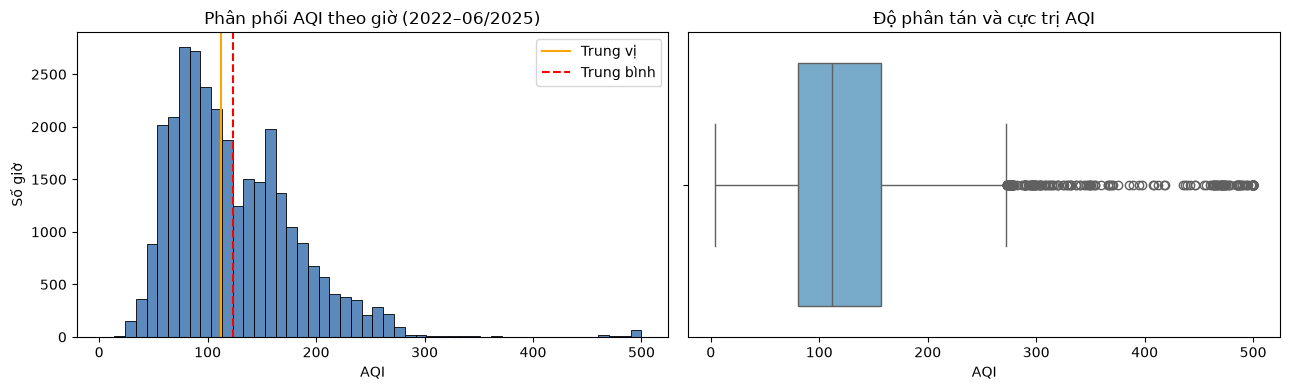

In [28]:
aqi=eda['AQI'].dropna()
print('valid',len(aqi),'mean',round(aqi.mean(),3),'median',round(aqi.median(),3),'std',round(aqi.std(),3),'skew',round(aqi.skew(),3),'p95',aqi.quantile(.95),'p99',aqi.quantile(.99),'AQI>=300',int((aqi>=300).sum()),'AQI=500',int((aqi==500).sum()))
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.histplot(aqi,bins=50,ax=axes[0],color='#2563a6');axes[0].axvline(aqi.median(),color='orange',label='Trung vị');axes[0].axvline(aqi.mean(),color='red',linestyle='--',label='Trung bình');axes[0].set(title='Phân phối AQI theo giờ (2022–06/2025)',xlabel='AQI',ylabel='Số giờ');axes[0].legend()
sns.boxplot(x=aqi,ax=axes[1],color='#6baed6');axes[1].set(title='Độ phân tán và cực trị AQI',xlabel='AQI',ylabel='')
fig.tight_layout();fig.savefig(project_root/'output/figures/eda_aqi_distribution.png',dpi=160);plt.show()

### Kết luận bước 3.2

Histogram và boxplot cho thấy AQI tập trung chủ yếu dưới khoảng 200 và có đuôi phải kéo dài; hệ số lệch 1,494, trung bình 123,787 cao hơn trung vị 112. Trong 30.333 giờ hợp lệ có 173 giờ AQI ≥300, gồm 59 giờ AQI=500; p95=228 và p99=270. Các giá trị lớn kéo trung bình lên và xuất hiện như điểm ngoài râu boxplot, nhưng không đủ căn cứ xem là lỗi; chúng được giữ nguyên. Hình: output/figures/eda_aqi_distribution.png. Chưa suy luận xu hướng hoặc nguyên nhân.

### Bước 3.3 — Độ bao phủ theo ngày, tháng và năm

**Mục tiêu:** Phân biệt ngày không có dòng với ngày có dòng nhưng thiếu AQI.

**Lý do:** Độ bao phủ khác nhau có thể làm sai so sánh thời gian.

**Phương pháp:** Nhóm theo ngày; reindex lịch từ 2022-01-01 đến 2025-12-31; tổng hợp theo tháng/năm và vẽ heatmap tỷ lệ giờ có bản ghi.

**Kết quả cần quan sát:** Bảng ngày thiếu/không đủ và heatmap độ bao phủ.

ANNUAL
      days_with_records  days_no_records  recorded_hours  valid_aqi_hours
year                                                                     
2022                353               12            8472             8470
2023                364                1            8736             8736
2024                366                0            8784             8783
2025                181              184            4344             4344
days with 0<valid AQI<24
            recorded_hours  valid_aqi_hours
2022-07-01              24               22
2024-12-01              24               23
2023-12-31 {'recorded_hours': 0, 'valid_aqi_hours': 0}
monthly recorded/valid hours
            recorded_hours  valid_aqi_hours
year month                                 
2022 1                 456              456
     2                 672              672
     3                 744              744
     4                 720              720
     5                 744              744


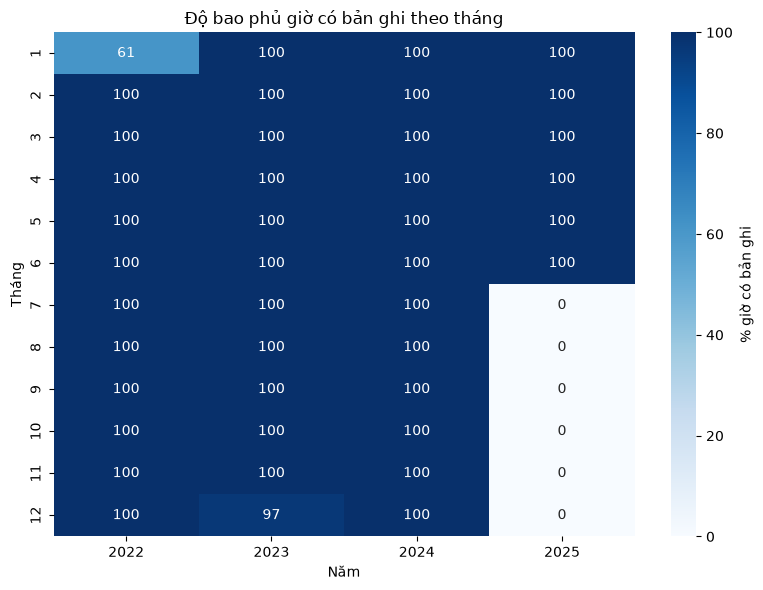

In [29]:
by_day=eda.groupby(eda['Local Time'].dt.normalize()).agg(recorded_hours=('AQI','size'),valid_aqi_hours=('AQI','count'),daily_aqi=('AQI','mean'))
calendar=pd.date_range('2022-01-01','2025-12-31',freq='D')
coverage=by_day.reindex(calendar);coverage[['recorded_hours','valid_aqi_hours']]=coverage[['recorded_hours','valid_aqi_hours']].fillna(0).astype(int)
coverage['year']=coverage.index.year;coverage['month']=coverage.index.month
annual=coverage.groupby('year').agg(days_with_records=('recorded_hours',lambda x:int((x>0).sum())),days_no_records=('recorded_hours',lambda x:int((x==0).sum())),recorded_hours=('recorded_hours','sum'),valid_aqi_hours=('valid_aqi_hours','sum'))
monthly=coverage.groupby(['year','month'])[['recorded_hours','valid_aqi_hours']].sum()
print('ANNUAL');print(annual.to_string())
print('days with 0<valid AQI<24');print(coverage.loc[(coverage['recorded_hours']>0)&(coverage['valid_aqi_hours']<24),['recorded_hours','valid_aqi_hours']].to_string())
print('2023-12-31',coverage.loc['2023-12-31',['recorded_hours','valid_aqi_hours']].to_dict())
print('monthly recorded/valid hours');print(monthly.to_string())
monthly_pct=(monthly['recorded_hours']/pd.MultiIndex.from_tuples(monthly.index).map(lambda ym:pd.Period(f'{ym[0]}-{ym[1]:02d}').days_in_month*24)).unstack(0)*100
fig,ax=plt.subplots(figsize=(8,6));sns.heatmap(monthly_pct,annot=True,fmt='.0f',cmap='Blues',vmin=0,vmax=100,cbar_kws={'label':'% giờ có bản ghi'},ax=ax);ax.set(title='Độ bao phủ giờ có bản ghi theo tháng',xlabel='Năm',ylabel='Tháng');fig.tight_layout();fig.savefig(project_root/'output/figures/eda_coverage.png',dpi=160);plt.show()

### Kết luận bước 3.3

Theo lịch đầy đủ: 2022 có 353 ngày có bản ghi và 12 ngày đầu năm không có; 2023 có 364 ngày có bản ghi, thiếu hẳn 31/12; 2024 đủ 366 ngày; 2025 chỉ có 181 ngày đến 30/06 và không có 184 ngày cuối năm. Số giờ có bản ghi theo năm là 8.472, 8.736, 8.784, 4.344; giờ AQI hợp lệ tương ứng 8.470, 8.736, 8.783, 4.344. Hai ngày có đủ 24 dòng nhưng thiếu AQI là 01/07/2022 (22 giờ hợp lệ) và 01/12/2024 (23 giờ). Heatmap thể hiện tỷ lệ giờ có bản ghi, không phải tỷ lệ AQI hợp lệ: tháng 01/2022 khoảng 61%, tháng 12/2023 khoảng 97%, tháng 07–12/2025 là 0%. Hình: output/figures/eda_coverage.png; các so sánh sau phải kiểm soát độ bao phủ.

### Bước 3.4 — Biến động AQI theo thời gian

**Mục tiêu:** Quan sát tổng quan chuỗi AQI ngày và tháng.

**Lý do:** Tổng hợp phải nêu số giờ hợp lệ và giữ khoảng vắng bản ghi.

**Phương pháp:** Dùng bảng ngày ở bước 3.3, tạo trung bình tháng và hai biểu đồ đường; không suy luận xu hướng dài hạn.

**Kết quả cần quan sát:** Đường ngày/tháng có khoảng trống, bảng số giờ hợp lệ.

daily AQI days 1264 missing days 197
monthly AQI range 68.54 187.09 months 42
first/last monthly rows
            mean_aqi  valid_aqi_hours  recorded_hours
Local Time                                           
2022-01-01    153.15              456             456
2022-02-01    142.49              672             672
2025-05-01    122.92              744             744
2025-06-01    109.26              720             720


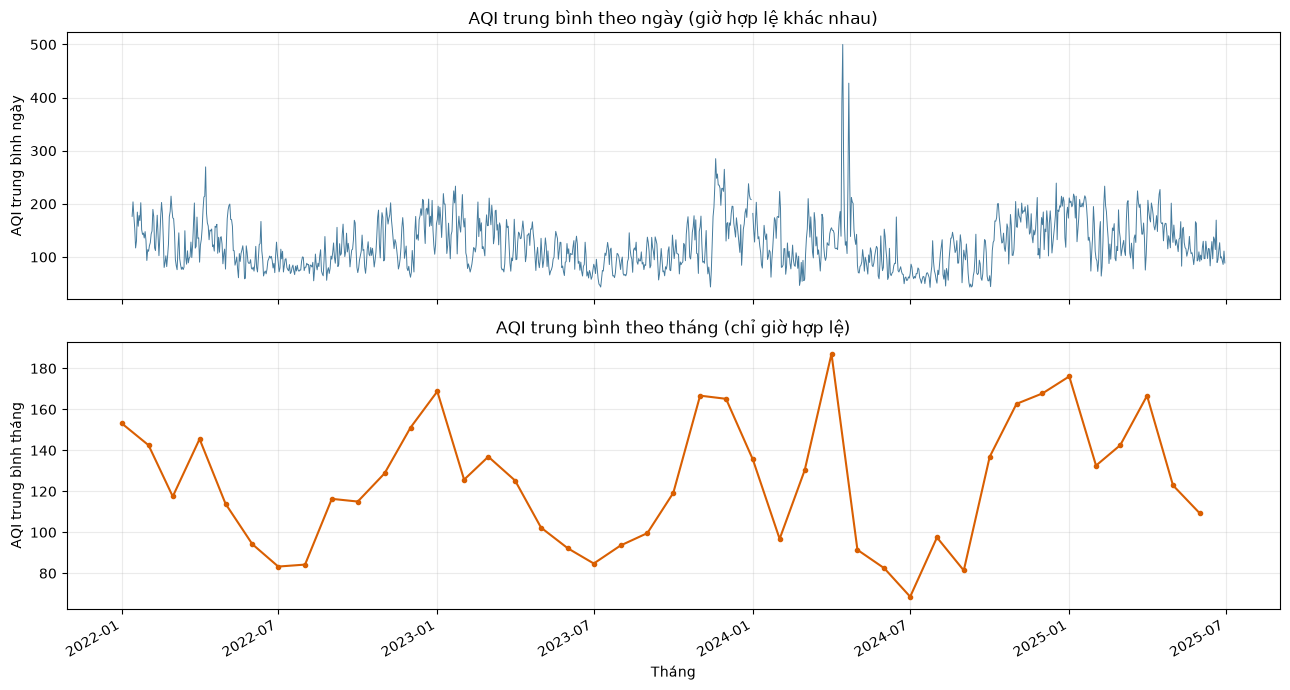

In [30]:
daily_view=coverage[['daily_aqi','valid_aqi_hours']].copy()
monthly_aqi=eda.groupby(eda['Local Time'].dt.to_period('M')).agg(mean_aqi=('AQI','mean'),valid_aqi_hours=('AQI','count'),recorded_hours=('AQI','size'))
monthly_aqi.index=monthly_aqi.index.to_timestamp()
print('daily AQI days',int(daily_view['daily_aqi'].notna().sum()),'missing days',int(daily_view['daily_aqi'].isna().sum()))
print('monthly AQI range',round(monthly_aqi['mean_aqi'].min(),2),round(monthly_aqi['mean_aqi'].max(),2),'months',len(monthly_aqi))
print('first/last monthly rows');print(pd.concat([monthly_aqi.head(2),monthly_aqi.tail(2)]).round(2).to_string())
fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
axes[0].plot(daily_view.index,daily_view['daily_aqi'],color='#457b9d',linewidth=.7);axes[0].set(title='AQI trung bình theo ngày (giờ hợp lệ khác nhau)',ylabel='AQI trung bình ngày',xlabel='Ngày')
axes[1].plot(monthly_aqi.index,monthly_aqi['mean_aqi'],marker='o',markersize=3,color='#d95f02');axes[1].set(title='AQI trung bình theo tháng (chỉ giờ hợp lệ)',ylabel='AQI trung bình tháng',xlabel='Tháng')
for ax in axes:ax.grid(alpha=.25)
fig.autofmt_xdate();fig.tight_layout();fig.savefig(project_root/'output/figures/eda_aqi_over_time.png',dpi=160);plt.show()

### Kết luận bước 3.4

Có 1.264 ngày có AQI trung bình quan sát và 197 ngày trong lịch 2022–2025 không có AQI ngày; 42 tháng có dữ liệu, trung bình tháng trong khoảng 68,54–187,09. Biểu đồ cho thấy dao động đáng kể ở cả thang ngày và tháng; không suy ra xu hướng dài hạn ở bước này. Đỉnh ngày 14/04/2024 được kiểm tra riêng: đủ 24 giờ và cả 24 giá trị AQI đều bằng 500, nên đỉnh 500 trên hình không do thiếu giờ; nguồn gốc các giá trị 500 vẫn chưa xác minh. Bảng tháng kèm valid_aqi_hours, ví dụ 01/2022 chỉ 456 giờ. Hình: output/figures/eda_aqi_over_time.png. Câu hỏi 1–2 sẽ cần so sánh trong khoảng thời gian và độ bao phủ phù hợp.

### Bước 3.5 — Phân phối sáu chất ô nhiễm

**Mục tiêu:** Khảo sát phạm vi và độ lệch của CO, NO2, O3, PM10, PM25, SO2.

**Lý do:** Cực trị có thể nén phần lớn phân phối trên biểu đồ tuyến tính.

**Phương pháp:** Tính count, median, p95, p99, max, skew; vẽ sáu histogram trục đếm log, không gán đơn vị chưa xác minh.

**Kết quả cần quan sát:** Bảng phân phối và hình 6 ô giữ đầy đủ cực trị.

      count  median      p95      p99      max  skew
CO    30260  181.50  1830.02  3643.95  15956.2  5.84
NO2   30261   18.00    84.30   154.00    378.0  3.52
O3    30259   48.70   145.00   192.70    700.0  1.46
PM10  30333   52.20   177.00   305.00   1103.0  6.92
PM25  30333   39.33   130.00   212.00    457.0  2.78
SO2   30258   55.70   146.70   207.70    721.0  4.83


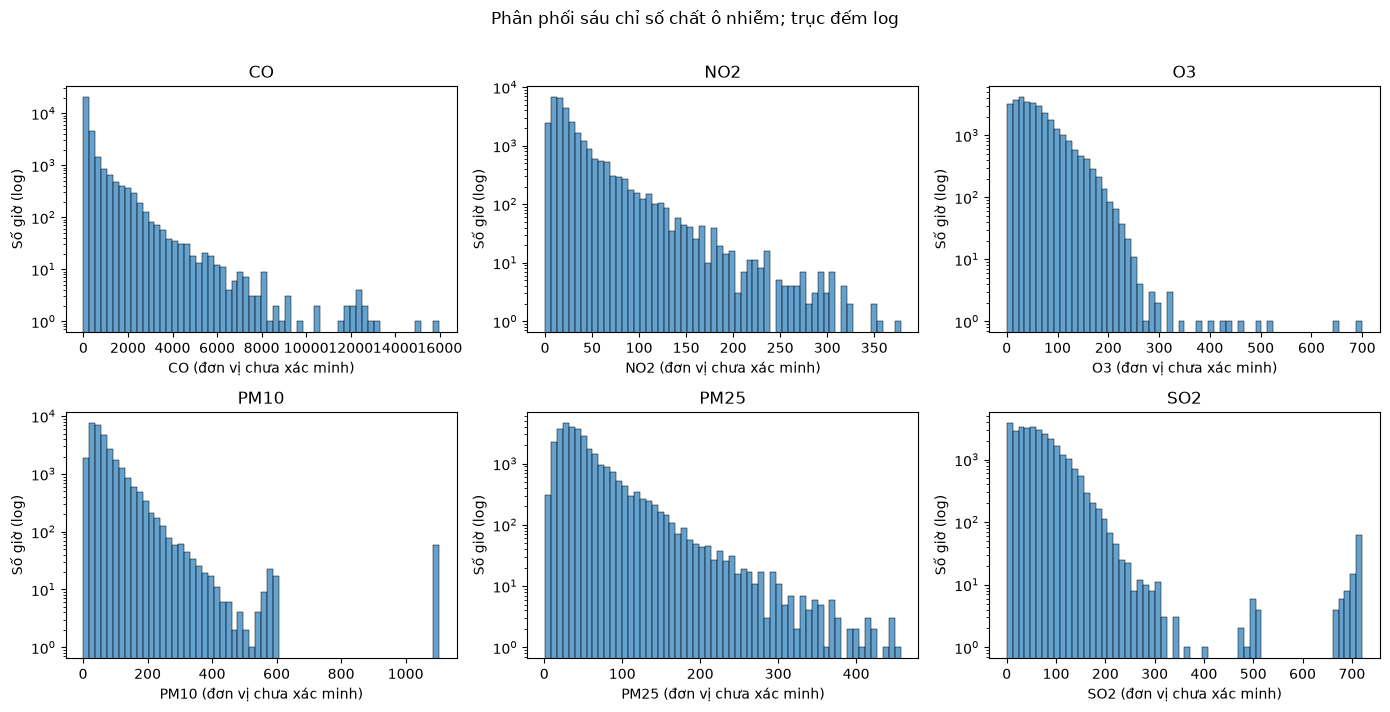

In [31]:
pollutants=['CO','NO2','O3','PM10','PM25','SO2']
poll_stats=pd.DataFrame({'count':eda[pollutants].count(),'median':eda[pollutants].median(),'p95':eda[pollutants].quantile(.95),'p99':eda[pollutants].quantile(.99),'max':eda[pollutants].max(),'skew':eda[pollutants].skew()})
print(poll_stats.round(2).to_string())
fig,axes=plt.subplots(2,3,figsize=(14,7))
for ax,col in zip(axes.flat,pollutants):
    sns.histplot(eda[col].dropna(),bins=60,ax=ax,color='#3182bd');ax.set_yscale('log');ax.set(title=col,xlabel=f'{col} (đơn vị chưa xác minh)',ylabel='Số giờ (log)')
fig.suptitle('Phân phối sáu chỉ số chất ô nhiễm; trục đếm log',y=1.01);fig.tight_layout();fig.savefig(project_root/'output/figures/eda_pollutants.png',dpi=160,bbox_inches='tight');plt.show()

### Kết luận bước 3.5

Sáu phân phối có đuôi phải (skew dương), rõ ở PM10 6,92 và CO 5,84; trục đếm log giúp thấy cả nhóm phổ biến lẫn giá trị hiếm mà không cắt cực trị. CO có trung vị 181,50, p99=3.643,95, max=15.956,2; PM10 có trung vị 52,20, p99=305, max=1.103. Kiểm tra riêng cụm trên hình cho thấy PM10=1.103 xuất hiện 58 giờ từ 11/04 đến 22/04/2024, SO2≥700 xuất hiện 78 giờ từ 20/04 đến 03/05/2025; đây là cụm cần đánh giá độ nhạy ở Câu hỏi 3, chưa kết luận nguồn gốc hay tính đúng/sai. Số hợp lệ mỗi chất là 30.258–30.333; không gán đơn vị đo. Hình: output/figures/eda_pollutants.png. Chưa tính tương quan với AQI.

### Bước 3.6 — Phân phối các yếu tố thời tiết

**Mục tiêu:** Khảo sát bảy chỉ số thời tiết và số lượng giá trị 0.

**Lý do:** Biến nhiều số 0 hoặc cực trị cần diễn giải khác biến gần đối xứng.

**Phương pháp:** Tính count, median, p95, max, zero count; vẽ histogram bốn biến trọng tâm.

**Kết quả cần quan sát:** Bảng bảy biến và hình 4 ô; chưa phân tích quan hệ với AQI.

                   count     mean  median      p95     max  zero_count
Temperature        30336    24.88    25.7    33.30    40.0           0
Relative Humidity  30336    77.60    82.0    95.00   100.0           0
Precipitation      30336     0.24     0.0     1.25    28.0       25365
Wind Speed         30336     1.78     2.0     3.00    14.9          29
Pressure           30336  1010.08  1010.0  1023.00  1033.0           0
Clouds             30336    71.00    79.0   100.00   100.0        1192
UV Index           30336     1.32     0.6     5.20    12.1       15010


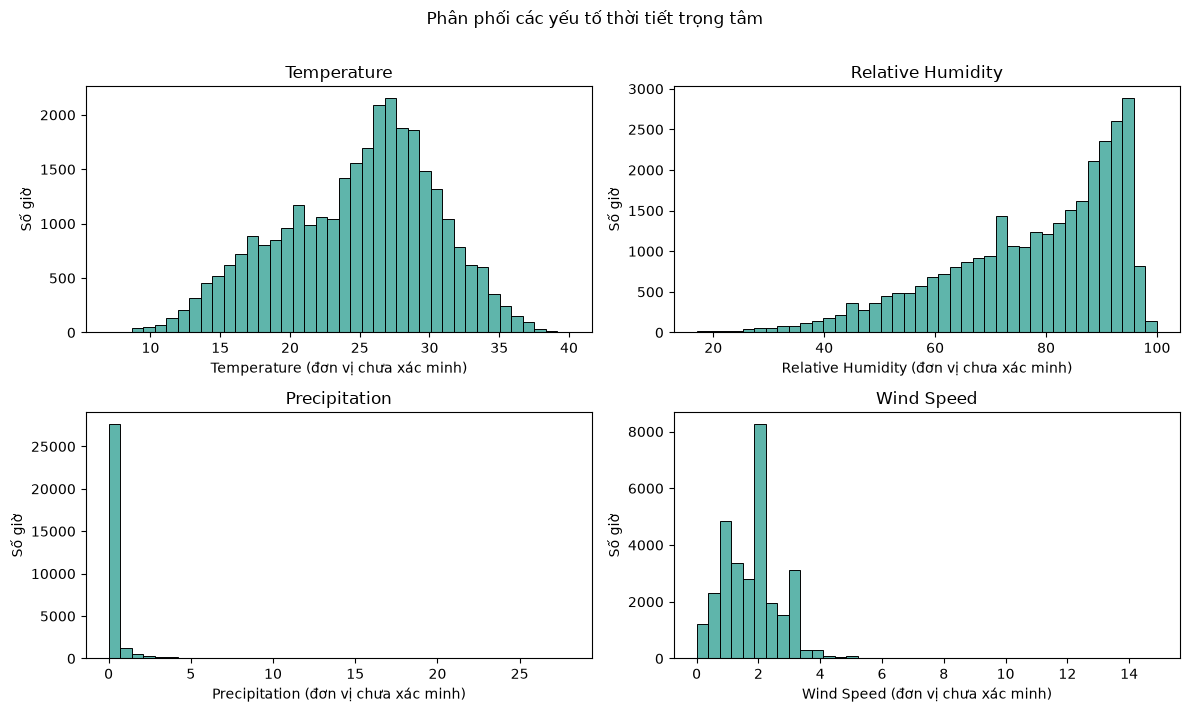

In [32]:
weather=['Temperature','Relative Humidity','Precipitation','Wind Speed','Pressure','Clouds','UV Index']
weather_stats=pd.DataFrame({'count':eda[weather].count(),'mean':eda[weather].mean(),'median':eda[weather].median(),'p95':eda[weather].quantile(.95),'max':eda[weather].max(),'zero_count':(eda[weather]==0).sum()})
print(weather_stats.round(2).to_string())
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,col in zip(axes.flat,['Temperature','Relative Humidity','Precipitation','Wind Speed']):
    sns.histplot(eda[col].dropna(),bins=40,ax=ax,color='#2a9d8f');ax.set(title=col,xlabel=f'{col} (đơn vị chưa xác minh)',ylabel='Số giờ')
fig.suptitle('Phân phối các yếu tố thời tiết trọng tâm',y=1.01);fig.tight_layout();fig.savefig(project_root/'output/figures/eda_weather.png',dpi=160,bbox_inches='tight');plt.show()

### Kết luận bước 3.6

Cả bảy chỉ số thời tiết có 30.336 giá trị hợp lệ. Trong bốn biểu đồ trọng tâm, Temperature trải từ 7 đến 40, trung vị 25,7; Relative Humidity thiên về mức cao với trung vị 82; Wind Speed trung vị 2,0 và cực đại 14,9. Precipitation bằng 0 ở 25.365/30.336 giờ (khoảng 83,6%), nên histogram dồn ở 0; UV Index cũng bằng 0 ở 15.010 giờ. Pressure có trung vị 1.010, Clouds 79 nhưng không cần thêm hình riêng ở EDA tổng quan. Hình: output/figures/eda_weather.png. Chưa kiểm tra mối liên hệ thời tiết–AQI; Câu hỏi 4 sẽ cần chú ý phân phối nhiều số 0 của mưa và đơn vị chưa xác minh.

## Giai đoạn 4 — Câu hỏi nghiên cứu 1

**Câu hỏi:** Chỉ số AQI tại Hà Nội thay đổi như thế nào giữa các năm trong nửa đầu và nửa cuối năm?

Phần A so sánh 13/01–30/06 của 2022–2025, loại 29/02/2024 để có cùng tập ngày lịch. Phần B so sánh 01/07–30/12 của 2022–2024. Phần C đối chiếu hai kết quả. Mọi bảng dùng AQI đã làm sạch, báo số giờ hợp lệ; không suy ra nguyên nhân hoặc xu hướng dài hạn.

### Bước 4.1 — Phần A — So sánh nửa đầu năm 2022–2025

**Mục tiêu:** So sánh AQI trên cùng các ngày lịch 13/01–30/06.

**Lý do:** Năm 2022 bắt đầu 13/01, 2025 kết thúc 30/06 và 2024 có 29/02; cần cùng tập ngày để so sánh.

**Phương pháp:** Lọc theo tháng-ngày, loại 29/02, nhóm theo năm và tính count, mean, median, std, min, max; kiểm tra 4.056 giờ mỗi năm, tính chênh lệch trung bình năm kề nhau và vẽ cột từ mốc 0.

**Kết quả cần quan sát:** Bảng thống kê bốn năm, bảng chênh lệch và biểu đồ có nhãn số giờ hợp lệ.

PART A STATS
      count     mean  median     std   min    max  recorded_hours  coverage_pct
year                                                                           
2022   4056  125.828   112.0  53.293  21.0  475.0            4056         100.0
2023   4056  121.880   115.0  46.234  21.0  276.0            4056         100.0
2024   4056  119.832   100.0  76.184   4.0  500.0            4056         100.0
2025   4056  138.409   131.0  51.056  22.0  470.0            4056         100.0
calendar days expected=169, hours expected=4056 per year; leap-day excluded rows= 24
PART A ADJACENT DIFFERENCES (mean AQI)
year
2023    -3.947
2024    -2.049
2025    18.577
2022 to 2025 mean difference= 12.581


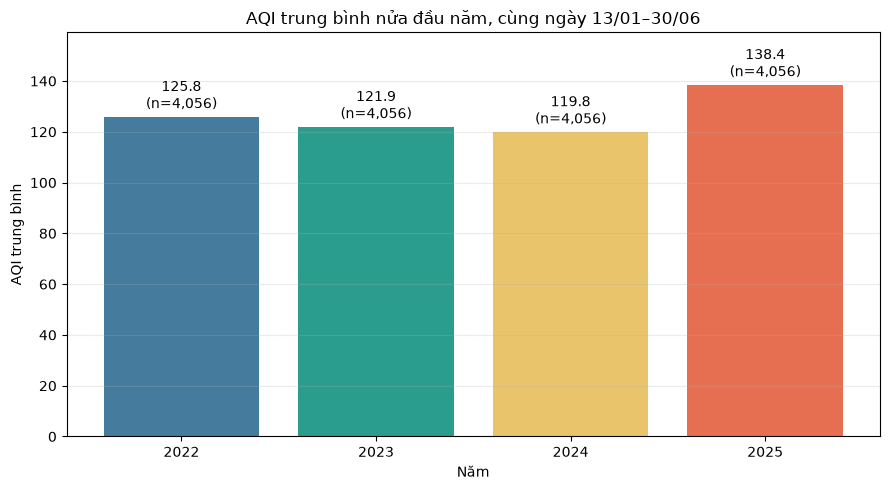

In [33]:
q1_date=eda['Local Time'].dt.strftime('%m-%d')
q1_year=eda['Local Time'].dt.year
q1_a=eda.loc[q1_date.between('01-13','06-30') & (q1_date!='02-29') & q1_year.isin([2022,2023,2024,2025])].copy()
q1_a['year']=q1_a['Local Time'].dt.year
a_stats=q1_a.groupby('year')['AQI'].agg(['count','mean','median','std','min','max'])
a_stats['recorded_hours']=q1_a.groupby('year').size()
a_stats['coverage_pct']=100*a_stats['count']/4056
print('PART A STATS');print(a_stats.round(3).to_string())
print('calendar days expected=169, hours expected=4056 per year; leap-day excluded rows=',int(((eda['Local Time'].dt.year==2024)&(q1_date=='02-29')).sum()))
print('PART A ADJACENT DIFFERENCES (mean AQI)');print(a_stats['mean'].diff().dropna().round(3).to_string())
print('2022 to 2025 mean difference=',round(a_stats.loc[2025,'mean']-a_stats.loc[2022,'mean'],3))
assert (a_stats['recorded_hours']==4056).all()
fig,ax=plt.subplots(figsize=(9,5));bars=ax.bar(a_stats.index.astype(str),a_stats['mean'],color=['#457b9d','#2a9d8f','#e9c46a','#e76f51']);ax.set(title='AQI trung bình nửa đầu năm, cùng ngày 13/01–30/06',xlabel='Năm',ylabel='AQI trung bình',ylim=(0,max(a_stats['mean'])*1.15));ax.bar_label(bars,labels=[f'{v:.1f}\n(n={int(n):,})' for v,n in zip(a_stats['mean'],a_stats['count'])],padding=3);ax.grid(axis='y',alpha=.25);fig.tight_layout();fig.savefig(project_root/'output/figures/q1_first_half.png',dpi=160);plt.show()

### Kết luận bước 4.1

Phần A dùng đúng 169 ngày lịch (13/01–30/06) và 4.056 giờ AQI hợp lệ cho mỗi năm; đã loại 24 giờ của 29/02/2024. AQI trung bình lần lượt 125,828 (2022), 121,880 (2023), 119,832 (2024), 138,409 (2025); trung vị 112, 115, 100, 131. Chênh trung bình năm kề nhau là −3,947, −2,049 và +18,577 điểm; 2025 cao hơn 2022 12,581 điểm trong cùng khoảng. Độ lệch chuẩn 2024 là 76,184, cao hơn các năm còn lại (46,234–53,293), phù hợp với phạm vi 4–500 và cần thận trọng với cụm AQI=500 đã ghi nhận. Biểu đồ q1_first_half.png khớp bảng và dùng trục từ 0. Kết luận riêng: mức trung bình giảm từ 2022 đến 2024 rồi tăng ở 2025 trong nửa đầu năm; chưa suy ra nguyên nhân hoặc xu hướng dài hạn.

### Bước 4.2 — Phần B — So sánh nửa cuối năm 2022–2024

**Mục tiêu:** So sánh AQI trên cùng các ngày lịch 01/07–30/12.

**Lý do:** Năm 2023 không có 31/12 và 2025 không có nửa cuối; giới hạn 30/12 giúp ba năm có cùng tập ngày.

**Phương pháp:** Lọc theo tháng-ngày, nhóm năm, tính sáu chỉ số, số giờ hợp lệ và chênh lệch trung bình năm kề nhau; vẽ cột từ mốc 0.

**Kết quả cần quan sát:** Bảng thống kê ba năm, vị trí AQI thiếu và biểu đồ có nhãn số giờ hợp lệ.

PART B STATS
      count     mean  median     std   min    max  recorded_hours  coverage_pct
year                                                                           
2022   4390  112.746   102.0  47.376  21.0  276.0            4392        99.954
2023   4392  121.126   103.0  60.726  25.0  487.0            4392       100.000
2024   4391  118.775   109.0  58.453  12.0  276.0            4392        99.977
calendar days expected=183, hours expected=4392 per year
missing AQI hours
2022-07-01 06:00:00
2022-07-01 07:00:00
2024-12-01 00:00:00
PART B ADJACENT DIFFERENCES (mean AQI)
year
2023    8.38
2024   -2.35
2022 to 2024 mean difference= 6.03


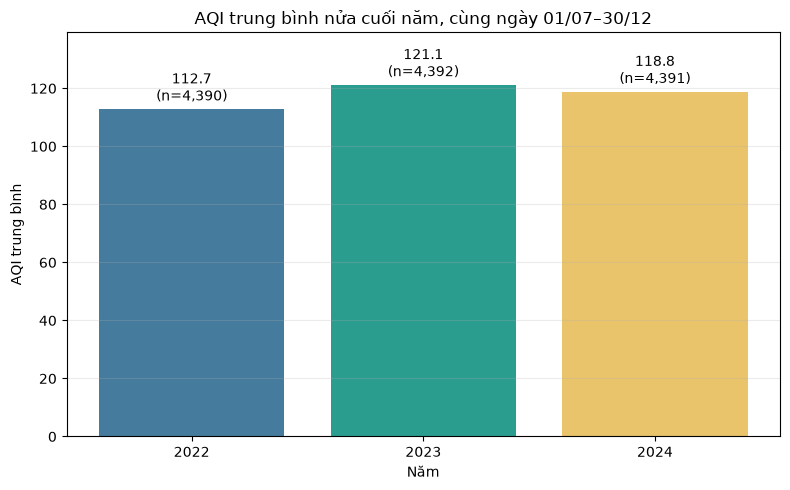

In [34]:
q1_b=eda.loc[q1_date.between('07-01','12-30') & q1_year.isin([2022,2023,2024])].copy()
q1_b['year']=q1_b['Local Time'].dt.year
b_stats=q1_b.groupby('year')['AQI'].agg(['count','mean','median','std','min','max'])
b_stats['recorded_hours']=q1_b.groupby('year').size()
b_stats['coverage_pct']=100*b_stats['count']/4392
print('PART B STATS');print(b_stats.round(3).to_string())
print('calendar days expected=183, hours expected=4392 per year')
print('missing AQI hours');print(q1_b.loc[q1_b['AQI'].isna(),'Local Time'].to_string(index=False))
print('PART B ADJACENT DIFFERENCES (mean AQI)');print(b_stats['mean'].diff().dropna().round(3).to_string())
print('2022 to 2024 mean difference=',round(b_stats.loc[2024,'mean']-b_stats.loc[2022,'mean'],3))
assert (b_stats['recorded_hours']==4392).all()
fig,ax=plt.subplots(figsize=(8,5));bars=ax.bar(b_stats.index.astype(str),b_stats['mean'],color=['#457b9d','#2a9d8f','#e9c46a']);ax.set(title='AQI trung bình nửa cuối năm, cùng ngày 01/07–30/12',xlabel='Năm',ylabel='AQI trung bình',ylim=(0,max(b_stats['mean'])*1.15));ax.bar_label(bars,labels=[f'{v:.1f}\n(n={int(n):,})' for v,n in zip(b_stats['mean'],b_stats['count'])],padding=3);ax.grid(axis='y',alpha=.25);fig.tight_layout();fig.savefig(project_root/'output/figures/q1_second_half.png',dpi=160);plt.show()

### Kết luận bước 4.2

Phần B dùng cùng 183 ngày lịch (01/07–30/12), mỗi năm có 4.392 giờ có bản ghi. AQI hợp lệ là 4.390 giờ ở 2022, 4.392 ở 2023 và 4.391 ở 2024; ba giờ thiếu gồm 01/07/2022 06:00–07:00 và 01/12/2024 00:00. Trung bình AQI lần lượt 112,746; 121,126; 118,775, trung vị 102; 103; 109, độ lệch chuẩn 47,376; 60,726; 58,453. Chênh trung bình là +8,380 từ 2022 sang 2023, −2,350 từ 2023 sang 2024; 2024 cao hơn 2022 6,030. Biểu đồ q1_second_half.png khớp bảng và ghi số giờ hợp lệ. Kết luận riêng: nửa cuối năm tăng từ 2022 đến 2023 rồi giảm nhẹ vào 2024; ba giờ thiếu làm độ bao phủ AQI gần 100% nhưng vẫn phải nêu rõ.

### Bước 4.3 — Phần C — Đối chiếu hai nửa năm

**Mục tiêu:** Xem biến động giữa các năm có cùng chiều ở hai khoảng thời gian hay không.

**Lý do:** Kết luận từ một nửa năm có thể không đại diện cho nửa còn lại; 2025 không có dữ liệu nửa cuối.

**Phương pháp:** Đặt cạnh các trung bình của 2022–2024, tính chênh lệch năm kề nhau ở từng nửa và kiểm tra dấu; vẽ cột nhóm từ mốc 0.

**Kết quả cần quan sát:** Bảng trung bình, bảng chênh lệch hai nửa và biểu đồ đối chiếu; không gán giá trị nửa cuối cho 2025.

COMMON-YEAR COMPARISON
      first_half_mean  second_half_mean  first_half_valid_hours  second_half_valid_hours
year                                                                                    
2022          125.828           112.746                    4056                     4390
2023          121.880           121.126                    4056                     4392
2024          119.832           118.775                    4056                     4391
YEAR-TO-YEAR CHANGE
   period  first_half_delta  second_half_delta  same_direction
2022→2023            -3.947               8.38           False
2023→2024            -2.049              -2.35            True
2025 first half mean= 138.409 second half=not observed


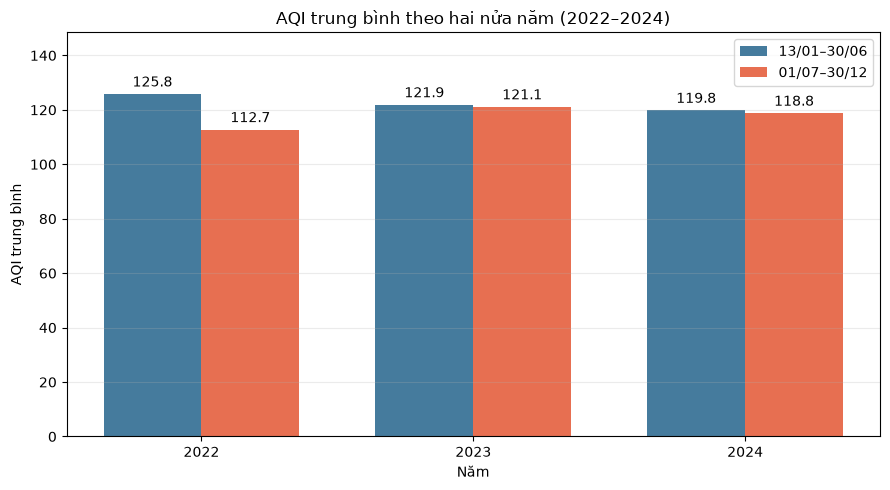

In [35]:
common_years=[2022,2023,2024]
q1_compare=pd.DataFrame({'first_half_mean':a_stats.loc[common_years,'mean'],'second_half_mean':b_stats.loc[common_years,'mean'],'first_half_valid_hours':a_stats.loc[common_years,'count'],'second_half_valid_hours':b_stats.loc[common_years,'count']})
changes=pd.DataFrame({'period':['2022→2023','2023→2024'],'first_half_delta':[a_stats.loc[2023,'mean']-a_stats.loc[2022,'mean'],a_stats.loc[2024,'mean']-a_stats.loc[2023,'mean']],'second_half_delta':[b_stats.loc[2023,'mean']-b_stats.loc[2022,'mean'],b_stats.loc[2024,'mean']-b_stats.loc[2023,'mean']]})
changes['same_direction']=np.sign(changes['first_half_delta'])==np.sign(changes['second_half_delta'])
print('COMMON-YEAR COMPARISON');print(q1_compare.round(3).to_string())
print('YEAR-TO-YEAR CHANGE');print(changes.round(3).to_string(index=False))
print('2025 first half mean=',round(a_stats.loc[2025,'mean'],3),'second half=not observed')
fig,ax=plt.subplots(figsize=(9,5));x=np.arange(len(common_years));w=.36;bar_a=ax.bar(x-w/2,q1_compare['first_half_mean'],w,label='13/01–30/06',color='#457b9d');bar_b=ax.bar(x+w/2,q1_compare['second_half_mean'],w,label='01/07–30/12',color='#e76f51');ax.set(title='AQI trung bình theo hai nửa năm (2022–2024)',xlabel='Năm',ylabel='AQI trung bình',xticks=x,xticklabels=common_years,ylim=(0,max(q1_compare[['first_half_mean','second_half_mean']].max())*1.18));ax.bar_label(bar_a,fmt='%.1f',padding=3);ax.bar_label(bar_b,fmt='%.1f',padding=3);ax.legend();ax.grid(axis='y',alpha=.25);fig.tight_layout();fig.savefig(project_root/'output/figures/q1_half_year_comparison.png',dpi=160);plt.show()

### Kết luận bước 4.3

Đối chiếu ba năm có cả hai nửa: 2022 AQI trung bình nửa đầu 125,828 và nửa cuối 112,746; 2023 là 121,880 và 121,126; 2024 là 119,832 và 118,775. Biến động 2022→2023 KHÔNG cùng chiều: nửa đầu −3,947 nhưng nửa cuối +8,380. Biến động 2023→2024 cùng chiều giảm: −2,049 ở nửa đầu và −2,350 ở nửa cuối. Vì vậy kết quả giữa các năm không nhất quán hoàn toàn theo hai nửa; chỉ giai đoạn 2023→2024 cùng chiều. Nửa đầu 2025 có trung bình 138,409, nhưng không có dữ liệu nửa cuối 2025 nên không đưa vào biểu đồ đối chiếu hai nửa. Biểu đồ q1_half_year_comparison.png khớp bảng. Đây là thay đổi quan sát trong các khoảng đã chọn, chưa chứng minh nguyên nhân hoặc xu hướng dài hạn.

### Bổ sung Giai đoạn 4 — Độ nhạy với AQI = 500

Các giá trị AQI=500 được giữ nguyên trong dữ liệu chính. Các phép tính dưới đây chỉ dùng bản lọc tạm để kiểm tra mức ảnh hưởng đến Câu hỏi 1.

### Bước 4.4 — Đếm AQI = 500 theo năm và nửa năm

**Mục tiêu:** Xác định chính xác số giờ AQI=500 trong từng phạm vi.

**Lý do:** Phải biết số quan sát bị loại tạm trước khi đối chiếu thống kê.

**Phương pháp:** Đếm trên dữ liệu đã làm sạch và trên hai tập Phần A/B, không thay đổi bảng gốc.

**Kết quả cần quan sát:** Số giờ AQI=500 theo năm, nửa đầu và nửa cuối.

In [36]:
all_500=eda.assign(year=eda['Local Time'].dt.year).groupby('year')['AQI'].apply(lambda s:int((s==500).sum()))
a_500=q1_a.groupby('year')['AQI'].apply(lambda s:int((s==500).sum()))
b_500=q1_b.groupby('year')['AQI'].apply(lambda s:int((s==500).sum()))
counts_500=pd.DataFrame({'all_observed':all_500,'first_half_common':a_500,'second_half_common':b_500}).fillna(0).astype(int)
print(counts_500.to_string())
print('total AQI=500:',int((eda['AQI']==500).sum()))
assert int((eda['AQI']==500).sum())==59

      all_observed  first_half_common  second_half_common
year                                                     
2022             0                  0                   0
2023             0                  0                   0
2024            59                 59                   0
2025             0                  0                   0
total AQI=500: 59


### Kết luận bước 4.4

Toàn bộ 59 giờ AQI=500 thuộc năm 2024 và đều nằm trong Phần A (13/01–30/06, không tính 29/02). Phần B không có AQI=500; các năm 2022, 2023, 2025 cũng không có. Vì vậy phép lọc tạm chỉ có thể thay đổi thống kê nửa đầu 2024. Tiếp tục tính bảng đối chiếu; dữ liệu chính vẫn giữ đủ 59 giờ.

### Bước 4.5 — Thống kê đối chiếu khi tạm loại AQI = 500

**Mục tiêu:** Đo thay đổi số giờ, trung bình và trung vị trong đúng hai phạm vi của Câu hỏi 1.

**Lý do:** Nếu cực trị chi phối trung bình, kết luận dựa vào trung bình cần được diễn giải thận trọng.

**Phương pháp:** Tạo bản lọc tạm AQI!=500 cho Phần A/B, tính lại count/mean/median; lấy chênh và phần trăm theo số liệu chính.

**Kết quả cần quan sát:** Hai bảng gốc–lọc tạm, mức chênh tuyệt đối và phần trăm.

In [37]:
def sensitivity_table(source, original):
    filtered=source.loc[source['AQI']!=500]
    alternative=filtered.groupby('year')['AQI'].agg(['count','mean','median'])
    result=pd.DataFrame({'n_original':original['count'].astype(int),'n_without_500':alternative['count'].astype(int),'mean_original':original['mean'],'mean_without_500':alternative['mean'],'median_original':original['median'],'median_without_500':alternative['median']})
    result['mean_change_without_500']=result['mean_without_500']-result['mean_original']
    result['mean_change_pct']=100*result['mean_change_without_500']/result['mean_original']
    result['median_change_without_500']=result['median_without_500']-result['median_original']
    return result
sens_a=sensitivity_table(q1_a,a_stats);sens_b=sensitivity_table(q1_b,b_stats)
print('PART A (13/01–30/06, excluding 29/02/2024)');print(sens_a.round(4).to_string())
print('PART B (01/07–30/12)');print(sens_b.round(4).to_string())
print('temporary filtering only; cleaned data AQI=500 still',int((eda['AQI']==500).sum()))

PART A (13/01–30/06, excluding 29/02/2024)
      n_original  n_without_500  mean_original  mean_without_500  median_original  median_without_500  mean_change_without_500  mean_change_pct  median_change_without_500
year                                                                                                                                                                      
2022        4056           4056       125.8279          125.8279            112.0               112.0                   0.0000            0.000                        0.0
2023        4056           4056       121.8804          121.8804            115.0               115.0                   0.0000            0.000                        0.0
2024        4056           3997       119.8319          114.2202            100.0                99.0                  -5.6117           -4.683                       -1.0
2025        4056           4056       138.4090          138.4090            131.0               131.0 

### Kết luận bước 4.5

Khi chỉ tạm bỏ AQI=500 trong Phần A, năm 2024 còn 3.997/4.056 giờ hợp lệ; trung bình giảm từ 119,8319 xuống 114,2202, tức −5,6117 điểm (−4,683% so với trung bình chính), trung vị giảm 100→99. Các năm 2022, 2023, 2025 của Phần A và cả ba năm Phần B không thay đổi vì không có AQI=500 trong phạm vi đó. Mức ảnh hưởng lên trung bình nửa đầu 2024 rõ hơn lên trung vị; bảng chính vẫn giữ 4.056 giờ và giá trị 119,8319. File dữ liệu đã làm sạch không bị sửa.

### Bước 4.6 — Kiểm tra kết luận Câu hỏi 1 sau đối chiếu

**Mục tiêu:** Xác định thứ tự năm và chiều thay đổi có đổi không.

**Lý do:** Một thay đổi của trung bình có thể làm đảo kết luận về thứ tự hoặc hướng.

**Phương pháp:** Xếp hạng theo trung bình, tính chênh năm kề nhau của hai phương án và so dấu; không sửa thống kê chính.

**Kết quả cần quan sát:** Thứ tự năm và chiều biến động trước/sau lọc tạm.

In [38]:
for label,table in [('PART A',sens_a),('PART B',sens_b)]:
    base=table['mean_original']; alt=table['mean_without_500']
    base_delta=base.diff().dropna();alt_delta=alt.diff().dropna()
    print(label,'rank high-to-low original=',base.sort_values(ascending=False).index.tolist(),'without500=',alt.sort_values(ascending=False).index.tolist())
    print(pd.DataFrame({'original_change':base_delta,'without500_change':alt_delta,'same_direction':np.sign(base_delta)==np.sign(alt_delta)}).round(4).to_string())
print('No values removed from q1_a, q1_b or cleaned CSV.')

PART A rank high-to-low original= [2025, 2022, 2023, 2024] without500= [2025, 2022, 2023, 2024]
      original_change  without500_change  same_direction
year                                                    
2023          -3.9475            -3.9475            True
2024          -2.0486            -7.6603            True
2025          18.5772            24.1889            True
PART B rank high-to-low original= [2023, 2024, 2022] without500= [2023, 2024, 2022]
      original_change  without500_change  same_direction
year                                                    
2023           8.3801             8.3801            True
2024          -2.3505            -2.3505            True
No values removed from q1_a, q1_b or cleaned CSV.


### Kết luận bước 4.6

Thứ tự AQI trung bình không đổi: Phần A vẫn 2025 > 2022 > 2023 > 2024; Phần B vẫn 2023 > 2024 > 2022. Chiều biến động cũng không đổi: Phần A giảm 2022→2023→2024 rồi tăng 2024→2025; Phần B tăng 2022→2023 rồi giảm 2023→2024. Tuy vậy, bỏ tạm AQI=500 làm mức giảm 2023→2024 ở Phần A từ −2,0486 thành −7,6603 và mức tăng 2024→2025 từ +18,5772 thành +24,1889. Kết luận chính của Câu hỏi 1 vì thế vẫn phù hợp về thứ tự và chiều, nhưng độ lớn thay đổi của 2024 nhạy với 59 giờ AQI=500. Nhóm tiếp tục giữ chúng trong dữ liệu chính vì chưa có bằng chứng xác định là sai; phương án lọc chỉ là kiểm tra độ nhạy, không thay thế kết quả chính.

## Giai đoạn 5 — Câu hỏi nghiên cứu 2

**Câu hỏi:** AQI tại Hà Nội có xuất hiện mẫu hình theo tháng và mùa nhất quán qua các năm hay không?

Phân tích chính dùng 2022–2024 vì có dữ liệu của cả 12 tháng, dù tháng 01/2022 và tháng 12/2023 không đủ ngày. Tháng 1–6/2025 chỉ dùng để đối chiếu. Không điền giờ thiếu hoặc gọi 2025 là năm đầy đủ.

### Bước 5.1 — Chuẩn bị năm, tháng và độ bao phủ

**Mục tiêu:** Tạo biến thời gian và đếm AQI hợp lệ từng năm–tháng.

**Lý do:** Tháng thiếu ngày hoặc AQI phải được nhận diện trước khi xếp hạng.

**Phương pháp:** Tạo year/month từ Local Time trên bản sao; so giờ có bản ghi và AQI hợp lệ với số giờ lịch của tháng.

**Kết quả cần quan sát:** Bảng 2022–2025 với các tháng chưa đủ và 2025 không có tháng 7–12.

In [39]:
q2=eda[['Local Time','AQI']].copy();q2['year']=q2['Local Time'].dt.year;q2['month']=q2['Local Time'].dt.month
cal=pd.MultiIndex.from_product([range(2022,2026),range(1,13)],names=['year','month'])
q2_coverage=q2.groupby(['year','month']).agg(recorded_hours=('AQI','size'),valid_aqi_hours=('AQI','count')).reindex(cal).fillna(0).astype(int)
q2_coverage['expected_hours']=[pd.Period(f'{y}-{m:02d}').days_in_month*24 for y,m in q2_coverage.index]
q2_coverage['aqi_coverage_pct']=100*q2_coverage['valid_aqi_hours']/q2_coverage['expected_hours']
print('INCOMPLETE OR ABSENT MONTHS');print(q2_coverage.loc[q2_coverage['aqi_coverage_pct']<100].round(2).to_string())
print('YEARS 2022-2024 months with records=',q2_coverage.loc[2022:2024].groupby('year')['recorded_hours'].apply(lambda s:int((s>0).sum())).to_dict())
print('2025 observed months=',int((q2_coverage.loc[2025,'recorded_hours']>0).sum()))

INCOMPLETE OR ABSENT MONTHS
            recorded_hours  valid_aqi_hours  expected_hours  aqi_coverage_pct
year month                                                                   
2022 1                 456              456             744             61.29
     7                 744              742             744             99.73
2023 12                720              720             744             96.77
2024 12                744              743             744             99.87
2025 7                   0                0             744              0.00
     8                   0                0             744              0.00
     9                   0                0             720              0.00
     10                  0                0             744              0.00
     11                  0                0             720              0.00
     12                  0                0             744              0.00
YEARS 2022-2024 months with records=

### Kết luận bước 5.1

Trong 2022–2024, mỗi năm đều có bản ghi ở cả 12 tháng, nhưng độ bao phủ AQI không hoàn toàn đồng đều: tháng 01/2022 có 456/744 giờ (61,29%), tháng 07/2022 có 742/744 giờ (99,73%), tháng 12/2023 có 720/744 giờ (96,77%) và tháng 12/2024 có 743/744 giờ (99,87%). Năm 2025 chỉ có dữ liệu tháng 1–6; tháng 7–12 không có bản ghi và không được gán giá trị. Vì vậy, cần ghi dấu các tháng thiếu khi đọc bảng, biểu đồ và xếp hạng; đặc biệt thận trọng với tháng 01/2022.

### Bước 5.2 — Quy ước mùa và năm mùa

**Mục tiêu:** Gán mùa theo tháng, giải thích mùa đông băng qua năm.

**Lý do:** Cần quy tắc nhất quán để so sánh các nhóm mùa của từng năm.

**Phương pháp:** Gán xuân 3–5, hè 6–8, thu 9–11, đông 12–2; nhãn năm là năm dương lịch của từng bản ghi, nên đông cùng năm ghép tháng 1–2 và 12 không liền nhau.

**Kết quả cần quan sát:** Bảng ánh xạ tháng–mùa và số tháng có bản ghi theo năm.

In [40]:
season_map={1:'Đông',2:'Đông',3:'Xuân',4:'Xuân',5:'Xuân',6:'Hè',7:'Hè',8:'Hè',9:'Thu',10:'Thu',11:'Thu',12:'Đông'}
season_order=['Xuân','Hè','Thu','Đông']
q2['season']=q2['month'].map(season_map);q2['season_year']=q2['year']
print('MONTH TO SEASON');print(pd.DataFrame({'month':range(1,13),'season':[season_map[m] for m in range(1,13)]}).to_string(index=False))
print('months recorded by season-year');print(q2.groupby(['season_year','season'])['month'].nunique().unstack().reindex(columns=season_order).to_string())
print('Winter label uses Jan-Feb and Dec of the same calendar year; not one continuous winter.')

MONTH TO SEASON
 month season
     1   Đông
     2   Đông
     3   Xuân
     4   Xuân
     5   Xuân
     6     Hè
     7     Hè
     8     Hè
     9    Thu
    10    Thu
    11    Thu
    12   Đông
months recorded by season-year
season       Xuân   Hè  Thu  Đông
season_year                      
2022          3.0  3.0  3.0   3.0
2023          3.0  3.0  3.0   3.0
2024          3.0  3.0  3.0   3.0
2025          3.0  1.0  NaN   2.0
Winter label uses Jan-Feb and Dec of the same calendar year; not one continuous winter.


### Kết luận bước 5.2

Quy ước phân nhóm đã gán xuân cho tháng 3–5, hè cho 6–8, thu cho 9–11 và đông cho 12, 1, 2. Cả 2022–2024 đều có bản ghi ở ba tháng của mỗi nhóm mùa; riêng 2025 chỉ có hai tháng đông (1–2), ba tháng xuân và một tháng hè (6), nên không dùng 2025 để xếp hạng mùa trọn năm. Nhãn năm mùa là năm dương lịch của từng bản ghi: nhóm đông của một năm gồm tháng 1–2 và tháng 12 cùng năm, không phải một mùa đông liên tục. Đây là quy ước phân tích theo lịch, không xác nhận điều kiện khí tượng thực tế.

### Bước 5.3 — Thống kê AQI theo năm–tháng

**Mục tiêu:** Tính số giờ, trung bình, trung vị, độ lệch chuẩn và phạm vi AQI cho từng tháng.

**Lý do:** Bảng năm–tháng là căn cứ của hình và kiểm tra tính lặp lại.

**Phương pháp:** Dùng groupby().agg() trên 2022–2025; ghép số giờ kỳ vọng và độ bao phủ, pivot trung bình thành năm × tháng.

**Kết quả cần quan sát:** Bảng chi tiết và ma trận năm × tháng, NaN cho tháng không có dữ liệu.

In [41]:
q2_month=q2.groupby(['year','month'])['AQI'].agg(['count','mean','median','std','min','max']).join(q2_coverage[['recorded_hours','expected_hours','aqi_coverage_pct']])
q2_pivot=q2_month['mean'].unstack('year').reindex(range(1,13))
print('MONTHLY STATS');print(q2_month.round(2).to_string())
print('MONTH x YEAR MEAN');print(q2_pivot.round(2).to_string())
print('partial observed months');print(q2_month.loc[q2_month['aqi_coverage_pct']<100,['count','recorded_hours','expected_hours','aqi_coverage_pct']].round(2).to_string())

MONTHLY STATS
            count    mean  median     std   min    max  recorded_hours  expected_hours  aqi_coverage_pct
year month                                                                                              
2022 1        456  153.15   154.0   47.88  37.0  273.0             456             744             61.29
     2        672  142.49   131.5   52.24  65.0  276.0             672             672            100.00
     3        744  117.46   100.0   46.18  42.0  265.0             744             744            100.00
     4        720  145.52   137.0   55.88  53.0  475.0             720             720            100.00
     5        744  113.94   100.0   52.39  21.0  276.0             744             744            100.00
     6        720   94.21    85.0   38.94  25.0  273.0             720             720            100.00
     7        742   83.26    80.0   25.88  21.0  199.0             744             744             99.73
     8        744   84.22    78.5   27.92

### Kết luận bước 5.3

Bảng năm–tháng cho thấy 2022–2024 có 36 trung bình tháng và 2025 có 6 trung bình tháng; tháng 7–12/2025 để trống. Các thống kê gồm số giờ AQI hợp lệ, trung bình, trung vị, độ lệch chuẩn, min và max, nên có thể đối chiếu mức trung tâm và độ phân tán. Bốn tháng quan sát chưa đủ 100% là 01/2022 (61,29%), 07/2022 (99,73%), 12/2023 (96,77%) và 12/2024 (99,87%). Tháng 04/2024 có trung bình 187,09 nhưng trung vị 141,00 và độ lệch chuẩn 129,55; khoảng cách lớn này cần được kiểm tra với AQI=500 trước khi coi là mẫu hình tháng điển hình. Các trung bình tháng còn lại sẽ được dùng để trực quan hóa và đánh giá tính lặp lại, có chú thích độ bao phủ.

### Bước 5.4 — Biểu đồ AQI trung bình theo tháng

**Mục tiêu:** Vẽ heatmap và đường tháng của từng năm mà không tạo giá trị cho tháng trống.

**Lý do:** Hai hình giúp nhìn đồng thời mức AQI và hình dạng chuỗi theo năm.

**Phương pháp:** Heatmap dùng NaN làm ô trống và dấu * cho tháng thiếu giờ; biểu đồ đường chỉ nối các tháng có dữ liệu, đánh dấu tháng thiếu.

**Kết quả cần quan sát:** Hai hình có nhãn, chú thích thiếu dữ liệu và không có giá trị giả.

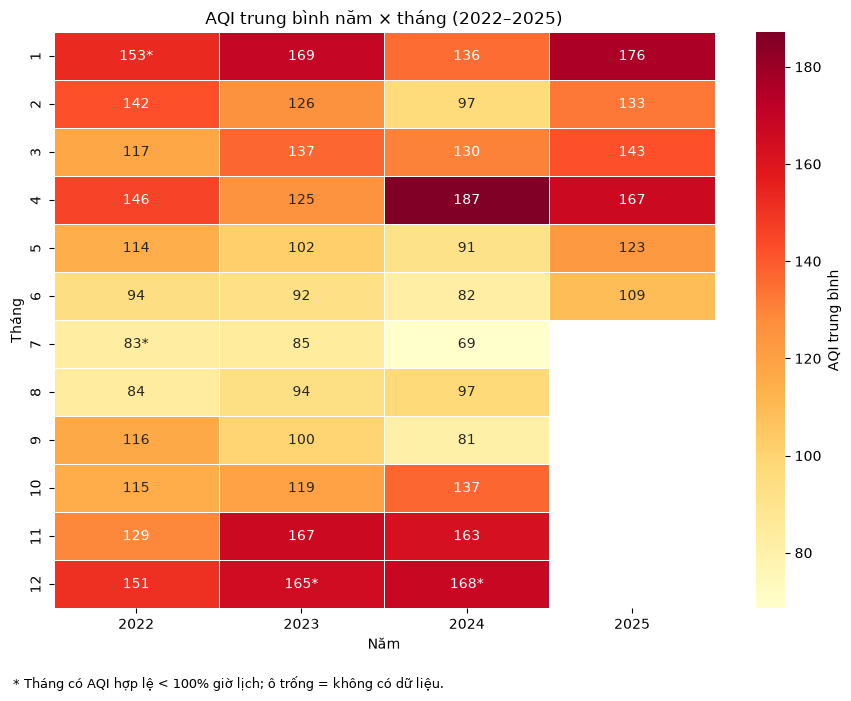

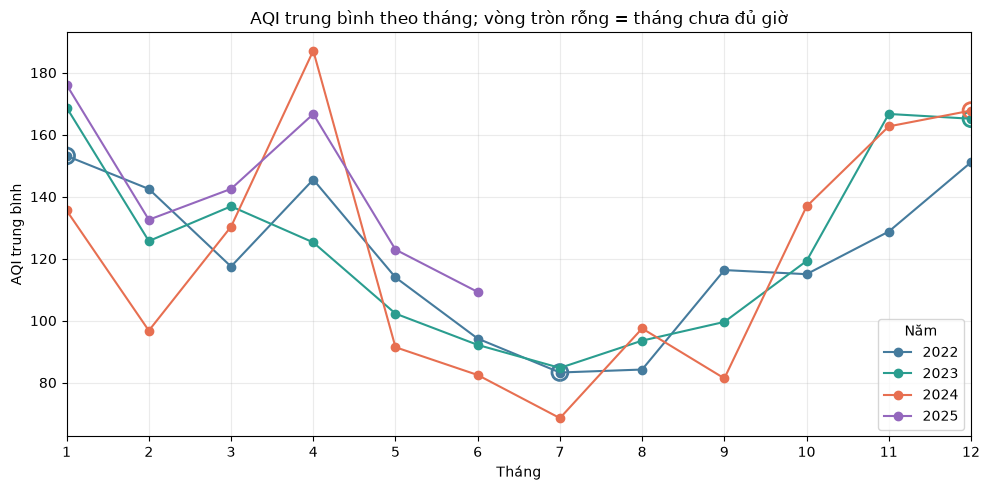

figures saved; partial months marked: [(2022, 1), (2022, 7), (2023, 12), (2024, 12)]


In [42]:
annotation=q2_pivot.copy().astype(object)
for m in q2_pivot.index:
    for y in q2_pivot.columns:
        value=q2_pivot.loc[m,y]
        annotation.loc[m,y]='' if pd.isna(value) else f'{value:.0f}'+('*' if q2_coverage.loc[(y,m),'aqi_coverage_pct']<100 else '')
fig,ax=plt.subplots(figsize=(9,7));sns.heatmap(q2_pivot,annot=annotation,fmt='',cmap='YlOrRd',mask=q2_pivot.isna(),linewidths=.4,cbar_kws={'label':'AQI trung bình'},ax=ax);ax.set(title='AQI trung bình năm × tháng (2022–2025)',xlabel='Năm',ylabel='Tháng');fig.text(.02,.01,'* Tháng có AQI hợp lệ < 100% giờ lịch; ô trống = không có dữ liệu.',fontsize=9);fig.tight_layout(rect=(0,.04,1,1));fig.savefig(project_root/'output/figures/q2_monthly_heatmap.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(10,5));colors=['#457b9d','#2a9d8f','#e76f51','#9467bd']
for color,y in zip(colors,q2_pivot.columns):
    series=q2_pivot[y];ax.plot(series.index,series.values,marker='o',label=str(y),color=color)
    partial=[m for m in range(1,13) if not pd.isna(series.loc[m]) and q2_coverage.loc[(y,m),'aqi_coverage_pct']<100]
    ax.scatter(partial,series.loc[partial],s=130,facecolors='none',edgecolors=color,linewidths=2)
ax.set(title='AQI trung bình theo tháng; vòng tròn rỗng = tháng chưa đủ giờ',xlabel='Tháng',ylabel='AQI trung bình',xticks=range(1,13),xlim=(1,12));ax.legend(title='Năm');ax.grid(alpha=.25);fig.tight_layout();fig.savefig(project_root/'output/figures/q2_monthly_lines.png',dpi=160);plt.show()
print('figures saved; partial months marked:',[(y,m) for y,m in q2_month.index if q2_coverage.loc[(y,m),'aqi_coverage_pct']<100])

### Kết luận bước 5.4

Heatmap và biểu đồ đường hiển thị đúng 12 tháng cho 2022–2024, chỉ 6 tháng đầu cho 2025; ô tháng 7–12/2025 để trắng. Bốn tháng thiếu giờ AQI được đánh dấu bằng dấu * trên heatmap và vòng tròn rỗng trên đường. Có hình dạng chung là AQI thấp hơn quanh tháng 6–8 và cao hơn ở một số tháng đầu/cuối năm, nhưng đỉnh tháng 04/2024 (187,09) khác các năm và cần đối chiếu độ nhạy. Hình chỉ mô tả các trung bình quan sát được; tính nhất quán sẽ được kiểm tra bằng thứ hạng và hệ số giữa các năm.

### Bước 5.5 — Thống kê AQI theo mùa

**Mục tiêu:** So sánh mức AQI và độ bao phủ của bốn nhóm mùa trong 2022–2024.

**Lý do:** Mùa đông của cùng năm dương lịch không liền nhau và các năm có giờ thiếu.

**Phương pháp:** Nhóm theo season_year/season, tính giờ AQI hợp lệ, ngày có AQI, mean, median, std, min/max; so với số giờ lịch, tính cao–thấp trong năm và vẽ cột nhóm.

**Kết quả cần quan sát:** Bảng mùa, chênh cao–thấp, độ bao phủ và biểu đồ 2022–2024.

SEASON STATS (calendar-year labels)
                    count    mean  median    std   min    max  days_with_valid_aqi  expected_hours  coverage_pct
season_year season                                                                                              
2022        Hè       2206   87.16    81.0  31.72  21.0  273.0                   92            2208         99.91
            Thu      2184  119.96   110.0  44.16  33.0  270.0                   91            2184        100.00
            Xuân     2208  125.42   112.0  53.45  21.0  475.0                   92            2208        100.00
            Đông     1872  148.50   151.0  51.91  33.0  276.0                   78            2160         86.67
2023        Hè       2208   90.13    85.0  33.12  21.0  266.0                   92            2208        100.00
            Thu      2184  128.40   107.0  66.04  25.0  487.0                   91            2184        100.00
            Xuân     2208  121.42   115.0  42.04  33.0  276.

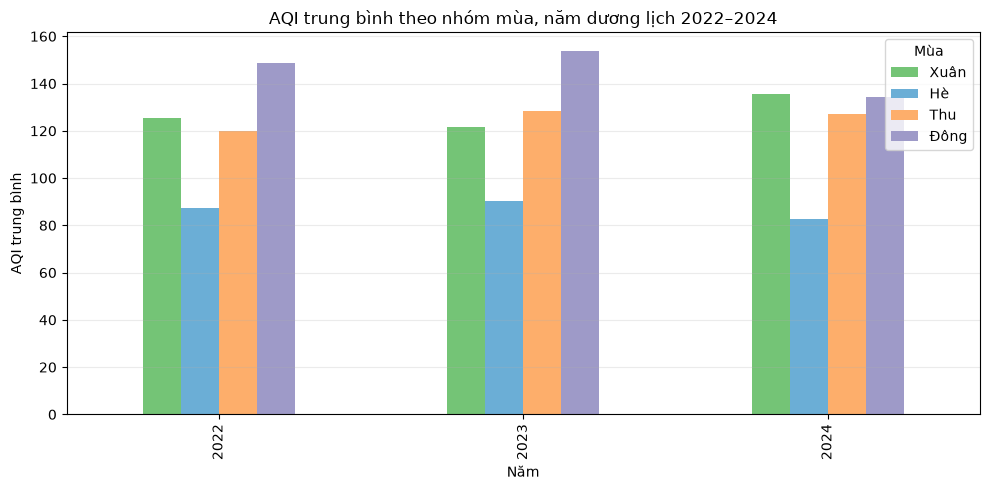

In [43]:
q2_primary=q2.loc[q2['year'].between(2022,2024)].copy()
q2_season=q2_primary.groupby(['season_year','season'])['AQI'].agg(['count','mean','median','std','min','max'])
q2_days=q2_primary.loc[q2_primary['AQI'].notna()].groupby(['season_year','season'])['Local Time'].apply(lambda s:s.dt.normalize().nunique())
q2_season['days_with_valid_aqi']=q2_days
q2_season['expected_hours']=[sum(pd.Period(f'{y}-{m:02d}').days_in_month*24 for m in range(1,13) if season_map[m]==s) for y,s in q2_season.index]
q2_season['coverage_pct']=100*q2_season['count']/q2_season['expected_hours']
print('SEASON STATS (calendar-year labels)');print(q2_season.round(2).to_string())
for y,g in q2_season.groupby(level=0):
    high=g['mean'].idxmax()[1];low=g['mean'].idxmin()[1];print(y,'highest',high,round(g.loc[(y,high),'mean'],2),'lowest',low,round(g.loc[(y,low),'mean'],2),'gap',round(g.loc[(y,high),'mean']-g.loc[(y,low),'mean'],2))
season_pivot=q2_season['mean'].unstack('season').reindex(columns=season_order)
fig,ax=plt.subplots(figsize=(10,5));season_pivot.plot(kind='bar',ax=ax,color=['#74c476','#6baed6','#fdae6b','#9e9ac8']);ax.set(title='AQI trung bình theo nhóm mùa, năm dương lịch 2022–2024',xlabel='Năm',ylabel='AQI trung bình');ax.legend(title='Mùa');ax.grid(axis='y',alpha=.25);fig.tight_layout();fig.savefig(project_root/'output/figures/q2_seasonal_means.png',dpi=160);plt.show()

### Kết luận bước 5.5

Theo quy ước năm dương lịch, hè có AQI trung bình thấp nhất ở cả ba năm: 87,16 (2022), 90,13 (2023), 82,83 (2024). Nhóm cao nhất là đông 2022 (148,50) và 2023 (153,98), nhưng xuân 2024 (135,72) nhỉnh hơn đông 2024 (134,15). Chênh cao–thấp lần lượt là 61,34; 63,85; 52,89 điểm AQI. Mỗi nhóm xuân/hè có 92 ngày hợp lệ, thu 91 ngày; đông có 78 ngày năm 2022 (86,67% giờ lịch), 89 ngày năm 2023 (98,89%) và 91 ngày năm 2024 (99,95%). Vì đông 2022 thiếu phần đầu tháng 1 và đông 2023 thiếu ngày cuối tháng 12, thứ hạng mùa cao nhất cần đọc cùng độ bao phủ. Nhóm đông gồm tháng 1–2 và 12 cùng năm, không biểu thị một mùa đông liên tục.

### Bước 5.6 — Kiểm tra tính lặp lại giữa các năm

**Mục tiêu:** Đối chiếu tháng/mùa cao thấp và độ ổn định thứ tự tháng.

**Lý do:** Một hình dạng tương tự không đủ chứng minh chu kỳ nhất quán.

**Phương pháp:** Xếp hạng tháng cao/thấp từng năm, tính Spearman giữa ba chuỗi 12 tháng 2022–2024; liệt kê thứ hạng mùa.

**Kết quả cần quan sát:** Bảng tháng cao/thấp, hệ số tương quan thứ hạng và các ngoại lệ.

In [44]:
for y in [2022,2023,2024,2025]:
    values=q2_pivot[y].dropna();print('MONTH',y,'highest',int(values.idxmax()),round(values.max(),2),'lowest',int(values.idxmin()),round(values.min(),2),'months',len(values))
print('MONTH RANK SPEARMAN 2022-2024');print(q2_pivot[[2022,2023,2024]].corr(method='spearman').round(3).to_string())
print('SEASON ORDER high-to-low');
for y,row in season_pivot.iterrows():print(y,row.sort_values(ascending=False).round(2).to_dict())
print('Monthly means for incomplete Jan2022 and Dec2023 require caution.')

MONTH 2022 highest 1 153.15 lowest 7 83.26 months 12
MONTH 2023 highest 1 168.75 lowest 7 84.75 months 12
MONTH 2024 highest 4 187.09 lowest 7 68.54 months 12
MONTH 2025 highest 1 176.08 lowest 6 109.26 months 6
MONTH RANK SPEARMAN 2022-2024
year   2022   2023   2024
year                     
2022  1.000  0.888  0.692
2023  0.888  1.000  0.720
2024  0.692  0.720  1.000
SEASON ORDER high-to-low
2022 {'Đông': 148.5, 'Xuân': 125.42, 'Thu': 119.96, 'Hè': 87.16}
2023 {'Đông': 153.98, 'Thu': 128.4, 'Xuân': 121.42, 'Hè': 90.13}
2024 {'Xuân': 135.72, 'Đông': 134.15, 'Thu': 127.07, 'Hè': 82.83}
Monthly means for incomplete Jan2022 and Dec2023 require caution.


### Kết luận bước 5.6

Tháng 7 có AQI trung bình thấp nhất trong cả 2022–2024: 83,26; 84,75; 68,54. Tháng cao nhất là tháng 1 của 2022 (153,15; chỉ 61,29% giờ lịch) và 2023 (168,75), nhưng là tháng 4 của 2024 (187,09). Hệ số Spearman giữa thứ hạng 12 tháng là 0,888 (2022–2023), 0,692 (2022–2024) và 0,720 (2023–2024): mẫu hình tương đồng tương đối nhưng không trùng khớp. Hè thấp nhất ở cả ba năm; mùa cao nhất là đông 2022–2023 và xuân 2024. Năm 2025 chỉ có 6 tháng, với tháng 1 cao nhất 176,08 và tháng 6 thấp nhất 109,26 trong phần đã quan sát; không dùng để kết luận cả năm. Cần kiểm tra độ nhạy của tháng 4/xuân 2024 trước khi xác nhận ngoại lệ.

### Bước 5.7 — Độ nhạy của mẫu hình 2024 với AQI = 500

**Mục tiêu:** Kiểm tra các giờ AQI=500 có làm đổi tháng/mùa cao nhất hay không.

**Lý do:** 59 giờ này tập trung ở nửa đầu 2024 và có thể ảnh hưởng xếp hạng.

**Phương pháp:** Lọc tạm AQI!=500 chỉ trong 2024, tính lại trung bình tháng/mùa và thứ hạng; giữ dataset chính.

**Kết quả cần quan sát:** Bảng chênh ở tháng/mùa bị ảnh hưởng và thứ hạng trước/sau.

In [45]:
q2_2024=q2_primary.loc[q2_primary['year']==2024];q2_2024_alt=q2_2024.loc[q2_2024['AQI']!=500]
month_base=q2_2024.groupby('month')['AQI'].mean();month_alt=q2_2024_alt.groupby('month')['AQI'].mean();season_base=q2_2024.groupby('season')['AQI'].mean();season_alt=q2_2024_alt.groupby('season')['AQI'].mean()
month_change=pd.DataFrame({'original':month_base,'without500':month_alt,'difference':month_alt-month_base,'n500':q2_2024.groupby('month')['AQI'].apply(lambda s:int((s==500).sum()))})
season_change=pd.DataFrame({'original':season_base,'without500':season_alt,'difference':season_alt-season_base,'n500':q2_2024.groupby('season')['AQI'].apply(lambda s:int((s==500).sum()))})
print('CHANGED MONTHS');print(month_change.loc[month_change['n500']>0].round(3).to_string())
print('CHANGED SEASONS');print(season_change.loc[season_change['n500']>0].round(3).to_string())
print('month high/low original',int(month_base.idxmax()),int(month_base.idxmin()),'without500',int(month_alt.idxmax()),int(month_alt.idxmin()))
print('season high/low original',season_base.idxmax(),season_base.idxmin(),'without500',season_alt.idxmax(),season_alt.idxmin())
print('AQI=500 retained in main dataset',int((q2_2024['AQI']==500).sum()))

CHANGED MONTHS
       original  without500  difference  n500
month                                        
2        96.772      96.191      -0.580     1
4       187.093     159.678     -27.415    58
CHANGED SEASONS
        original  without500  difference  n500
season                                        
Xuân     135.725     125.898      -9.827    58
Đông     134.148     133.980      -0.168     1
month high/low original 4 7 without500 12 7
season high/low original Xuân Hè without500 Đông Hè
AQI=500 retained in main dataset 59


### Kết luận bước 5.7

Trong 2024 có 59 giờ AQI=500: 58 giờ ở tháng 4 và 1 giờ ở tháng 2. Khi tạm bỏ các giờ này khỏi phép tính, trung bình tháng 4 giảm từ 187,093 xuống 159,678 (−27,415), tháng 2 từ 96,772 xuống 96,191 (−0,580). Trung bình xuân giảm từ 135,725 xuống 125,898 (−9,827), đông từ 134,148 xuống 133,980 (−0,168). Tháng cao nhất của 2024 đổi từ tháng 4 sang tháng 12; mùa cao nhất đổi từ xuân sang đông. Tháng 7 và hè vẫn thấp nhất. Do đó, kết luận về đỉnh tháng/mùa 2024 nhạy với các giá trị 500, còn kết luận về giai đoạn thấp nhất bền hơn. Đây chỉ là đối chiếu tạm; AQI=500 chưa được chứng minh sai và vẫn giữ nguyên trong dữ liệu chính.

### Bước 5.8 — Tổng hợp bằng chứng trả lời Câu hỏi 2

**Mục tiêu:** Tổng hợp mức lặp lại, ngoại lệ và giới hạn độ bao phủ.

**Lý do:** Kết luận cần dựa trên nhiều năm và độ nhạy, không chỉ nhìn một biểu đồ.

**Phương pháp:** In bảng tháng/mùa cao-thấp, tương quan thứ hạng và các tháng thiếu dữ liệu; kết luận viết sau khi đọc output.

**Kết quả cần quan sát:** Bằng chứng ngắn gọn cho câu trả lời cuối cùng, không suy luận nguyên nhân.

In [46]:
for y in [2022,2023,2024]:
    months=q2_pivot[y];seasons=season_pivot.loc[y]
    print(y,'month high/low',int(months.idxmax()),int(months.idxmin()),'season high/low',seasons.idxmax(),seasons.idxmin(),'partial months',[(m,round(q2_coverage.loc[(y,m),'aqi_coverage_pct'],2)) for m in range(1,13) if q2_coverage.loc[(y,m),'aqi_coverage_pct']<100])
print('Spearman pairs',q2_pivot[[2022,2023,2024]].corr(method='spearman').loc[2022,2023],q2_pivot[[2022,2023,2024]].corr(method='spearman').loc[2022,2024],q2_pivot[[2022,2023,2024]].corr(method='spearman').loc[2023,2024])
print('2025 only observed months',q2_pivot[2025].dropna().index.tolist())

2022 month high/low 1 7 season high/low Đông Hè partial months [(1, np.float64(61.29)), (7, np.float64(99.73))]
2023 month high/low 1 7 season high/low Đông Hè partial months [(12, np.float64(96.77))]
2024 month high/low 4 7 season high/low Xuân Hè partial months [(12, np.float64(99.87))]
Spearman pairs 0.8881118881118881 0.6923076923076923 0.7202797202797203
2025 only observed months [1, 2, 3, 4, 5, 6]


### Kết luận bước 5.8

**Trả lời Câu hỏi 2:** Có mẫu hình theo tháng và nhóm mùa lặp lại một phần, rõ nhất ở giai đoạn AQI thấp: tháng 7 thấp nhất cả ba năm 2022–2024 (83,26; 84,75; 68,54) và hè là nhóm mùa thấp nhất (87,16; 90,13; 82,83). Mẫu hình AQI cao kém nhất quán: tháng 1 cao nhất ở 2022–2023 (153,15; 168,75), còn tháng 4 cao nhất ở 2024 (187,09); đông cao nhất ở 2022–2023 (148,50; 153,98), còn xuân cao nhất ở 2024 (135,72). Tương quan Spearman thứ hạng tháng giữa các cặp năm là 0,888; 0,692; 0,720, cho thấy tương đồng nhưng không đồng nhất. Ngoại lệ đỉnh 2024 nhạy với 59 giờ AQI=500: lọc tạm làm đỉnh tháng chuyển sang tháng 12 và đỉnh mùa chuyển sang đông; dữ liệu chính vẫn giữ các giờ này. Tháng 01/2022 chỉ bao phủ 61,29% và tháng 12/2023 96,77%, làm giảm độ chắc chắn của so sánh đỉnh. Năm 2025 chỉ có tháng 1–6 nên không dùng để xác nhận chu kỳ 12 tháng. Nhóm mùa là quy ước lịch và phân tích mô tả này không chứng minh nguyên nhân hoặc chu kỳ ổn định dài hạn.

## Giai đoạn 6 — Câu hỏi nghiên cứu 3

**Câu hỏi:** Các chỉ số PM2.5, PM10, CO, NO2, O3 và SO2 có mối liên hệ thống kê như thế nào với AQI tại Hà Nội?

Dùng dữ liệu đã làm sạch, xét từng cặp AQI–chất ô nhiễm trên toàn bộ giờ hợp lệ và theo năm. Tương quan không chứng minh quan hệ nhân quả; đơn vị đo và công thức AQI của nguồn chưa được xác minh.

### Bước 6.1 — Dữ liệu và cặp quan sát hợp lệ

**Mục tiêu:** Xác định kiểu số, số cặp AQI–chất ô nhiễm dùng được và nguồn gốc ô thiếu.

**Lý do:** Mỗi hệ số cần mẫu số riêng; các ô thiếu do giải quyết xung đột phải được phân biệt với ô thiếu cũ.

**Phương pháp:** Đọc bảng kiểm toán; đếm NaN từng cột và số cặp hợp lệ bằng notna(), không điền hoặc xóa cả dòng.

**Kết quả cần quan sát:** Bảng kiểu dữ liệu, số cặp hợp lệ và số ô thiếu cũ/mới.

In [47]:
pollutants=['PM25','PM10','CO','NO2','O3','SO2']
q3=eda[['Local Time','AQI']+pollutants].copy()
audit_q3=pd.read_csv(project_root/'output/tables/duplicate_conflicts_audit.csv')
new_missing=audit_q3['column'].value_counts()
quality=pd.DataFrame(index=['AQI']+pollutants)
quality['dtype']=q3[quality.index].dtypes.astype(str)
quality['valid_hours']=q3[quality.index].count()
quality['missing_total']=q3[quality.index].isna().sum()
quality['missing_from_conflict']=new_missing.reindex(quality.index,fill_value=0).astype(int)
quality['missing_in_original']=quality['missing_total']-quality['missing_from_conflict']
quality['valid_aqi_pairs']=[q3[['AQI',col]].dropna().shape[0] if col!='AQI' else q3['AQI'].count() for col in quality.index]
print(quality.to_string())
print('audit conflict cells all variables=',len(audit_q3),'AQI/pollutants=',int(quality['missing_from_conflict'].sum()))
print('negative old missing=',int((quality['missing_in_original']<0).sum()))

        dtype  valid_hours  missing_total  missing_from_conflict  missing_in_original  valid_aqi_pairs
AQI   float64        30333              3                      1                    2            30333
PM25  float64        30333              3                      1                    2            30333
PM10  float64        30333              3                      1                    2            30333
CO    float64        30260             76                      2                   74            30259
NO2   float64        30261             75                      1                   74            30260
O3    float64        30259             77                      3                   74            30258
SO2   float64        30258             78                      4                   74            30257
audit conflict cells all variables= 13 AQI/pollutants= 13
negative old missing= 0


### Kết luận bước 6.1

Cả AQI và sáu chất đều có kiểu `float64`. AQI, PM25 và PM10 mỗi cột có 30.333 giờ hợp lệ; CO 30.260, NO2 30.261, O3 30.259 và SO2 30.258. Số cặp AQI–chất hợp lệ lần lượt là PM25/PM10 30.333, CO 30.259, NO2 30.260, O3 30.258, SO2 30.257. Trong 13 ô thiếu mới do 5 giờ xung đột có AQI 1, PM25 1, PM10 1, CO 2, NO2 1, O3 3, SO2 4; phần thiếu gốc tương ứng là 2, 2, 2, 74, 74, 74, 74. Mỗi cặp sẽ được tính trên các giờ hai biến cùng hợp lệ; không điền NaN hoặc loại cả dòng khỏi mọi phép tính.

### Bước 6.2 — Phân phối lệch và giá trị cực trị

**Mục tiêu:** Kiểm tra các đặc điểm cần cân nhắc khi chọn Pearson/Spearman.

**Lý do:** Pearson nhạy với điểm cực trị và quan hệ cong; không được tự coi cực trị là lỗi.

**Phương pháp:** Tính trung vị, phân vị 99%, max và độ lệch (skew) trên dữ liệu không thiếu; đếm AQI=500.

**Kết quả cần quan sát:** Bảng mức lệch và cực trị cho AQI cùng sáu chất.

In [48]:
shape=q3[['AQI']+pollutants].agg(['median','max','skew']).T
shape['p99']=q3[['AQI']+pollutants].quantile(.99)
shape['max_over_p99']=shape['max']/shape['p99']
print(shape[['median','p99','max','skew','max_over_p99']].round(3).to_string())
print('AQI=500 by year',q3.loc[q3['AQI']==500,'Local Time'].dt.year.value_counts().sort_index().to_dict())

      median       p99      max   skew  max_over_p99
AQI   112.00   270.000    500.0  1.494         1.852
PM25   39.33   212.000    457.0  2.780         2.156
PM10   52.20   305.000   1103.0  6.925         3.616
CO    181.50  3643.946  15956.2  5.840         4.379
NO2    18.00   154.000    378.0  3.524         2.455
O3     48.70   192.700    700.0  1.457         3.633
SO2    55.70   207.700    721.0  4.827         3.471
AQI=500 by year {2024: 59}


### Kết luận bước 6.2

Cả AQI và sáu chất có skew dương: AQI 1,494; PM25 2,780; PM10 6,925; CO 5,840; NO2 3,524; O3 1,457; SO2 4,827. Max lớn hơn phân vị 99% khoảng 1,85 lần với AQI và 2,16–4,38 lần với các chất; ví dụ PM10 max 1.103 so với p99=305, CO max 15.956,2 so với p99=3.643,946. Có 59 giờ AQI=500, đều trong 2024. Đây là giá trị cực trị chưa được xác minh là sai, nên giữ nguyên và đối chiếu Pearson với Spearman; sẽ kiểm tra riêng độ nhạy AQI=500 ở 2024.

### Bước 6.3 — Tương quan Pearson theo từng cặp

**Mục tiêu:** Đo chiều và độ lớn liên hệ tuyến tính giữa AQI với từng chất.

**Lý do:** Cần công bố số cặp hợp lệ và không dùng Pearson đơn độc khi biến lệch/có cực trị.

**Phương pháp:** Dùng Series.corr(method="pearson") trên từng cặp dropna; xếp độ lớn tuyệt đối.

**Kết quả cần quan sát:** Sáu hệ số Pearson cùng số cặp và nhóm độ lớn.

In [49]:
pearson_rows=[]
for col in pollutants:
    pair=q3[['AQI',col]].dropna()
    pearson_rows.append({'pollutant':col,'n_pairs':len(pair),'pearson':pair['AQI'].corr(pair[col],method='pearson')})
pearson_table=pd.DataFrame(pearson_rows).set_index('pollutant')
def strength(value):
    a=abs(value)
    return 'mạnh' if a>=.7 else ('vừa' if a>=.3 else 'yếu')
pearson_table['absolute_strength']=pearson_table['pearson'].map(strength)
print('Operational bands: |r| >=0.7 strong; 0.3-<0.7 moderate; <0.3 weak; descriptive only.')
print(pearson_table.sort_values('pearson',key=lambda s:s.abs(),ascending=False).round(4).to_string())

Operational bands: |r| >=0.7 strong; 0.3-<0.7 moderate; <0.3 weak; descriptive only.
           n_pairs  pearson absolute_strength
pollutant                                    
PM10         30333   0.8195              mạnh
PM25         30333   0.8107              mạnh
NO2          30260   0.2540               yếu
SO2          30257   0.2022               yếu
CO           30259  -0.0176               yếu
O3           30258  -0.0099               yếu


### Kết luận bước 6.3

Theo Pearson trên từng cặp hợp lệ, PM10 có hệ số dương lớn nhất 0,8195 (30.333 cặp), kế đến PM25 0,8107 (30.333 cặp). NO2 0,2540 và SO2 0,2022 là dương nhưng yếu theo quy ước mô tả |r|<0,3; CO −0,0176 và O3 −0,0099 gần 0. O3 yếu nhất theo trị tuyệt đối Pearson. Ngưỡng |r|≥0,7 mạnh, 0,3–<0,7 vừa, <0,3 yếu chỉ là cách tóm tắt cho đồ án, không phải kiểm định hay bằng chứng nhân quả. Vì phân phối lệch và có cực trị, cần đối chiếu Spearman trước khi chốt thứ hạng liên hệ.

### Bước 6.4 — Tương quan Spearman và đối chiếu Pearson

**Mục tiêu:** Đo liên hệ đơn điệu qua thứ hạng và xem phương pháp có thay đổi diễn giải hay không.

**Lý do:** Spearman ít nhạy hơn với giá trị cực trị; khác biệt với Pearson có thể do cực trị hoặc dạng quan hệ, chưa phân định nguyên nhân.

**Phương pháp:** Tính Spearman trên đúng từng cặp hợp lệ, ghép Pearson và chênh lệch tuyệt đối.

**Kết quả cần quan sát:** Bảng hai phương pháp, số cặp và mức chênh.

In [50]:
corr_table=pearson_table[['n_pairs','pearson']].copy()
corr_table['spearman']=[q3[['AQI',col]].dropna().corr(method='spearman').loc['AQI',col] for col in pollutants]
corr_table['spearman_minus_pearson']=corr_table['spearman']-corr_table['pearson']
corr_table['absolute_gap']=corr_table['spearman_minus_pearson'].abs()
print(corr_table.sort_values('absolute_gap',ascending=False).round(4).to_string())
print('Pearson: linear values; Spearman: monotonic ranks. Neither proves causality.')

           n_pairs  pearson  spearman  spearman_minus_pearson  absolute_gap
pollutant                                                                  
PM25         30333   0.8107    0.9850                  0.1743        0.1743
PM10         30333   0.8195    0.9545                  0.1351        0.1351
CO           30259  -0.0176    0.1076                  0.1252        0.1252
SO2          30257   0.2022    0.2649                  0.0627        0.0627
NO2          30260   0.2540    0.2107                 -0.0433        0.0433
O3           30258  -0.0099   -0.0017                  0.0082        0.0082
Pearson: linear values; Spearman: monotonic ranks. Neither proves causality.


### Kết luận bước 6.4

Spearman cho PM25=0,9850 và PM10=0,9545, đều dương rất cao; cao hơn Pearson lần lượt 0,1743 và 0,1351. PM25 đứng đầu theo Spearman, còn PM10 đứng đầu theo Pearson. NO2=0,2107 và SO2=0,2649 dương yếu, O3=−0,0017 gần 0. CO=0,1076 dương yếu trong khi Pearson=−0,0176 gần 0, nên chiều CO không ổn định theo phương pháp và không có cơ sở diễn giải là liên hệ đáng kể. Pearson đo mức tuyến tính trên giá trị gốc; Spearman đo mức đơn điệu trên thứ hạng, ít nhạy hơn với cực trị. Chênh lệch có thể liên quan cực trị hoặc hình dạng quan hệ, chưa đủ để quy về một nguyên nhân.

### Bước 6.5 — Biểu đồ hệ số và mối liên hệ

**Mục tiêu:** Cho thấy sáu hệ số và hình dạng của một số cặp đáng chú ý.

**Lý do:** Hơn 30.000 giờ sẽ chồng điểm nếu scatter thường; hệ số chính phải dựa trên toàn bộ cặp hợp lệ.

**Phương pháp:** Vẽ heatmap hai hàng Pearson/Spearman và ba hexbin từ toàn bộ cặp hợp lệ, không vẽ đường hồi quy.

**Kết quả cần quan sát:** Hai hình: hệ số và mật độ AQI với PM10, PM25, CO.

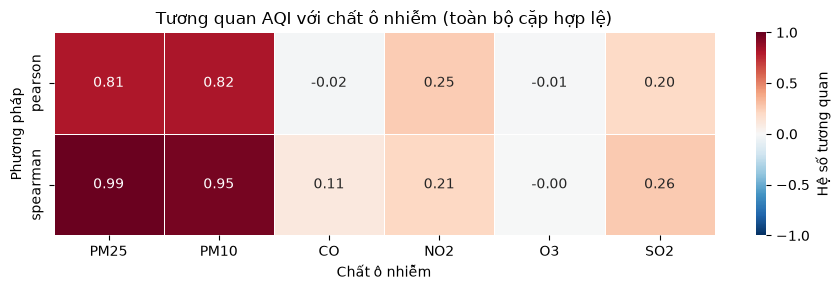

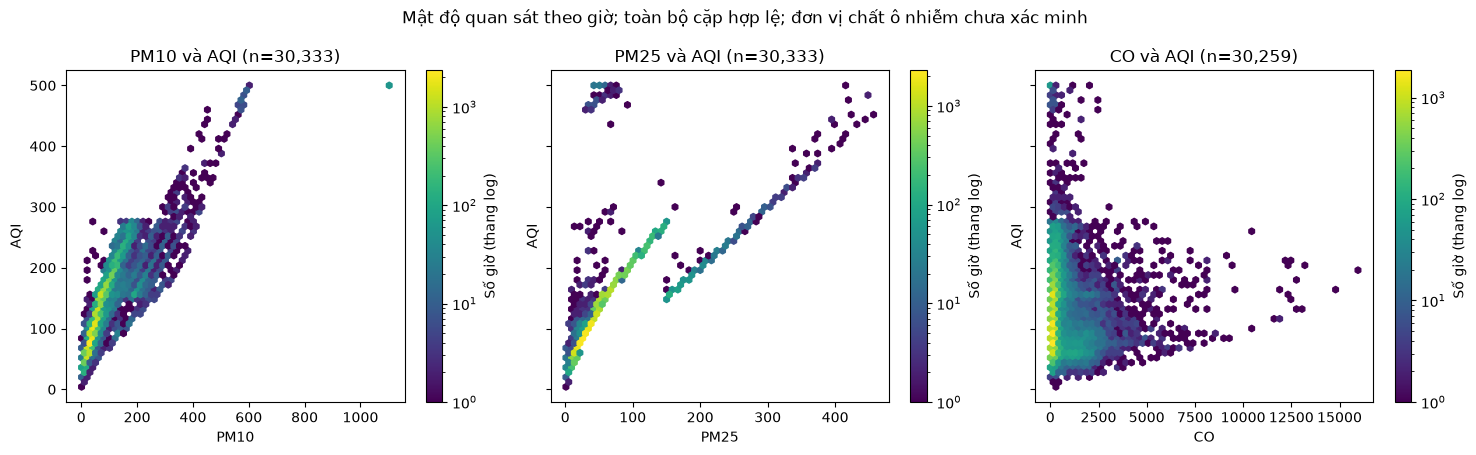

In [51]:
fig,ax=plt.subplots(figsize=(9,3))
sns.heatmap(corr_table[['pearson','spearman']].T,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='RdBu_r',linewidths=.5,cbar_kws={'label':'Hệ số tương quan'},ax=ax)
ax.set(title='Tương quan AQI với chất ô nhiễm (toàn bộ cặp hợp lệ)',xlabel='Chất ô nhiễm',ylabel='Phương pháp')
fig.tight_layout();fig.savefig(project_root/'output/figures/q3_correlation_heatmap.png',dpi=160);plt.show()
fig,axes=plt.subplots(1,3,figsize=(15,4.6),sharey=True)
for ax,col in zip(axes,['PM10','PM25','CO']):
    pair=q3[['AQI',col]].dropna()
    hb=ax.hexbin(pair[col],pair['AQI'],gridsize=55,mincnt=1,bins='log',cmap='viridis')
    ax.set(title=f'{col} và AQI (n={len(pair):,})',xlabel=col,ylabel='AQI')
    fig.colorbar(hb,ax=ax,label='Số giờ (thang log)')
fig.suptitle('Mật độ quan sát theo giờ; toàn bộ cặp hợp lệ; đơn vị chất ô nhiễm chưa xác minh')
fig.tight_layout();fig.savefig(project_root/'output/figures/q3_pollutant_hexbins.png',dpi=160);plt.show()

### Kết luận bước 6.5

Heatmap phản ánh đúng bảng hệ số: PM25 và PM10 có liên hệ dương lớn theo cả hai phương pháp; CO và O3 gần 0 theo Pearson, O3 gần 0 theo Spearman. Ba hexbin dùng toàn bộ cặp hợp lệ (PM10/PM25 30.333; CO 30.259), mật độ hiển thị theo thang log để tránh chồng điểm. PM25–AQI có dải điểm tăng theo các đoạn, PM10–AQI phân tán hơn, còn CO–AQI không cho thấy một dải tăng tuyến tính rõ; có các điểm AQI=500 nằm ngoài vùng dày đặc. Hình gợi ý dạng quan hệ và cực trị có thể ảnh hưởng Pearson; không chỉ ra công thức AQI hay quan hệ nhân quả. Không gán đơn vị cho các chỉ số chất ô nhiễm vì chưa xác minh nguồn.

### Bước 6.6 — Tương quan riêng từng năm

**Mục tiêu:** Kiểm tra chiều và độ lớn hệ số có ổn định từ 2022 đến 2025.

**Lý do:** Tương quan chung có thể khác từng năm; 2025 chỉ bao phủ sáu tháng.

**Phương pháp:** Tách năm từ Local Time; tính Pearson và Spearman với số cặp riêng từng năm.

**Kết quả cần quan sát:** Hai bảng năm × chất và số cặp; phạm vi 2025 được chú thích.

In [52]:
q3['year']=q3['Local Time'].dt.year
year_rows=[]
for (year,col) in [(y,c) for y in sorted(q3['year'].dropna().unique()) for c in pollutants]:
    pair=q3.loc[q3['year']==year,['AQI',col]].dropna()
    year_rows.append({'year':int(year),'pollutant':col,'n_pairs':len(pair),'pearson':pair['AQI'].corr(pair[col]),'spearman':pair['AQI'].corr(pair[col],method='spearman')})
year_corr=pd.DataFrame(year_rows)
print('PEARSON BY YEAR');print(year_corr.pivot(index='year',columns='pollutant',values='pearson')[pollutants].round(3).to_string())
print('SPEARMAN BY YEAR');print(year_corr.pivot(index='year',columns='pollutant',values='spearman')[pollutants].round(3).to_string())
print('VALID PAIRS BY YEAR');print(year_corr.pivot(index='year',columns='pollutant',values='n_pairs')[pollutants].to_string())
print('2025 months',sorted(q3.loc[q3['year']==2025,'Local Time'].dt.month.unique().tolist()))

PEARSON BY YEAR
pollutant   PM25   PM10     CO    NO2     O3    SO2
year                                               
2022       0.884  0.874  0.519  0.343 -0.089  0.297
2023       0.873  0.884  0.291  0.452 -0.124  0.225
2024       0.716  0.814 -0.129  0.030  0.168  0.250
2025       0.852  0.796  0.106  0.139 -0.140  0.096
SPEARMAN BY YEAR
pollutant   PM25   PM10     CO    NO2     O3    SO2
year                                               
2022       0.991  0.985  0.568  0.283 -0.057  0.266
2023       0.992  0.985  0.517  0.367 -0.124  0.256
2024       0.976  0.931 -0.264 -0.085  0.162  0.333
2025       0.975  0.879  0.111  0.212 -0.167  0.054
VALID PAIRS BY YEAR
pollutant  PM25  PM10    CO   NO2    O3   SO2
year                                         
2022       8470  8470  8398  8398  8398  8398
2023       8736  8736  8736  8736  8736  8736
2024       8783  8783  8782  8782  8781  8780
2025       4344  4344  4343  4344  4343  4343
2025 months [1, 2, 3, 4, 5, 6]


### Kết luận bước 6.6

PM25 và PM10 giữ tương quan dương mạnh trong từng năm: Pearson PM25 0,716–0,884, PM10 0,796–0,884; Spearman PM25 0,975–0,992, PM10 0,879–0,985. Các chất khác kém ổn định hơn. CO Pearson từ 0,519 (2022) xuống −0,129 (2024), trong khi hệ số gộp gần 0; NO2 Pearson từ 0,452 (2023) xuống 0,030 (2024), và Spearman 2024 là −0,085. O3 đổi dấu giữa 2024 (+0,168 Pearson) và các năm còn lại (âm); SO2 dương nhưng mức thay đổi. Năm 2025 chỉ có tháng 1–6 và khoảng 4.343–4.344 cặp mỗi chất, nên không so trực tiếp với một năm trọn vẹn như bằng chứng chu kỳ ổn định. Kết quả gộp cần đọc cùng bảng từng năm.

### Bước 6.7 — Độ nhạy năm 2024 với AQI = 500

**Mục tiêu:** Xem 59 giờ AQI=500 ảnh hưởng hệ số tới đâu.

**Lý do:** Cực trị có thể thay đổi Pearson, nhất là khi quan hệ không tuyến tính; chỉ lọc tạm để đối chiếu.

**Phương pháp:** Tính lại Pearson/Spearman 2024 sau khi lọc AQI=500, giữ nguyên dữ liệu chính.

**Kết quả cần quan sát:** Bảng chênh hệ số từng chất và số cặp bị loại.

In [53]:
base_2024=q3.loc[q3['year']==2024]
temporary_2024=base_2024.loc[base_2024['AQI']!=500]
sensitivity=[]
for col in pollutants:
    a=base_2024[['AQI',col]].dropna();b=temporary_2024[['AQI',col]].dropna()
    sensitivity.append({'pollutant':col,'n_original':len(a),'n_without500':len(b),'pearson_original':a['AQI'].corr(a[col]),'pearson_without500':b['AQI'].corr(b[col]),'spearman_original':a['AQI'].corr(a[col],method='spearman'),'spearman_without500':b['AQI'].corr(b[col],method='spearman')})
sensitivity=pd.DataFrame(sensitivity).set_index('pollutant')
sensitivity['pearson_change']=sensitivity['pearson_without500']-sensitivity['pearson_original']
sensitivity['spearman_change']=sensitivity['spearman_without500']-sensitivity['spearman_original']
print(sensitivity.round(4).to_string())
print('filtered AQI=500 hours',int((base_2024['AQI']==500).sum()),'main dataset unchanged')

           n_original  n_without500  pearson_original  pearson_without500  spearman_original  spearman_without500  pearson_change  spearman_change
pollutant                                                                                                                                         
PM25             8783          8724            0.7163              0.8017             0.9759               0.9798          0.0854           0.0039
PM10             8783          8724            0.8139              0.8383             0.9313               0.9299          0.0245          -0.0014
CO               8782          8723           -0.1288             -0.1172            -0.2645              -0.2541          0.0116           0.0103
NO2              8782          8723            0.0300              0.0562            -0.0847              -0.0759          0.0262           0.0088
O3               8781          8722            0.1676              0.1616             0.1621               0.1531     

### Kết luận bước 6.7

Lọc tạm 59 giờ AQI=500 trong 2024 làm Pearson PM25 tăng từ 0,7163 lên 0,8017 (Δ+0,0854), là thay đổi lớn nhất; PM10 tăng 0,8139→0,8383 (Δ+0,0245). Spearman PM25 chỉ tăng 0,9759→0,9798 (Δ+0,0039), PM10 giảm 0,9313→0,9299 (Δ−0,0014). Hệ số CO, NO2, O3, SO2 thay đổi Pearson không quá 0,0262 và Spearman không quá 0,0103. Vì vậy cực trị AQI=500 làm giảm đáng kể độ lớn Pearson PM25 năm 2024, nhưng không đổi dấu, không làm mất liên hệ mạnh PM25/PM10 và không đổi thứ hạng mạnh/yếu chính trong năm. Đây là phép đối chiếu; dữ liệu chính vẫn giữ đủ 59 giờ.

### Bước 6.8 — Giá trị bằng nhau và khả năng AQI phụ thuộc chỉ số

**Mục tiêu:** Kiểm tra dấu hiệu trùng giá trị số và tránh coi AQI độc lập với các chỉ số đầu vào.

**Lý do:** Không có tài liệu công thức từ nguồn nên hệ số cao hoặc số bằng nhau không chứng minh cách tính AQI.

**Phương pháp:** Đếm AQI bằng chính xác từng chỉ số trong cặp hợp lệ; đối chiếu với tương quan.

**Kết quả cần quan sát:** Bảng số giờ bằng nhau và tỷ lệ theo chất.

In [54]:
equal_rows=[]
for col in pollutants:
    pair=q3[['AQI',col]].dropna()
    n_equal=int((pair['AQI']==pair[col]).sum())
    equal_rows.append({'pollutant':col,'n_pairs':len(pair),'equal_numeric_hours':n_equal,'equal_pct':100*n_equal/len(pair)})
equal_table=pd.DataFrame(equal_rows).set_index('pollutant')
print(equal_table.round(3).to_string())
print('AQI formula and pollutant units unverified; numeric equality is descriptive, not proof of formula.')

           n_pairs  equal_numeric_hours  equal_pct
pollutant                                         
PM25         30333                  791      2.608
PM10         30333                  119      0.392
CO           30259                   14      0.046
NO2          30260                   12      0.040
O3           30258                   55      0.182
SO2          30257                   62      0.205
AQI formula and pollutant units unverified; numeric equality is descriptive, not proof of formula.


### Kết luận bước 6.8

Có 791/30.333 cặp AQI–PM25 bằng nhau về mặt số học (2,608%), 119 cặp với PM10 (0,392%); các chất còn lại có 12–62 cặp bằng nhau (0,040–0,205%). Số trùng giá trị cùng với Spearman PM25=0,9850 và hình dạng theo các dải là dấu hiệu cần xem xét khả năng AQI phụ thuộc vào dữ liệu chất ô nhiễm. Tuy nhiên, đơn vị các chất và tài liệu công thức AQI của nguồn chưa được xác minh; bằng nhau về số hoặc tương quan cao không đủ chứng minh công thức, cũng không phải căn cứ gọi các dòng này là lỗi. Không coi AQI và các chất là các biến độc lập về nguồn gốc khi diễn giải.

### Bước 6.9 — Bằng chứng trả lời Câu hỏi 3

**Mục tiêu:** Tổng hợp chất liên hệ mạnh/yếu, tính ổn định và giới hạn trước khi kết luận.

**Lý do:** Câu trả lời phải truy lại các bảng đã chạy, không suy luận nguyên nhân.

**Phương pháp:** In xếp hạng theo trị tuyệt đối Pearson/Spearman, biên độ hệ số theo năm và độ nhạy 2024.

**Kết quả cần quan sát:** Bảng chứng cứ ngắn cho kết luận cuối.

In [55]:
print('GLOBAL |PEARSON| ORDER');print(corr_table['pearson'].abs().sort_values(ascending=False).round(3).to_string())
print('GLOBAL |SPEARMAN| ORDER');print(corr_table['spearman'].abs().sort_values(ascending=False).round(3).to_string())
print('YEARLY PEARSON MIN/MAX');print(year_corr.groupby('pollutant')['pearson'].agg(['min','max']).reindex(pollutants).round(3).to_string())
print('MAX 2024 SENSITIVITY Pearson',sensitivity['pearson_change'].abs().idxmax(),round(sensitivity['pearson_change'].abs().max(),3),'Spearman',sensitivity['spearman_change'].abs().idxmax(),round(sensitivity['spearman_change'].abs().max(),3))

GLOBAL |PEARSON| ORDER
pollutant
PM10    0.819
PM25    0.811
NO2     0.254
SO2     0.202
CO      0.018
O3      0.010
GLOBAL |SPEARMAN| ORDER
pollutant
PM25    0.985
PM10    0.955
SO2     0.265
NO2     0.211
CO      0.108
O3      0.002
YEARLY PEARSON MIN/MAX
             min    max
pollutant              
PM25       0.716  0.884
PM10       0.796  0.884
CO        -0.129  0.519
NO2        0.030  0.452
O3        -0.140  0.168
SO2        0.096  0.297
MAX 2024 SENSITIVITY Pearson PM25 0.085 Spearman CO 0.01


### Kết luận bước 6.9

**Trả lời Câu hỏi 3:** PM25 và PM10 có liên hệ thống kê dương mạnh nhất với AQI. Theo Pearson, PM10 đứng đầu (0,8195), kế đến PM25 (0,8107); theo Spearman, PM25 đứng đầu (0,9850), kế đến PM10 (0,9545). O3 yếu nhất theo trị tuyệt đối ở cả hai phương pháp (Pearson −0,0099; Spearman −0,0017). NO2 và SO2 dương nhưng yếu trên toàn kỳ (Pearson 0,2540 và 0,2022; Spearman 0,2107 và 0,2649); CO gần 0 theo Pearson (−0,0176), dương yếu theo Spearman (0,1076). PM25/PM10 duy trì chiều dương mạnh qua cả bốn năm, còn CO và O3 đổi dấu giữa các năm, NO2/SO2 thay đổi độ lớn. Chênh Pearson–Spearman của PM25 0,1743 và PM10 0,1351 phù hợp với việc quan hệ theo thứ hạng rõ hơn tuyến tính giá trị gốc; chưa xác định nguyên nhân của chênh lệch. Lọc tạm 59 giờ AQI=500 trong 2024 làm Pearson PM25 tăng 0,0854 nhưng không đổi kết luận PM25/PM10 mạnh; dữ liệu chính giữ nguyên. AQI có thể được xây dựng từ các chỉ số chất ô nhiễm: 791 giờ AQI bằng số PM25, nhưng thiếu tài liệu nguồn để xác định công thức. Đây là tương quan mô tả trên dữ liệu giờ, không chứng minh chất nào gây AQI hoặc là nguyên nhân ô nhiễm; đơn vị các chất chưa xác minh và 2025 chỉ có sáu tháng.

## Giai đoạn 7 — Câu hỏi nghiên cứu 4

**Câu hỏi:** Các yếu tố thời tiết như nhiệt độ, độ ẩm, lượng mưa và tốc độ gió có mối liên hệ như thế nào với AQI tại Hà Nội?

Phân tích dữ liệu giờ đã làm sạch, dùng Local Time và cùng quy ước mùa ở Câu hỏi 2. Pressure được đối chiếu thêm vì tương quan khám phá đáng chú ý. Đơn vị các biến thời tiết chưa xác minh; khác biệt quan sát và tương quan không chứng minh quan hệ nhân quả.

### Bước 7.1 — Kiểm tra dữ liệu thời tiết và AQI

**Mục tiêu:** Xác định kiểu, số cặp hợp lệ và phạm vi biến thời tiết.

**Lý do:** Cần biết số giờ dùng cho mỗi hệ số và mức thiếu trước khi so sánh.

**Phương pháp:** Đọc bản sao dữ liệu đã sạch; đếm cặp AQI–biến và min, median, max; không điền NaN.

**Kết quả cần quan sát:** Bảng chất lượng cho bốn biến chính và Pressure bổ sung.

In [56]:
weather=['Temperature','Relative Humidity','Precipitation','Wind Speed']
weather_extra=['Pressure']
q4=eda[['Local Time','AQI']+weather+weather_extra].copy()
q4_quality=pd.DataFrame(index=['AQI']+weather+weather_extra)
q4_quality['dtype']=q4[q4_quality.index].dtypes.astype(str)
q4_quality['valid_hours']=q4[q4_quality.index].count()
q4_quality['paired_with_AQI']=[q4[['AQI',col]].dropna().shape[0] if col!='AQI' else q4['AQI'].count() for col in q4_quality.index]
for stat in ['min','median','max']:
    q4_quality[stat]=q4[q4_quality.index].agg(stat)
print(q4_quality.to_string())
print('weather NaN by column',q4[weather+weather_extra].isna().sum().to_dict())
print('AQI missing',int(q4['AQI'].isna().sum()))

                     dtype  valid_hours  paired_with_AQI    min  median     max
AQI                float64        30333            30333    4.0   112.0   500.0
Temperature        float64        30336            30333    7.0    25.7    40.0
Relative Humidity  float64        30336            30333   17.0    82.0   100.0
Precipitation      float64        30336            30333    0.0     0.0    28.0
Wind Speed         float64        30336            30333    0.0     2.0    14.9
Pressure           float64        30336            30333  983.0  1010.0  1033.0
weather NaN by column {'Temperature': 0, 'Relative Humidity': 0, 'Precipitation': 0, 'Wind Speed': 0, 'Pressure': 0}
AQI missing 3


### Kết luận bước 7.1

Bốn biến trọng tâm và Pressure đều là `float64`, có đủ 30.336 giá trị; AQI có 30.333 giá trị hợp lệ, thiếu 3 giờ. Vì thế mỗi cặp AQI–thời tiết có 30.333 giờ hợp lệ, không cần điền NaN. Phạm vi ghi nhận: Temperature 7–40, Relative Humidity 17–100, Precipitation 0–28, Wind Speed 0–14,9, Pressure 983–1.033; các phạm vi này được dùng để đọc biểu đồ, chưa gán đơn vị đo vì chưa xác minh nguồn. Precipitation có trung vị bằng 0, nên cần phân tích riêng giờ có/không ghi nhận mưa. Các giá trị cực trị chỉ được ghi nhận, chưa coi là lỗi.

### Bước 7.2 — Pearson và Spearman với AQI

**Mục tiêu:** Tính chiều và độ lớn liên hệ AQI với các yếu tố thời tiết.

**Lý do:** Biến có phân phối lệch hoặc nhiều giá trị 0 cần đối chiếu hai phương pháp.

**Phương pháp:** Tính trên từng cặp hợp lệ; Pearson đo tuyến tính, Spearman đo đơn điệu theo thứ hạng.

**Kết quả cần quan sát:** Bảng năm biến, hai hệ số và số cặp.

In [57]:
q4_corr_rows=[]
for col in weather+weather_extra:
    pair=q4[['AQI',col]].dropna()
    q4_corr_rows.append({'variable':col,'n_pairs':len(pair),'pearson':pair['AQI'].corr(pair[col]),'spearman':pair['AQI'].corr(pair[col],method='spearman')})
q4_corr=pd.DataFrame(q4_corr_rows).set_index('variable')
q4_corr['method_gap']=q4_corr['spearman']-q4_corr['pearson']
print(q4_corr.round(4).to_string())
print('Descriptive bands |r| >=0.7 strong, 0.3-<0.7 moderate, <0.3 weak; no causal interpretation.')

                   n_pairs  pearson  spearman  method_gap
variable                                                 
Temperature          30333  -0.3014   -0.3349     -0.0335
Relative Humidity    30333  -0.0437   -0.0735     -0.0298
Precipitation        30333  -0.1201   -0.1564     -0.0363
Wind Speed           30333  -0.1520   -0.1558     -0.0038
Pressure             30333   0.3327    0.3736      0.0409
Descriptive bands |r| >=0.7 strong, 0.3-<0.7 moderate, <0.3 weak; no causal interpretation.


### Kết luận bước 7.2

Trên 30.333 cặp mỗi biến, Temperature tương quan âm mức vừa với AQI theo quy ước mô tả (Pearson −0,3014; Spearman −0,3349). Pressure là biến bổ sung có hệ số dương lớn nhất về trị tuyệt đối (0,3327; 0,3736), cũng ở mức vừa. Wind Speed âm yếu (−0,1520; −0,1558), Precipitation âm yếu (−0,1201; −0,1564), Relative Humidity gần 0 (−0,0437; −0,0735). Hai phương pháp cùng chiều với từng biến; chênh lớn nhất là Pressure +0,0409, nên không có đảo chiều lớn do phương pháp trên dữ liệu gộp. Pearson đo liên hệ tuyến tính, Spearman đo đơn điệu theo thứ hạng; các hệ số này không chứng minh tác động của thời tiết lên AQI.

### Bước 7.3 — Biểu đồ tương quan và dạng quan hệ

**Mục tiêu:** Trực quan hóa hệ số và hình dạng của hai cặp đáng chú ý.

**Lý do:** Hệ số đơn lẻ có thể bỏ qua hình dạng hoặc cực trị; dữ liệu dày cần biểu đồ mật độ.

**Phương pháp:** Vẽ heatmap Pearson/Spearman và hexbin nhiệt độ, độ ẩm với AQI từ toàn bộ cặp hợp lệ.

**Kết quả cần quan sát:** Hai hình có tiêu đề, nhãn, cỡ mẫu và thang màu.

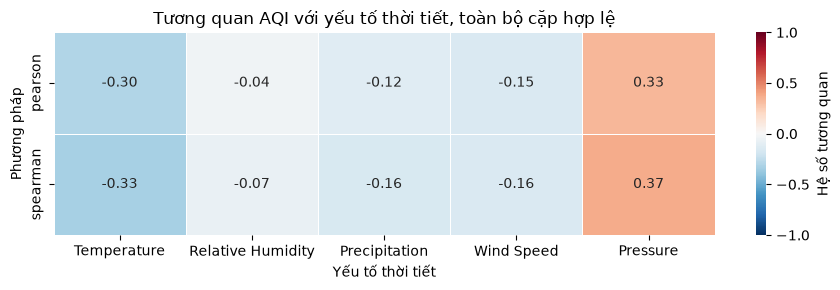

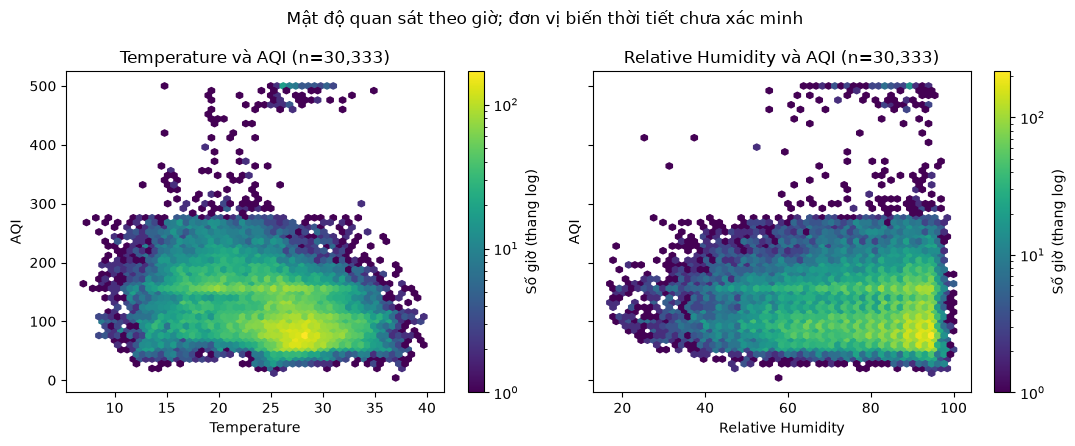

In [58]:
fig,ax=plt.subplots(figsize=(9,3))
sns.heatmap(q4_corr[['pearson','spearman']].T,annot=True,fmt='.2f',vmin=-1,vmax=1,center=0,cmap='RdBu_r',linewidths=.4,cbar_kws={'label':'Hệ số tương quan'},ax=ax)
ax.set(title='Tương quan AQI với yếu tố thời tiết, toàn bộ cặp hợp lệ',xlabel='Yếu tố thời tiết',ylabel='Phương pháp')
fig.tight_layout();fig.savefig(project_root/'output/figures/q4_weather_correlation_heatmap.png',dpi=160);plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4.5),sharey=True)
for ax,col in zip(axes,['Temperature','Relative Humidity']):
    pair=q4[['AQI',col]].dropna()
    hb=ax.hexbin(pair[col],pair['AQI'],gridsize=55,mincnt=1,bins='log',cmap='viridis')
    ax.set(title=f'{col} và AQI (n={len(pair):,})',xlabel=col,ylabel='AQI')
    fig.colorbar(hb,ax=ax,label='Số giờ (thang log)')
fig.suptitle('Mật độ quan sát theo giờ; đơn vị biến thời tiết chưa xác minh')
fig.tight_layout();fig.savefig(project_root/'output/figures/q4_temperature_humidity_hexbins.png',dpi=160);plt.show()

### Kết luận bước 7.3

Heatmap khớp bảng 7.2: Temperature âm mức vừa, Pressure dương mức vừa; Precipitation và Wind Speed âm yếu, Relative Humidity gần 0. Hai hexbin dùng đủ 30.333 cặp mỗi biến, thang màu log để đọc vùng dày. Với Temperature, vùng AQI thường gặp có xu hướng thấp hơn ở phía nhiệt độ cao nhưng phân tán rộng tại cùng một mức; với Relative Humidity, AQI phân tán rộng xuyên nhiều mức ẩm, không thấy một quan hệ tuyến tính rõ. Các giờ AQI=500 xuất hiện ở một số khoảng nhiệt độ/độ ẩm và cần kiểm tra độ nhạy sau. Biểu đồ không cho phép suy luận thời tiết gây ra thay đổi AQI.

### Bước 7.4 — AQI ở giờ mưa và không mưa

**Mục tiêu:** So sánh mức AQI quan sát ở giờ lượng mưa bằng 0 và lớn hơn 0.

**Lý do:** Đa số giờ không mưa nên tương quan liên tục có thể che sự khác biệt hai nhóm.

**Phương pháp:** Chia theo đúng giá trị 0 của Precipitation; tính count, mean, median, std và chênh nhóm.

**Kết quả cần quan sát:** Bảng hai nhóm với số giờ hợp lệ và độ lệch trung bình/trung vị.

In [59]:
rain_pair=q4[['AQI','Precipitation']].dropna().copy()
rain_pair['rain_group']=np.where(rain_pair['Precipitation']>0,'Có ghi nhận mưa','Không ghi nhận mưa')
rain_stats=rain_pair.groupby('rain_group')['AQI'].agg(['count','mean','median','std']).reindex(['Không ghi nhận mưa','Có ghi nhận mưa'])
print(rain_stats.round(3).to_string())
print('observed rain-minus-no-rain mean',round(rain_stats.iloc[1]['mean']-rain_stats.iloc[0]['mean'],3),'median',round(rain_stats.iloc[1]['median']-rain_stats.iloc[0]['median'],3))
print('total Precipitation=0 including AQI missing',int((q4['Precipitation']==0).sum()))

                    count     mean  median     std
rain_group                                        
Không ghi nhận mưa  25362  127.135   115.0  57.659
Có ghi nhận mưa      4971  106.701    94.0  54.879
observed rain-minus-no-rain mean -20.434 median -21.0
total Precipitation=0 including AQI missing 25365


### Kết luận bước 7.4

Trong 25.365 giờ Precipitation=0 có 25.362 giờ AQI hợp lệ; nhóm có ghi nhận mưa có 4.971 giờ AQI hợp lệ. AQI trung bình/trung vị ở nhóm không mưa là 127,135/115, so với 106,701/94 ở nhóm có mưa; chênh mưa trừ không mưa là −20,434 điểm trung bình và −21 điểm trung vị. Độ lệch chuẩn tương ứng 57,659 và 54,879. Đây là khác biệt AQI quan sát cùng giờ, có thể chịu ảnh hưởng của mùa, thời điểm và biến khác; không kết luận mưa làm AQI giảm. Ngưỡng nhóm là đúng giá trị 0 so với >0 của cột, không phải ngưỡng mưa tự đặt.

### Bước 7.5 — Nhóm phân vị tốc độ gió

**Mục tiêu:** So sánh AQI giữa các mức Wind Speed có số quan sát thực tế.

**Lý do:** Phân vị dữ liệu tạo nhóm có cơ sở và tránh tự đặt ngưỡng vật lý khi đơn vị chưa xác minh.

**Phương pháp:** Dùng qcut với duplicates="drop", ghi ranh giới và số quan sát; bảng thống kê và boxplot.

**Kết quả cần quan sát:** Bảng nhóm gió và biểu đồ phân phối AQI.

Wind Speed quartile boundaries {0.0: 0.0, 0.25: 1.0, 0.5: 2.0, 0.75: 2.1, 1.0: 14.9}
               count     mean  median     std
wind_group                                   
(-0.001, 1.0]   8361  132.435   123.0  59.786
(1.0, 2.0]     14330  125.325   113.0  58.252
(2.0, 2.1]       100  132.850   135.0  51.264
(2.1, 14.9]     7542  111.157   100.0  51.989


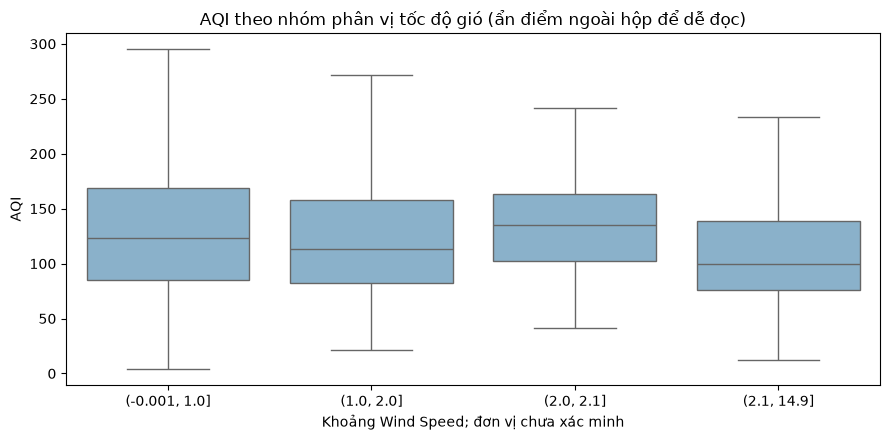

In [60]:
wind_pair=q4[['AQI','Wind Speed']].dropna().copy()
print('Wind Speed quartile boundaries',wind_pair['Wind Speed'].quantile([0,.25,.5,.75,1]).to_dict())
wind_pair['wind_group']=pd.qcut(wind_pair['Wind Speed'],q=4,duplicates='drop')
wind_stats=wind_pair.groupby('wind_group',observed=True)['AQI'].agg(['count','mean','median','std'])
print(wind_stats.round(3).to_string())
fig,ax=plt.subplots(figsize=(9,4.5))
sns.boxplot(data=wind_pair,x='wind_group',y='AQI',showfliers=False,color='#7fb3d5',ax=ax)
ax.set(title='AQI theo nhóm phân vị tốc độ gió (ẩn điểm ngoài hộp để dễ đọc)',xlabel='Khoảng Wind Speed; đơn vị chưa xác minh',ylabel='AQI')
fig.tight_layout();fig.savefig(project_root/'output/figures/q4_wind_groups.png',dpi=160);plt.show()

### Kết luận bước 7.5

Các mốc phân vị 0/25/50/75/100% của Wind Speed là 0; 1,0; 2,0; 2,1; 14,9. Do nhiều giá trị trùng quanh 2,0, `qcut` tạo nhóm (2,0;2,1] chỉ có 100 giờ, trong khi các nhóm còn lại có 8.361; 14.330; 7.542 giờ; không diễn giải nhóm hẹp 100 giờ như một tứ phân vị cân bằng. Nhóm >2,1 có AQI trung bình/trung vị 111,157/100, thấp hơn nhóm ≤1,0 (132,435/123), nhưng hai nhóm giữa không tạo một thứ tự giảm đều: (2,0;2,1] có trung bình 132,850. Boxplot đã ẩn điểm ngoài hộp để đọc phần trung tâm; bảng vẫn tính trên toàn bộ giờ và cực trị. Đây là so sánh quan sát, không chứng minh gió làm AQI thay đổi.

### Bước 7.6 — Nhóm phân vị nhiệt độ và độ ẩm

**Mục tiêu:** Kiểm tra mức AQI có thay đổi đơn điệu hay không giữa các nhóm nhiệt độ/độ ẩm.

**Lý do:** Một hệ số gộp nhỏ không loại trừ hình dạng cong; nhóm phân vị giúp xem trung bình/trung vị và cỡ mẫu.

**Phương pháp:** Chia mỗi biến thành tối đa bốn nhóm theo phân vị; tính cỡ mẫu, trung bình và trung vị AQI.

**Kết quả cần quan sát:** Hai bảng nhóm để so với Pearson/Spearman và hexbin.

In [61]:
q4_group_stats={}
for col in ['Temperature','Relative Humidity']:
    pair=q4[['AQI',col]].dropna().copy()
    pair['group']=pd.qcut(pair[col],q=4,duplicates='drop')
    stats=pair.groupby('group',observed=True)['AQI'].agg(['count','mean','median'])
    q4_group_stats[col]=stats
    print(col,'quartile boundaries',pair[col].quantile([0,.25,.5,.75,1]).to_dict())
    print(stats.round(3).to_string())

Temperature quartile boundaries {0.0: 7.0, 0.25: 20.9, 0.5: 25.7, 0.75: 28.9, 1.0: 40.0}
               count     mean  median
group                                
(6.999, 20.9]   7627  149.834   151.0
(20.9, 25.7]    7615  132.067   123.0
(25.7, 28.9]    7611  109.037    98.0
(28.9, 40.0]    7480  103.807    95.0
Relative Humidity quartile boundaries {0.0: 17.0, 0.25: 68.0, 0.5: 82.0, 0.75: 91.0, 1.0: 100.0}
                count     mean  median
group                                 
(16.999, 68.0]   8044  125.130   115.0
(68.0, 82.0]     7545  128.177   115.0
(82.0, 91.0]     8299  123.875   111.0
(91.0, 100.0]    6445  116.857   104.0


### Kết luận bước 7.6

Bốn nhóm phân vị Temperature có 7.480–7.627 giờ mỗi nhóm; AQI trung bình giảm theo thứ tự nhóm từ 149,834 ở khoảng ≤20,9 xuống 132,067, 109,037 và 103,807 ở khoảng >28,9; trung vị giảm từ 151 xuống 95. Điều này phù hợp dấu âm của Pearson/Spearman gộp, nhưng hình hexbin vẫn cho thấy độ phân tán lớn. Bốn nhóm Relative Humidity có 6.445–8.299 giờ; trung bình lần lượt 125,130; 128,177; 123,875; 116,857, không giảm đều từ nhóm đầu sang nhóm thứ hai, phù hợp hệ số gộp gần 0. Các ranh giới đều lấy từ phân vị thực tế, không phải ngưỡng vật lý; cần xem theo mùa trước khi diễn giải.

### Bước 7.7 — Tương quan theo năm và nhóm mùa

**Mục tiêu:** Xem liên hệ gộp có ổn định giữa các năm và mùa hay không.

**Lý do:** Cùng thay đổi theo mùa có thể gây nhiễu cho hệ số gộp; 2025 chỉ sáu tháng.

**Phương pháp:** Dùng Local Time, quy ước xuân 3–5/hè 6–8/thu 9–11/đông 12–2; tính cặp hợp lệ và Pearson/Spearman theo năm và theo mùa 2022–2024.

**Kết quả cần quan sát:** Bảng năm, mùa và cỡ mẫu cho các biến chính cùng Pressure.

In [62]:
q4['year']=q4['Local Time'].dt.year
q4['season']=q4['Local Time'].dt.month.map(season_map)
def correlations_by_group(data,group_col):
    rows=[]
    for group,frame in data.groupby(group_col):
        for col in weather+weather_extra:
            pair=frame[['AQI',col]].dropna()
            rows.append({group_col:group,'variable':col,'n_pairs':len(pair),'pearson':pair['AQI'].corr(pair[col]),'spearman':pair['AQI'].corr(pair[col],method='spearman')})
    return pd.DataFrame(rows)
q4_year_corr=correlations_by_group(q4,'year')
q4_season_corr=correlations_by_group(q4.loc[q4['year'].between(2022,2024)],'season')
print('PEARSON BY YEAR');print(q4_year_corr.pivot(index='year',columns='variable',values='pearson')[weather+weather_extra].round(3).to_string())
print('SPEARMAN BY YEAR');print(q4_year_corr.pivot(index='year',columns='variable',values='spearman')[weather+weather_extra].round(3).to_string())
print('PEARSON BY SEASON 2022-2024');print(q4_season_corr.pivot(index='season',columns='variable',values='pearson')[weather+weather_extra].reindex(season_order).round(3).to_string())
print('SPEARMAN BY SEASON 2022-2024');print(q4_season_corr.pivot(index='season',columns='variable',values='spearman')[weather+weather_extra].reindex(season_order).round(3).to_string())
print('VALID PAIRS BY SEASON');print(q4_season_corr.pivot(index='season',columns='variable',values='n_pairs')[weather+weather_extra].reindex(season_order).to_string())
print('2025 months',sorted(q4.loc[q4['year']==2025,'Local Time'].dt.month.unique().tolist()))

PEARSON BY YEAR
variable  Temperature  Relative Humidity  Precipitation  Wind Speed  Pressure
year                                                                         
2022           -0.340              0.011         -0.135      -0.253     0.358
2023           -0.400             -0.097         -0.097      -0.163     0.428
2024           -0.202             -0.040         -0.137      -0.055     0.260
2025           -0.225             -0.053         -0.091      -0.241     0.234
SPEARMAN BY YEAR
variable  Temperature  Relative Humidity  Precipitation  Wind Speed  Pressure
year                                                                         
2022           -0.340             -0.019         -0.131      -0.246     0.379
2023           -0.374             -0.135         -0.130      -0.151     0.397
2024           -0.299             -0.088         -0.247      -0.089     0.382
2025           -0.207             -0.037         -0.116      -0.247     0.238
PEARSON BY SEASON 2022-2024
var

### Kết luận bước 7.7

Theo từng năm, Temperature giữ dấu âm Pearson (−0,400 đến −0,202), Pressure giữ dấu dương (+0,234 đến +0,428), Precipitation giữ dấu âm (−0,137 đến −0,091), Wind Speed giữ dấu âm (−0,253 đến −0,055); Relative Humidity gần 0, năm 2022 hơi dương +0,011. Tuy nhiên khi chia mùa 2022–2024, Temperature Pearson chỉ −0,043 xuân, +0,128 hè, −0,295 thu, −0,032 đông; Pressure +0,051 xuân, −0,060 hè, +0,350 thu, +0,065 đông. Vì vậy độ lớn và thậm chí chiều của hệ số gộp không ổn định theo mùa, phù hợp khả năng các biến cùng biến động theo mùa. Wind Speed vẫn âm ở cả bốn mùa, mạnh hơn ở đông (−0,325) và thu (−0,228); Precipitation âm ở xuân/hè/thu nhưng đông +0,027 gần 0. Mỗi nhóm mùa có 6.191–6.624 cặp hợp lệ; nhóm đông có thiếu ngày theo kết quả Câu hỏi 2. Năm 2025 chỉ có tháng 1–6, không đại diện mùa thu và cuối đông của năm.

### Bước 7.8 — Độ nhạy với AQI = 500

**Mục tiêu:** Kiểm tra cực trị AQI của 2024 có đổi đáng kể các liên hệ thời tiết hay không.

**Lý do:** Các giờ AQI=500 tập trung năm 2024 và có thể làm thay đổi hệ số trên giá trị gốc.

**Phương pháp:** Lọc tạm 59 giờ trong 2024, tính lại Pearson/Spearman; không ghi đè dữ liệu.

**Kết quả cần quan sát:** Bảng trước/sau cho năm 2024 và mức thay đổi lớn nhất.

In [63]:
base=q4.loc[q4['year']==2024]
alternative=base.loc[base['AQI']!=500]
q4_sensitivity=[]
for col in weather+weather_extra:
    a=base[['AQI',col]].dropna();b=alternative[['AQI',col]].dropna()
    q4_sensitivity.append({'variable':col,'n_original':len(a),'n_without500':len(b),'pearson_original':a['AQI'].corr(a[col]),'pearson_without500':b['AQI'].corr(b[col]),'spearman_original':a['AQI'].corr(a[col],method='spearman'),'spearman_without500':b['AQI'].corr(b[col],method='spearman')})
q4_sensitivity=pd.DataFrame(q4_sensitivity).set_index('variable')
q4_sensitivity['pearson_change']=q4_sensitivity['pearson_without500']-q4_sensitivity['pearson_original']
q4_sensitivity['spearman_change']=q4_sensitivity['spearman_without500']-q4_sensitivity['spearman_original']
print(q4_sensitivity.round(4).to_string())
print('temporarily filtered hours',int((base['AQI']==500).sum()),'main data retained')

                   n_original  n_without500  pearson_original  pearson_without500  spearman_original  spearman_without500  pearson_change  spearman_change
variable                                                                                                                                                  
Temperature              8783          8724           -0.2023             -0.2451            -0.2994              -0.3069         -0.0428          -0.0075
Relative Humidity        8783          8724           -0.0403             -0.0557            -0.0884              -0.0902         -0.0154          -0.0018
Precipitation            8783          8724           -0.1366             -0.1448            -0.2467              -0.2451         -0.0082           0.0016
Wind Speed               8783          8724           -0.0547             -0.0822            -0.0885              -0.0958         -0.0275          -0.0073
Pressure                 8783          8724            0.2598         

### Kết luận bước 7.8

Khi tạm lọc 59 giờ AQI=500 năm 2024, Pearson Pressure tăng từ +0,2598 lên +0,3107 (Δ+0,0509), Temperature từ −0,2023 xuống −0,2451 (Δ−0,0428), Wind Speed từ −0,0547 xuống −0,0822 (Δ−0,0275); các hệ số còn lại thay đổi ≤0,0154. Theo ngưỡng mô tả |r|=0,3, Pressure năm 2024 chuyển từ nhóm yếu sang vừa, nên nhãn mức độ của riêng năm này nhạy với cực trị. Spearman của cả năm biến thay đổi không quá 0,0076; chiều hệ số không đổi. Đây chỉ là phép lọc tạm để đánh giá độ nhạy, không xác định AQI=500 là sai và không thay đổi dữ liệu chính.

### Bước 7.9 — Bằng chứng trả lời Câu hỏi 4

**Mục tiêu:** Tổng hợp các hệ số, khác biệt nhóm và tính ổn định để trả lời trực tiếp.

**Lý do:** Kết luận phải phản ánh cả dữ liệu gộp lẫn năm/mùa, không suy luận tác động nhân quả.

**Phương pháp:** In xếp hạng trị tuyệt đối hệ số, chênh mưa–không mưa, nhóm gió và các hệ số theo mùa.

**Kết quả cần quan sát:** Bảng chứng cứ ngắn cho kết luận cuối.

In [64]:
print('GLOBAL |PEARSON|');print(q4_corr['pearson'].abs().sort_values(ascending=False).round(3).to_string())
print('GLOBAL |SPEARMAN|');print(q4_corr['spearman'].abs().sort_values(ascending=False).round(3).to_string())
print('RAIN mean difference',round(rain_stats.iloc[1]['mean']-rain_stats.iloc[0]['mean'],3),'median difference',round(rain_stats.iloc[1]['median']-rain_stats.iloc[0]['median'],3))
print('WIND GROUP mean range',round(wind_stats['mean'].min(),3),round(wind_stats['mean'].max(),3))
print('YEAR PEARSON min/max');print(q4_year_corr.groupby('variable')['pearson'].agg(['min','max']).reindex(weather+weather_extra).round(3).to_string())
print('SEASON PEARSON');print(q4_season_corr.pivot(index='season',columns='variable',values='pearson')[weather+weather_extra].reindex(season_order).round(3).to_string())
print('MAX |SENSITIVITY|',q4_sensitivity['pearson_change'].abs().idxmax(),round(q4_sensitivity['pearson_change'].abs().max(),3))

GLOBAL |PEARSON|
variable
Pressure             0.333
Temperature          0.301
Wind Speed           0.152
Precipitation        0.120
Relative Humidity    0.044
GLOBAL |SPEARMAN|
variable
Pressure             0.374
Temperature          0.335
Precipitation        0.156
Wind Speed           0.156
Relative Humidity    0.074
RAIN mean difference -20.434 median difference -21.0
WIND GROUP mean range 111.157 132.85
YEAR PEARSON min/max
                     min    max
variable                       
Temperature       -0.400 -0.202
Relative Humidity -0.097  0.011
Precipitation     -0.137 -0.091
Wind Speed        -0.253 -0.055
Pressure           0.234  0.428
SEASON PEARSON
variable  Temperature  Relative Humidity  Precipitation  Wind Speed  Pressure
season                                                                       
Xuân           -0.043             -0.005         -0.089      -0.090     0.051
Hè              0.128             -0.071         -0.059      -0.074    -0.060
Thu            

### Kết luận bước 7.9

**Trả lời Câu hỏi 4:** Trên toàn bộ 30.333 cặp giờ hợp lệ, trong bốn yếu tố trọng tâm Temperature có liên hệ âm đáng chú ý nhất với AQI (Pearson −0,3014; Spearman −0,3349). Pressure là biến bổ sung có hệ số dương lớn nhất về trị tuyệt đối (+0,3327; +0,3736). Wind Speed âm yếu (−0,1520; −0,1558), Precipitation âm yếu (−0,1201; −0,1564), Relative Humidity gần 0 (−0,0437; −0,0735). Giờ có ghi nhận mưa có AQI trung bình 106,701 so với 127,135 ở giờ không mưa (chênh −20,434); nhóm Wind Speed >2,1 có trung bình 111,157 so với 132,435 ở nhóm ≤1,0, nhưng nhóm phân vị (2,0;2,1] chỉ 100 giờ và thứ tự không giảm đều. Bốn nhóm Temperature có AQI trung bình 149,834→103,807 từ thấp đến cao, còn các nhóm độ ẩm không tạo xu thế đều. Theo năm, Temperature âm và Pressure dương trong cả bốn năm; song theo mùa 2022–2024 Temperature gần 0 ở xuân/đông và dương nhẹ ở hè (+0,128), Pressure gần 0 ở xuân/đông, âm nhẹ ở hè (−0,060), dương rõ hơn ở thu (+0,350). Vì vậy hệ số gộp chịu ảnh hưởng của cấu trúc mùa; không khẳng định tác động nhân quả. Lọc tạm AQI=500 năm 2024 làm Pearson Pressure tăng 0,0509 nhưng không đổi dấu; dữ liệu chính giữ nguyên. Giới hạn: quy ước mùa theo lịch, thiếu ngày ở một số tháng, 2025 chỉ đến tháng 6, chưa xác minh đơn vị và chưa kiểm soát yếu tố gây nhiễu.

## Giai đoạn 8 — Tổng kết và bàn giao Notebook 1

### Bước 8.1 — Kiểm tra file đầu ra cho dự đoán

**Mục tiêu:** Xác nhận cấu trúc, thời gian, AQI thiếu và khoảng giờ không có bản ghi của file đã làm sạch.

**Lý do:** Notebook 2 cần biết ngày đủ giờ và ngày thiếu trước khi tạo AQI trung bình ngày, tránh dùng ngày không quan sát được như dữ liệu thật.

**Phương pháp:** Đọc lại CSV với hai cột thời gian được parse; đối chiếu chuỗi giờ kỳ vọng, số giờ AQI hợp lệ theo ngày và kích thước bốn file gốc. Chỉ kiểm tra, không ghi dữ liệu.

**Kết quả cần quan sát:** Số dòng/cột, tên/kiểu cột, phạm vi thời gian, giờ thiếu và ngày có AQI không đủ 24 giờ.

In [65]:
handoff=pd.read_csv(project_root/'output/data/aqi_hanoi_cleaned.csv',parse_dates=['Local Time','UTC Time'])
print('RAW CSV ROWS', {year:len(pd.read_csv(project_root/f'dataset/{year}.csv')) for year in range(2022,2026)})
print('CLEAN SHAPE',handoff.shape)
print('COLUMNS',handoff.columns.tolist())
print('DTYPES');print(handoff.dtypes.to_string())
print('LOCAL RANGE',handoff['Local Time'].min(),handoff['Local Time'].max())
print('AQI MISSING',int(handoff['AQI'].isna().sum()))
print('UNIQUE LOCAL HOURS',handoff['Local Time'].nunique(),'DUPLICATE LOCAL HOURS',int(handoff['Local Time'].duplicated().sum()))
expected=pd.date_range(handoff['Local Time'].min(),handoff['Local Time'].max(),freq='h')
missing_hours=expected.difference(pd.DatetimeIndex(handoff['Local Time']))
print('MISSING HOURS INSIDE OBSERVED RANGE',len(missing_hours),'FIRST',missing_hours.min() if len(missing_hours) else None,'LAST',missing_hours.max() if len(missing_hours) else None)
daily_aqi=handoff.groupby(handoff['Local Time'].dt.normalize())['AQI'].agg(recorded_hours='size',valid_aqi_hours='count')
print('OBSERVED DAYS WITH <24 VALID AQI HOURS');print(daily_aqi.loc[daily_aqi['valid_aqi_hours']<24].to_string())
print('ALL-NA ROWS',int(handoff.isna().all(axis=1).sum()),'TOTAL MISSING CELLS',int(handoff.isna().sum().sum()))

RAW CSV ROWS {2022: 8472, 2023: 8736, 2024: 8788, 2025: 4345}
CLEAN SHAPE (30336, 19)
COLUMNS ['Local Time', 'UTC Time', 'City', 'Country code', 'timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']
DTYPES
Local Time                datetime64[us]
UTC Time             datetime64[us, UTC]
City                                 str
Country code                         str
timezone                             str
AQI                              float64
CO                               float64
NO2                              float64
O3                               float64
PM10                             float64
PM25                             float64
SO2                              float64
Clouds                           float64
Precipitation                    float64
Pressure                         float64
Relative Humidity                float64
Temperature                   

### Kết luận bước 8.1

Bốn CSV gốc lần lượt có 8.472, 8.736, 8.788 và 4.345 dòng, tổng 30.341. File đã làm sạch đọc lại có 30.336 dòng × 19 cột, 30.336 giờ Local Time duy nhất, không còn giờ trùng; phạm vi 13/01/2022 00:00 đến 30/06/2025 23:00. Hai cột thời gian được parse thành `datetime64` (UTC Time có múi giờ UTC); các cột AQI/chất ô nhiễm/thời tiết là `float64`, định danh là `str` khi đọc với pandas hiện tại. Có 315 ô thiếu, gồm 3 ô AQI; không có dòng thiếu toàn bộ. Trong khoảng quan sát chỉ thiếu trọn 24 giờ ngày 31/12/2023, không được tự tạo. Hai ngày có bản ghi nhưng AQI dưới 24 giờ là 01/07/2022 (22/24) và 01/12/2024 (23/24). Notebook 2 cần dựa trên số giờ AQI hợp lệ để quyết định ngày dùng được, giữ ngày thiếu riêng, tạo đặc trưng chỉ từ AQI quá khứ và chia train/validation/test theo thời gian; không dùng biến tương lai không sẵn có.

## Tổng kết bốn câu hỏi nghiên cứu

Các kết luận dưới đây tóm tắt **kết quả đã tính trong các bước 4.1–7.9**, không thay thế bảng chi tiết hoặc các phép đối chiếu độ nhạy. AQI là chỉ số của dữ liệu nguồn; đơn vị của các cột chất ô nhiễm và thời tiết, nguồn trạm và công thức AQI chưa được xác minh.

### Câu hỏi 1 — AQI thay đổi giữa các năm trong hai nửa năm

Trong khoảng chung **13/01–30/06**, đã bỏ 29/02/2024 khỏi so sánh chính, AQI trung bình 2022–2025 lần lượt là **125,828; 121,880; 119,832; 138,409** (mỗi năm 4.056 giờ hợp lệ). Từ 2022 đến 2024 mức trung bình giảm, rồi tăng ở 2025. Trong khoảng **01/07–30/12** của 2022–2024, các trung bình là **112,746; 121,126; 118,775**: tăng ở 2023 rồi giảm ở 2024. Do đó, thay đổi 2022→2023 **ngược chiều** giữa hai nửa, còn 2023→2024 đều giảm. Không có nửa cuối 2025 để so sánh.

**Độ nhạy:** 59 giờ AQI=500 ở nửa đầu 2024 làm trung bình khoảng này cao hơn **5,6117** điểm so với phép tính lọc tạm; trung vị chỉ khác 1 điểm. Thứ tự các năm và chiều thay đổi không đổi, nhưng độ lớn chênh lệch liên quan 2024 nhạy với cực trị. Các giờ AQI=500 vẫn thuộc dữ liệu chính vì chưa được xác minh là sai. Hai nửa có **169 và 183 ngày**; chỉ so sánh mức trung bình trong từng khoảng, không suy luận nguyên nhân hoặc xu hướng dài hạn.

### Câu hỏi 2 — Mẫu hình theo tháng và mùa

Trong 2022–2024, **tháng 7 thấp nhất** ở cả ba năm, với AQI trung bình **83,26; 84,75; 68,54**. Nhóm hè theo quy ước tháng 6–8 cũng thấp nhất (**87,16; 90,13; 82,83**). Tháng cao nhất là tháng 1 ở 2022–2023 nhưng tháng 4 ở 2024; nhóm mùa cao nhất là đông ở 2022–2023 và xuân ở 2024. Tương quan Spearman của thứ hạng 12 tháng giữa từng cặp năm là **0,888; 0,692; 0,720**: mẫu hình **lặp lại một phần**, rõ hơn ở giai đoạn thấp.

Tháng 04/2024 có **58/59** giờ AQI=500; lọc tạm làm đỉnh 2024 chuyển sang tháng 12 và nhóm mùa cao nhất chuyển sang đông. Tháng 01/2022 chỉ có **61,29%** giờ lịch và tháng 12/2023 có **96,77%**, làm giảm độ chắc chắn của so sánh đỉnh. Năm 2025 chỉ có tháng 1–6. Nhóm đông gộp tháng 1–2 và 12 trong cùng năm dương lịch, không biểu thị một mùa đông liên tục.

### Câu hỏi 3 — AQI và chất ô nhiễm

PM25 và PM10 có liên hệ thống kê dương mạnh nhất với AQI. **Pearson:** PM10 **0,8195**, PM25 **0,8107**; **Spearman:** PM25 **0,9850**, PM10 **0,9545**. O3 yếu nhất theo trị tuyệt đối ở cả hai (Pearson **−0,0099**, Spearman **−0,0017**). NO2/SO2 dương yếu trên dữ liệu gộp; CO gần 0 theo Pearson (**−0,0176**) và dương yếu theo Spearman (**0,1076**). PM25/PM10 giữ chiều dương mạnh qua từng năm; các chất khác biến thiên hơn.

Lọc tạm AQI=500 năm 2024 làm Pearson PM25 tăng từ **0,7163 lên 0,8017**, nhưng không đổi nhận định về PM25/PM10. Có **791 giờ** AQI bằng số PM25; khả năng AQI được xây dựng từ chỉ số chất ô nhiễm cần tài liệu nguồn để xác nhận. Tương quan cao hoặc giá trị bằng nhau không chứng minh công thức hay quan hệ nhân quả.

### Câu hỏi 4 — AQI và yếu tố thời tiết

Trong bốn biến trọng tâm, Temperature có liên hệ âm đáng chú ý nhất (Pearson **−0,3014**, Spearman **−0,3349**). Pressure, được bổ sung để đối chiếu, có hệ số dương lớn nhất về trị tuyệt đối (Pearson **0,3327**, Spearman **0,3736**). Precipitation và Wind Speed âm yếu; Relative Humidity gần 0. Giờ có ghi nhận mưa có AQI trung bình **106,701**, so với **127,135** ở giờ không ghi nhận mưa (chênh **−20,434**).

Theo năm, Temperature vẫn âm và Pressure vẫn dương; theo nhóm mùa 2022–2024, Temperature gần 0 ở xuân/đông và dương nhẹ ở hè (**+0,128**), Pressure âm nhẹ ở hè (**−0,060**) nhưng dương rõ hơn ở thu (**+0,350**). Vì vậy hệ số gộp có thể chịu ảnh hưởng của cấu trúc mùa. Một nhóm gió theo phân vị chỉ có **100 giờ** do nhiều giá trị trùng; không suy rộng từ nhóm này. Lọc tạm AQI=500 làm Pearson Pressure 2024 tăng **0,0509** nhưng không đổi dấu. Khác biệt nhóm và tương quan không chứng minh thời tiết gây thay đổi AQI.

### Bảng tóm tắt để báo cáo

| Câu hỏi | Phương pháp | Kết quả chính | Kết luận | Giới hạn quan trọng |
|---|---|---|---|---|
| 1. So sánh hai nửa năm | Cùng tập ngày lịch, trung bình/trung vị, độ nhạy AQI=500 | Nửa đầu 2022→2024 giảm rồi 2025 tăng; nửa cuối 2022→2023 tăng rồi 2024 giảm | Biến động không đồng nhất giữa hai nửa | 2025 không có nửa cuối; nửa đầu 2024 nhạy với 59 giờ AQI=500 |
| 2. Tháng và mùa | Bảng năm×tháng, nhóm mùa, Spearman thứ hạng, độ nhạy | Tháng 7 và hè thấp nhất cả 2022–2024; Spearman 0,692–0,888 | Mẫu hình lặp lại một phần | 01/2022 và 12/2023 thiếu ngày; đỉnh 2024 nhạy AQI=500 |
| 3. Chất ô nhiễm | Pearson/Spearman theo cặp và năm; hexbin | PM10 Pearson 0,8195; PM25 Spearman 0,9850 | PM25/PM10 liên hệ dương mạnh và ổn định nhất | Công thức AQI và đơn vị chất ô nhiễm chưa xác minh; không suy nhân quả |
| 4. Thời tiết | Pearson/Spearman, nhóm mưa/gió/nhiệt/ẩm, theo năm/mùa | Temperature Pearson −0,3014; Pressure +0,3327; giờ mưa thấp hơn 20,434 điểm trung bình | Liên hệ gộp thay đổi theo mùa | Chưa kiểm soát yếu tố gây nhiễu; nhóm gió hẹp; đơn vị chưa xác minh |

### Dữ liệu và các quyết định xử lý

Bốn CSV gốc có **30.341 dòng** (2022: 8.472; 2023: 8.736; 2024: 8.788; 2025: 4.345), mỗi file 19 cột nhưng hai tên cột định danh khác cách viết giữa các năm. Có **5 cặp bản ghi trùng giờ với giá trị xung đột** và **302 ô thiếu gốc**. Sau chuẩn hóa, mỗi giờ chỉ giữ một bản ghi: cột đồng thuận giữ nguyên, **13 ô bất đồng được đặt NaN** và ghi tại `output/tables/duplicate_conflicts_audit.csv`. Không chọn dòng đầu/cuối hoặc lấy trung bình. File `output/data/aqi_hanoi_cleaned.csv` có **30.336 dòng × 19 cột, 30.336 giờ duy nhất, 315 ô thiếu**; không mất mốc giờ do giải quyết trùng.

Giữ các NaN thay vì điền qua cụm thiếu **74 giờ** của CO/NO2/O3/SO2 năm 2022; hai giờ AQI thiếu ngày 01/07/2022 và một giờ AQI thiếu ngày 01/12/2024 cũng được giữ. Không tạo dữ liệu cho **31/12/2023**. Giữ AQI=500 và các cực trị chưa xác minh, dùng lọc tạm chỉ để đánh giá độ nhạy. Dữ liệu bắt đầu **13/01/2022**, năm 2025 kết thúc **30/06/2025**; đơn vị một số biến, trạm đo và công thức AQI chưa được xác minh.

### Lưu ý bàn giao cho Notebook 2

File đã làm sạch đọc lại có đủ **19 cột**; AQI thiếu **3 giờ**. Khoảng trống duy nhất **bên trong phạm vi quan sát** là 24 giờ của **31/12/2023**. Hai ngày có bản ghi nhưng AQI không đủ 24 giờ là **01/07/2022 (22/24)** và **01/12/2024 (23/24)**. Trước khi tạo AQI trung bình ngày, cần xác định quy tắc tối thiểu số giờ hợp lệ, không lấp ngày không có bản ghi, và đảm bảo các ngày đưa vào cặp đặc trưng–mục tiêu liên tiếp theo lịch. Dự đoán AQI trung bình ngày kế tiếp chỉ dùng AQI quá khứ đã có khi dự đoán; chia train/validation/test theo thời gian, fit mọi bước học tham số trên train và tránh dùng dữ liệu tương lai. Không đưa chất ô nhiễm hoặc thời tiết tương lai vào đầu vào khi không có sẵn.

**Phạm vi hoàn thành:** Notebook 1 trả lời bốn câu hỏi trên dữ liệu quan sát đã làm sạch. Phần dự đoán sẽ được thực hiện riêng sau khi người dùng xác nhận; chưa có mô hình hoặc kết quả dự đoán.